# Google Mumbai Air Quality Forecasting Challenge — 100% Self-Contained Winning Solution (Colab & Local)
**Competition:** Google Mumbai Data Challenge (Zindi & ClimateVerse)  
**Evaluation Metric:** Root Mean Squared Error (RMSE, µg/m³)  
**Architecture:** 8-Model Physics-Guided + Spatiotemporal Graph + Pretrained Foundation Model (`TimesFM 3.0` + `Chronos-2`) Stacked Ensemble

### Highlights of the 8-Model Winning Architecture
1. **Model 1 (`CalibratedDiurnalCAMSPriorForecaster`)**: `TimeMixer`-inspired Synoptic-Diurnal Decomposition with bounded $\tanh$-saturating CAMS MOS multiplier, hygroscopic (`RH > 68%`) & boundary-layer (`PBLH`) spike damping, and `AirPhyNet` upwind advection-diffusion PDE flux coupling.
2. **Model 2 (`HuberRidgePhysicsGAMForecaster`)**: Dual-scale additive periodic spline GAM (`Ridge` + `HuberRegressor`) + multiplicative Log-Ratio Ridge GAM with **Duan's Smearing Estimator** + non-parametric **Historical Meteorological Analog Ensemble (`AnEn`)**.
3. **Models 3, 4, 5 (`LightGBM`, `CatBoost`, `XGBoost` Residual Zoo)**: Dual-objective L2 (`RMSE`) + `Huber` gradient boosted trees with 100% deterministic single-thread execution (`deterministic=True, force_col_wise=True, n_jobs=1`, `thread_count=1`).
4. **Model 6 (`WindGuidedSTGATForecaster`)**: PyTorch Wind-Guided Spatiotemporal Graph Attention Network across the 4 Mumbai target stations (`11606` Borivali East, `11611` Malad West, `3409510` Byculla, `3409511` Shivaji Nagar).
5. **Model 7 (`TimesFM3CompactForecaster` — `google/timesfm-3.0-pytorch`)**: Compact Multi-View (`V=4` Pure Target Multivariate + `V=12` Physics-Coupled Multivariate) across `context_len ∈ {256, 512}` with RMSE-optimal decile expectation and Post-Hoc Synoptic-Diurnal Physics Ratio Calibration.
6. **Model 8 (`Chronos2CovariateForecaster` — `amazon/chronos-2`)**: Multivariate `GroupSelfAttention` (`cross_learning=True`) with `past_covariates` & `future_covariates` (`cams_pm25_cal`, `log1p_vc`, `log_pblh`) and 21-quantile Trapezoidal Conditional Expectation.
7. **Meta-Learner (`StackedAirQualityEnsemble`)**: Non-negative SLSQP + Nelder-Mead simplex weights with **Station-Specific & Horizon-Decaying Variance Shrinkage $\alpha_s(h_{\text{lead}})$**.

In [1]:
%matplotlib inline
import os
import sys
import json
import random
import subprocess
from pathlib import Path

os.environ["HF_HUB_DISABLE_XET"] = "1"
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB:
    print("[Colab] Installing timesfm[torch]==3.0.2, chronos-forecasting, lightgbm, catboost, xgboost, zindi...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "timesfm[torch]==3.0.2", "chronos-forecasting>=2.3.2",
        "lightgbm", "catboost", "xgboost", "zindi", "huggingface_hub"
    ])

import lightgbm
import xgboost
import catboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from timesfm3 import TimesFM3Forecaster, TimesFM3Evaluator, ModelConfig
from chronos import Chronos2Pipeline, ChronosBoltPipeline

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Auto-download competition dataset bundle via HuggingFace Hub if running in a fresh Colab runtime
if not (PROJECT_ROOT / "data" / "raw" / "Train.csv").exists():
    from huggingface_hub import snapshot_download
    print("[Colab] Downloading Mumbai Air Quality dataset bundle from HuggingFace Hub...")
    snapshot_download(
        repo_id="han-jisso/google-mumbai-air-quality-challenge",
        repo_type="dataset",
        local_dir=str(PROJECT_ROOT / "data"),
    )

print(f"IN_COLAB={IN_COLAB} | PROJECT_ROOT={PROJECT_ROOT}")
print("Verified imports: TimesFM3Forecaster, Chronos2Pipeline, LightGBM, CatBoost, XGBoost, PyTorch")

W1108 00:23:08.804000 50176 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


IN_COLAB=False | PROJECT_ROOT=/Volumes/MacExt/Projects/google-mumbai-air-quality
Verified imports: TimesFM3Forecaster, Chronos2Pipeline, LightGBM, CatBoost, XGBoost, PyTorch


## 2. Self-Contained Pipeline Bootstrap
If running standalone on Google Colab without a pre-cloned `src/` directory, the cell below materializes the complete modular pipeline (`src/validation.py`, `src/features.py`, `src/models/priors_and_linear.py`, `src/models/gbdt_zoo.py`, `src/models/st_gat.py`, `src/models/foundation_ts.py`, `src/ensemble.py`, `src/submit.py`) directly into `PROJECT_ROOT / "src"`.

In [2]:
# Materialize self-contained src/ modules if absent (for standalone Colab execution)
PIPELINE_FILES = {'src/__init__.py': '"""Google Mumbai Air Quality Forecasting Pipeline."""\n', 'src/models/__init__.py': '"""Model Zoo for Google Mumbai Air Quality Challenge."""\n', 'src/validation.py': '#!/usr/bin/env python3\n"""\nValidation & Target Cleaning Module (`src/validation.py`)\nfor the Google Mumbai Air Quality Forecasting Challenge.\n\nImplements:\n1. Strict IST (`Asia/Kolkata`, UTC+05:30) timestamp alignment between `Train.csv`\n   (`hour_end = timestamp_ist`, `hour_start = hour_end - 1h`) and `Test.csv`\n   (`hour_start = target_start_ist`, `hour_end = target_end_ist`).\n2. 2-Stage Target Outlier Cleaner (`clean_pm25`) for training targets:\n   - Stage 1: Flag/replace extreme physical sensor glitches (`flag_high_1000 == True`\n     or `pm25 > 450.0 ug/m3`).\n   - Stage 2: Rolling 7-hour Hampel filter per station (replace spikes > 4.5 * MAD\n     above the rolling median with interpolated rolling median).\n3. 5-Fold Post-Monsoon Rolling 48-hour Validation Split (`get_rolling_validation_splits`)\n   across all 4 target stations, supporting both short reporting gaps (24h-48h,\n   matching Nov 10 -> Nov 11-12 Private evaluation) and medium gaps (72h, matching\n   the Starter Notebook), plus optional Oct/Nov 2025 historical post-monsoon folds.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.ensemble import RandomForestRegressor\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent\nRAW_DIR = PROJECT_ROOT / "data" / "raw"\nIST_TZ = "Asia/Kolkata"\n\n# Post-monsoon October 2026 48-hour validation windows (each 48h across all 4 stations)\nDEFAULT_OCT2026_WINDOWS: list[tuple[str, str]] = [\n    ("2026-10-12 00:00:00", "2026-10-14 00:00:00"),\n    ("2026-10-14 00:00:00", "2026-10-16 00:00:00"),\n    ("2026-10-16 00:00:00", "2026-10-18 00:00:00"),\n    ("2026-10-18 00:00:00", "2026-10-20 00:00:00"),\n    ("2026-10-20 00:00:00", "2026-10-22 00:00:00"),\n]\n\n# Post-monsoon Oct/Nov 2025 48-hour validation windows ( matching Nov 11-12 Private season)\nNOV2025_WINDOWS: list[tuple[str, str]] = [\n    ("2025-10-28 00:00:00", "2025-10-30 00:00:00"),\n    ("2025-11-02 00:00:00", "2025-11-04 00:00:00"),\n    ("2025-11-06 00:00:00", "2025-11-08 00:00:00"),\n    ("2025-11-11 00:00:00", "2025-11-13 00:00:00"),\n]\n\n\n@dataclass\nclass ValidationFold:\n    """Represents a single leak-free 48-hour rolling validation split."""\n\n    fold_id: int\n    name: str\n    cutoff_t0: pd.Timestamp\n    val_start: pd.Timestamp\n    val_end: pd.Timestamp\n    gap_hours: int\n    train_df: pd.DataFrame\n    val_df: pd.DataFrame\n\n\ndef rmse(actual: np.ndarray | pd.Series, predicted: np.ndarray | pd.Series) -> float:\n    """Compute Root Mean Squared Error (RMSE)."""\n    a = np.asarray(actual, dtype=float)\n    p = np.asarray(predicted, dtype=float)\n    mask = np.isfinite(a) & np.isfinite(p)\n    return float(np.sqrt(np.mean((a[mask] - p[mask]) ** 2)))\n\n\ndef as_ist(values: pd.Series | Any) -> pd.Series:\n    """Convert timestamps to Asia/Kolkata (UTC+05:30)."""\n    return pd.to_datetime(values, utc=True).dt.tz_convert(IST_TZ)\n\n\ndef clean_pm25(\n    df: pd.DataFrame,\n    target_col: str = "pm25",\n    cap_ugm3: float = 450.0,\n    hampel_window: int = 7,\n    hampel_mad_mult: float = 4.5,\n) -> pd.DataFrame:\n    """\n    2-Stage Target Outlier Cleaner for training PM2.5 observations:\n      - Stage 1: Flag extreme physical sensor glitches (`flag_high_1000 == True`\n        or `pm25 > cap_ugm3` = 450.0 ug/m3) and replace with local station rolling\n        median / time-interpolated values (capped at `cap_ugm3`).\n      - Stage 2: Rolling 7-hour Hampel filter per station (`pm25 - rolling_median > 4.5 * MAD`),\n        replacing isolated transient sensor spikes with the rolling median.\n\n    Returns a copy of `df` with:\n      - `pm25_raw`: original raw PM2.5\n      - `pm25_clean`: cleaned PM2.5\n      - `is_glitch_stage1`: boolean flag for Stage 1 extreme glitches\n      - `is_spike_stage2`: boolean flag for Stage 2 Hampel spikes\n      - `is_outlier`: boolean union of Stage 1 and Stage 2\n    """\n    out = df.copy()\n    out = out.sort_values(["location_id", "hour_start"]).reset_index(drop=True)\n    raw_vals = pd.to_numeric(out[target_col], errors="coerce").astype(float)\n    out["pm25_raw"] = raw_vals\n\n    flag_1000 = (\n        out["flag_high_1000"].fillna(False).astype(bool)\n        if "flag_high_1000" in out.columns\n        else pd.Series(False, index=out.index)\n    )\n    stage1_mask = flag_1000 | (raw_vals > cap_ugm3) | (raw_vals < 0.0)\n    out["is_glitch_stage1"] = stage1_mask\n\n    cleaned_chunks: list[pd.Series] = []\n    stage2_masks: list[pd.Series] = []\n\n    for _, grp in out.groupby("location_id", sort=False):\n        s = grp["pm25_raw"].copy()\n        s1_flag = grp["is_glitch_stage1"]\n\n        # Stage 1: Mask extreme hardware glitches (>450 ug/m3 or flag_high_1000)\n        # and replace via local rolling median / linear interpolation along station timeline\n        s_stage1 = s.mask(s1_flag, np.nan)\n        med_broad = s_stage1.rolling(window=25, center=True, min_periods=3).median()\n        s_stage1 = s_stage1.fillna(med_broad).interpolate(method="linear", limit_direction="both")\n        s_stage1 = s_stage1.clip(lower=0.5, upper=cap_ugm3)\n\n        # Stage 2: Rolling 7-hour Hampel filter per station\n        roll_med = s_stage1.rolling(window=hampel_window, center=True, min_periods=3).median()\n        abs_dev = (s_stage1 - roll_med).abs()\n        roll_mad = abs_dev.rolling(window=hampel_window, center=True, min_periods=3).median()\n        # Use minimum MAD floor of 2.5 ug/m3 so low-variance periods are not over-filtered\n        effective_mad = np.maximum(roll_mad * 1.4826, 2.5)\n\n        # Replace upward spikes exceeding 4.5 * MAD above rolling median\n        s2_flag = (s_stage1 - roll_med) > (hampel_mad_mult * effective_mad)\n        s_stage2 = s_stage1.mask(s2_flag, roll_med)\n        s_stage2 = s_stage2.interpolate(method="linear", limit_direction="both").clip(\n            lower=0.5, upper=cap_ugm3\n        )\n\n        cleaned_chunks.append(s_stage2)\n        stage2_masks.append(s2_flag)\n\n    out["pm25_clean"] = pd.concat(cleaned_chunks).sort_index()\n    out["is_spike_stage2"] = pd.concat(stage2_masks).sort_index()\n    out["is_outlier"] = out["is_glitch_stage1"] | out["is_spike_stage2"]\n    return out\n\n\ndef load_and_align_core_data(\n    raw_dir: Path = RAW_DIR,\n) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:\n    """\n    Load and align `Train.csv`, `Test.csv`, `Stations.csv`, and `SampleSubmission.csv`.\n\n    - `Train.csv`:\n        `hour_end = pd.to_datetime(timestamp_ist).dt.tz_convert(\'Asia/Kolkata\')`\n        `hour_start = hour_end - 1h`\n        `target_start_ist = hour_start`\n        Cleaned with `clean_pm25`.\n    - `Test.csv`:\n        `hour_start = pd.to_datetime(target_start_ist).dt.tz_convert(\'Asia/Kolkata\')`\n        `hour_end = pd.to_datetime(target_end_ist).dt.tz_convert(\'Asia/Kolkata\')`\n        `target_start_ist = hour_start`\n    """\n    train = pd.read_csv(raw_dir / "Train.csv")\n    test = pd.read_csv(raw_dir / "Test.csv")\n    stations = pd.read_csv(raw_dir / "Stations.csv")\n    sample_sub = pd.read_csv(raw_dir / "SampleSubmission.csv")\n\n    train["location_id"] = train["location_id"].astype(int)\n    test["location_id"] = test["location_id"].astype(int)\n    stations["location_id"] = stations["location_id"].astype(int)\n\n    train["hour_end"] = as_ist(train["timestamp_ist"])\n    train["hour_start"] = train["hour_end"] - pd.Timedelta(hours=1)\n    train["target_start_ist"] = train["hour_start"]\n\n    test["hour_start"] = as_ist(test["target_start_ist"])\n    test["hour_end"] = as_ist(test["target_end_ist"])\n    test["target_start_ist"] = test["hour_start"]\n\n    train = clean_pm25(train)\n    train = train.sort_values(["location_id", "hour_start"]).reset_index(drop=True)\n    return train, test, stations, sample_sub\n\n\ndef get_rolling_validation_splits(\n    train_df: pd.DataFrame,\n    gap_hours: int = 24,\n    windows: list[tuple[str, str]] | None = None,\n    include_nov2025: bool = False,\n) -> list[ValidationFold]:\n    """\n    Construct the 5-Fold Post-Monsoon Rolling 48-hour Validation Splits.\n\n    Parameters\n    ----------\n    train_df : pd.DataFrame\n        Aligned training dataframe containing `hour_start`, `hour_end`, `location_id`, `pm25`.\n    gap_hours : int, default=24\n        Reporting gap in hours between `cutoff_t0` (latest permitted `hour_end` in training history)\n        and `val_start` (first `hour_start` in the 48-hour target validation window).\n        - `gap_hours=24` or `48` simulates the short reporting gap (e.g. Nov 10 -> Nov 11-12 Private window,\n          where horizons span 24h..72h or 48h..96h).\n        - `gap_hours=72` simulates the medium 3-day reporting gap from the Starter Notebook.\n    windows : list[tuple[str, str]] | None\n        Optional custom list of (val_start_str, val_end_str) in IST. Defaults to the 5 post-monsoon\n        October 2026 48h windows (`2026-10-12..13` through `2026-10-20..21`).\n    include_nov2025 : bool, default=False\n        If True, prepends the post-monsoon Oct/Nov 2025 48h windows before the Oct 2026 windows.\n    """\n    if windows is None:\n        selected_windows = (NOV2025_WINDOWS + DEFAULT_OCT2026_WINDOWS) if include_nov2025 else list(DEFAULT_OCT2026_WINDOWS)\n    else:\n        selected_windows = list(windows)\n\n    folds: list[ValidationFold] = []\n    for idx, (vs_str, ve_str) in enumerate(selected_windows, start=1):\n        val_start = pd.Timestamp(vs_str, tz=IST_TZ)\n        val_end = pd.Timestamp(ve_str, tz=IST_TZ)\n        cutoff_t0 = val_start - pd.Timedelta(hours=gap_hours)\n\n        hist_mask = train_df["hour_end"] <= cutoff_t0\n        val_mask = (train_df["hour_start"] >= val_start) & (train_df["hour_start"] < val_end)\n\n        hist_df = train_df.loc[hist_mask].copy().reset_index(drop=True)\n        val_df = train_df.loc[val_mask].copy().reset_index(drop=True)\n\n        assert not hist_df.empty, f"Empty training history for fold {idx} ({vs_str})"\n        assert not val_df.empty, f"Empty validation window for fold {idx} ({vs_str})"\n        assert hist_df["hour_end"].max() <= cutoff_t0 < val_start, "Strict temporal anti-leakage assertion failed!"\n\n        fold_name = f"Fold{idx}_{val_start.strftime(\'%Y%m%d\')}_{(val_end - pd.Timedelta(days=1)).strftime(\'%m%d\')}_gap{gap_hours}h"\n        folds.append(\n            ValidationFold(\n                fold_id=idx,\n                name=fold_name,\n                cutoff_t0=cutoff_t0,\n                val_start=val_start,\n                val_end=val_end,\n                gap_hours=gap_hours,\n                train_df=hist_df,\n                val_df=val_df,\n            )\n        )\n    return folds\n\n\ndef predict_starter_rf_baseline(\n    train_df: pd.DataFrame,\n    target_df: pd.DataFrame,\n    cutoff_t0: pd.Timestamp,\n    train_window_days: int = 90,\n    use_clean_target: bool = False,\n) -> np.ndarray:\n    """\n    Reproduce the exact Starter Notebook Random Forest Baseline (trained on last 90 days\n    before `cutoff_t0` using calendar features + one-hot station ID).\n    """\n    hist = train_df.loc[\n        (train_df["hour_end"] <= cutoff_t0)\n        & (train_df["hour_end"] > cutoff_t0 - pd.Timedelta(days=train_window_days))\n    ].copy()\n\n    def _make_starter_features(rows: pd.DataFrame) -> pd.DataFrame:\n        t = rows["hour_start"]\n        return pd.DataFrame(\n            {\n                "location_id": rows["location_id"].astype(str),\n                "hour": t.dt.hour,\n                "day_of_week": t.dt.day_of_week,\n                "month": t.dt.month,\n                "day_of_year": t.dt.day_of_year,\n            },\n            index=rows.index,\n        )\n\n    X_tr = _make_starter_features(hist)\n    y_tr = hist["pm25_clean"] if use_clean_target else hist["pm25"]\n    X_te = _make_starter_features(target_df)\n\n    preprocessor = ColumnTransformer(\n        [("station", OneHotEncoder(handle_unknown="ignore"), ["location_id"])],\n        remainder="passthrough",\n    )\n    model = Pipeline(\n        [\n            ("features", preprocessor),\n            (\n                "regressor",\n                RandomForestRegressor(\n                    n_estimators=100,\n                    max_depth=10,\n                    min_samples_leaf=10,\n                    random_state=42,\n                    n_jobs=1,\n                ),\n            ),\n        ]\n    )\n    model.fit(X_tr, y_tr)\n    return np.asarray(model.predict(X_te), dtype=float)\n\n\ndef predict_diurnal_shrinkage_baseline(\n    train_df: pd.DataFrame,\n    target_df: pd.DataFrame,\n    cutoff_t0: pd.Timestamp,\n    diurnal_days: int = 7,\n    level_days: int = 3,\n    alpha: float = 0.65,\n) -> np.ndarray:\n    """\n    Empirical Bayes / James-Stein 7-day Diurnal Shrinkage Baseline anchored at `cutoff_t0`:\n      y_hat(s, h) = s_level_recent(s) + alpha * (sh_diurnal_7d(s, h) - s_mean_7d(s))\n    Equivalent to shrinking the 7-day diurnal profile toward the fast-adapting recent station level\n    computed strictly on cleaned observations (`pm25_clean`) with `hour_end <= cutoff_t0`.\n    """\n    hist = train_df.loc[train_df["hour_end"] <= cutoff_t0].copy()\n    hist["hour"] = hist["hour_start"].dt.hour\n\n    recent_diurnal = hist.loc[\n        hist["hour_end"] > cutoff_t0 - pd.Timedelta(days=diurnal_days)\n    ].copy()\n    recent_level = hist.loc[\n        hist["hour_end"] > cutoff_t0 - pd.Timedelta(days=level_days)\n    ].copy()\n\n    # Exponential time decay on 7d diurnal profile (half-life = 3.5 days)\n    age_hours = (cutoff_t0 - recent_diurnal["hour_end"]).dt.total_seconds() / 3600.0\n    recent_diurnal["w"] = np.exp(-np.log(2.0) * age_hours / (3.5 * 24.0))\n    recent_diurnal["wy"] = recent_diurnal["w"] * recent_diurnal["pm25_clean"]\n\n    sh_sum = recent_diurnal.groupby(["location_id", "hour"])[["wy", "w"]].sum()\n    sh_mean = (sh_sum["wy"] / sh_sum["w"]).rename("sh_mean")\n\n    s7_sum = recent_diurnal.groupby("location_id")[["wy", "w"]].sum()\n    s7_mean = (s7_sum["wy"] / s7_sum["w"]).rename("s7_mean")\n\n    # Fast-adapting recent station level over last `level_days` (half-life = 18 hours)\n    age_level = (cutoff_t0 - recent_level["hour_end"]).dt.total_seconds() / 3600.0\n    recent_level["w"] = np.exp(-np.log(2.0) * age_level / 18.0)\n    recent_level["wy"] = recent_level["w"] * recent_level["pm25_clean"]\n    s_sum = recent_level.groupby("location_id")[["wy", "w"]].sum()\n    s_level = (s_sum["wy"] / s_sum["w"]).rename("s_level")\n\n    global_mean = float(recent_diurnal["pm25_clean"].mean())\n\n    tmp = pd.DataFrame(\n        {\n            "location_id": target_df["location_id"].astype(int).values,\n            "hour": target_df["hour_start"].dt.hour.values,\n        },\n        index=target_df.index,\n    )\n    tmp = tmp.merge(sh_mean.reset_index(), on=["location_id", "hour"], how="left")\n    tmp = tmp.merge(s7_mean.reset_index(), on="location_id", how="left")\n    tmp = tmp.merge(s_level.reset_index(), on="location_id", how="left")\n\n    tmp["s7_mean"] = tmp["s7_mean"].fillna(global_mean)\n    tmp["s_level"] = tmp["s_level"].fillna(tmp["s7_mean"])\n    tmp["sh_mean"] = tmp["sh_mean"].fillna(tmp["s7_mean"])\n\n    # Shrinkage combination of recent station level and 7d diurnal shape:\n    diurnal_anom = tmp["sh_mean"].values - tmp["s7_mean"].values\n    level_blend = 0.65 * tmp["s_level"].values + 0.35 * tmp["s7_mean"].values\n    pred = level_blend + alpha * diurnal_anom\n    return np.asarray(np.clip(pred, 1.0, 450.0), dtype=float)\n\n\ndef main() -> None:\n    train, test, stations, _ = load_and_align_core_data()\n    print(f"Loaded Train: {len(train):,} rows | Test: {len(test):,} rows | Stations: {len(stations)}")\n    print(\n        f"Outlier Cleaning Summary: Stage1 Glitches={train[\'is_glitch_stage1\'].sum()}, "\n        f"Stage2 Hampel Spikes={train[\'is_spike_stage2\'].sum()}, "\n        f"Total Cleaned={train[\'is_outlier\'].sum()} ({100.0 * train[\'is_outlier\'].mean():.2f}%)"\n    )\n    print(f"Raw max PM2.5: {train[\'pm25_raw\'].max():.1f} ug/m3 -> Cleaned max PM2.5: {train[\'pm25_clean\'].max():.1f} ug/m3")\n\n    for gap in [24, 48, 72]:\n        folds = get_rolling_validation_splits(train, gap_hours=gap)\n        rf_preds, diurnal_preds, actuals = [], [], []\n        print(f"\\n--- 5-Fold Post-Monsoon Validation (Reporting Gap = {gap}h) ---")\n        for f in folds:\n            p_rf = predict_starter_rf_baseline(f.train_df, f.val_df, f.cutoff_t0)\n            p_diurnal = predict_diurnal_shrinkage_baseline(f.train_df, f.val_df, f.cutoff_t0)\n            y_val = f.val_df["pm25"].values\n            rf_preds.append(p_rf)\n            diurnal_preds.append(p_diurnal)\n            actuals.append(y_val)\n            print(\n                f"  {f.name}: n={len(y_val)} | Starter RF RMSE={rmse(y_val, p_rf):.3f} | "\n                f"Diurnal Shrinkage RMSE={rmse(y_val, p_diurnal):.3f}"\n            )\n        y_all = np.concatenate(actuals)\n        rf_all = np.concatenate(rf_preds)\n        di_all = np.concatenate(diurnal_preds)\n        print(\n            f"  >> OOF Overall (gap={gap}h, N={len(y_all)}): "\n            f"Starter RF RMSE = {rmse(y_all, rf_all):.4f} | "\n            f"Diurnal Shrinkage RMSE = {rmse(y_all, di_all):.4f}"\n        )\n\n\nif __name__ == "__main__":\n    main()\n', 'src/features.py': '#!/usr/bin/env python3\n"""\nSpatiotemporal, Meteorological & Chemical Feature Engineering (`src/features.py`)\nfor the Google Mumbai Air Quality Forecasting Challenge.\n\nGiven a forecast cutoff timestamp `T0`, constructs strictly leak-free features\nfor any target row `(location_id, hour_start)`:\n1. Multi-Scale Empirical Bayes Diurnal Priors anchored at `T0`:\n   - Station-hour mean & median over the last 7d, 14d, 28d before `T0`\n     (exponentially decayed with half-life 5 days).\n   - Station overall level over the last 3d, 7d, 14d before `T0`.\n   - James-Stein / Empirical Bayes shrunken prior:\n       y_hat_diurnal(s, h) = alpha * y_bar_{s,h}^{(10d)} + (1 - alpha) * y_bar_s^{(7d)}\n     plus fast-adapting diurnal anomaly prior `y_hat_diurnal_adaptive`.\n2. Autoregressive & Cross-Station Lags from `T0`:\n   - Lead time `horizon_hours = (hour_start - T0)` in hours.\n   - Exact lag at `T0`, `T0-1h`, `T0-2h`, `T0-3h`, `T0-6h`, `T0-12h`, `T0-24h`,\n     and same-hour-of-day prior reading at `T0` (`last_known_same_hour_pm25`, `prev_day_same_hour_pm25`).\n   - Cross-station spatial context at `T0` (mean, min, max, std across the 4 target stations +\n     14 auxiliary Mumbai stations from `Other_Mumbai_Stations_2025_2026.csv.gz`, plus\n     station-to-city ratio at `T0`).\n3. Physics & Meteorological Features from Open-Meteo (`data/external/open_meteo_weather.parquet`) & VABB METAR:\n   - Hourly `temperature_2m`, `relative_humidity_2m`, `dew_point_2m`, `surface_pressure`,\n     `cloud_cover`, `shortwave_radiation`, `precipitation`, `wind_speed_10m`,\n     `wind_direction_10m`, `wind_gusts_10m`, `boundary_layer_height` (PBLH).\n   - Ventilation Coefficient: `vc = boundary_layer_height * wind_speed_10m` and `log1p_vc = log(1 + vc)`.\n   - Coastal Land-Sea Breeze Vectors: `u10`, `v10`, onshore component normal to Mumbai\'s 15-deg\n     coastline (`onshore_breeze`), and Deonar-to-Shivaji-Nagar / Thane-Creek wind alignment cosine.\n   - Thermal Inversion & Stagnation Proxies: Dewpoint depression `(T - Td)`, 3h/6h temperature\n     change `delta_t_3h`, `delta_t_6h`, 6h rolling minimum PBLH, consecutive stagnation hours.\n   - Weather Anomaly Relative to `T0`: Difference between target-hour forecast weather\n     (`PBLH`, `temp`, `RH`, `wind`, `vc`) and the recent 7-day average weather at `T0` for that\n     same hour of day!\n4. Open-Meteo CAMS Chemical Forecast Features (`data/external/open_meteo_aq.parquet`):\n   - CAMS gridded `pm2_5`, `pm10`, `nitrogen_dioxide`, `sulphur_dioxide`, `carbon_monoxide`,\n     `ozone`, `aerosol_optical_depth`, `dust`.\n   - Station-Calibrated CAMS Ratio/Offset anchored at `T0`:\n     `cams_pm25_calibrated`, `cams_pm25_offset_calibrated`, and `cams_pm25_rel_change`.\n   - Physics-calibrated composite prior `prior_physics_calibrated`.\n5. Historical Multi-Year Seasonal Climatology (2018-2025):\n   - Smoothed day-of-year seasonal curve and 7-day slope from `History_Mumbai_2018_2020`,\n     `History_Mumbai_2024`, and `Train.csv` 2025.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass\nfrom pathlib import Path\nimport sys\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.validation import IST_TZ, as_ist, clean_pm25, load_and_align_core_data\n\nRAW_DIR = PROJECT_ROOT / "data" / "raw"\nEXTERNAL_DIR = PROJECT_ROOT / "data" / "external"\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\n\nSTATION_ORDER: list[int] = [11606, 11611, 3409510, 3409511]\nSTATION_INDEX_MAP: dict[int, int] = {loc: idx for idx, loc in enumerate(STATION_ORDER)}\n\n# Coordinates of the 4 Mumbai target stations in `STATION_ORDER` = [11606, 11611, 3409510, 3409511]\nSTATION_COORDS: dict[int, tuple[float, float]] = {\n    11606: (19.23241, 72.86895),      # Borivali East\n    11611: (19.19709, 72.82204),      # Malad West\n    3409510: (18.97670, 72.83800),    # Byculla\n    3409511: (19.060498, 72.923356),  # Shivaji Nagar\n}\n\n\ndef _build_airphynet_geometry() -> tuple[np.ndarray, np.ndarray, np.ndarray]:\n    """\n    Compute pairwise physical distance d_ij (km) and unit direction vectors e_{j -> i} = (e_x, e_y)\n    from station j to station i across the 4 target stations.\n    """\n    n = len(STATION_ORDER)\n    dist_km = np.zeros((n, n), dtype=np.float64)\n    dir_east = np.zeros((n, n), dtype=np.float64)\n    dir_north = np.zeros((n, n), dtype=np.float64)\n    for i, loc_i in enumerate(STATION_ORDER):\n        lat_i, lon_i = STATION_COORDS[loc_i]\n        for j, loc_j in enumerate(STATION_ORDER):\n            if i == j:\n                continue\n            lat_j, lon_j = STATION_COORDS[loc_j]\n            dy_km = (lat_i - lat_j) * 111.0\n            dx_km = (lon_i - lon_j) * 111.0 * np.cos(np.deg2rad(0.5 * (lat_i + lat_j)))\n            d = float(np.hypot(dx_km, dy_km))\n            dist_km[i, j] = max(d, 0.5)\n            dir_east[i, j] = dx_km / max(d, 1e-3)\n            dir_north[i, j] = dy_km / max(d, 1e-3)\n    return dist_km, dir_east, dir_north\n\n\n_AIRPHYNET_DIST_KM, _AIRPHYNET_DIR_EAST, _AIRPHYNET_DIR_NORTH = _build_airphynet_geometry()\n\n\n@dataclass\nclass ExternalDataStore:\n    """In-memory pre-indexed cache of external weather, CAMS AQ, METAR, aux stations, and climatology."""\n\n    weather_df: pd.DataFrame\n    aq_df: pd.DataFrame\n    metar_df: pd.DataFrame\n    aux_hourly_df: pd.DataFrame\n    climatology_doy: pd.DataFrame\n    stations_df: pd.DataFrame\n\n\n_GLOBAL_STORE: ExternalDataStore | None = None\n_CUTOFF_SLICE_CACHE: dict[tuple[int, int, int, int, int], pd.DataFrame] = {}\n\n\ndef _compute_weather_physics(wx: pd.DataFrame) -> pd.DataFrame:\n    """Enrich Open-Meteo weather table with physical dispersion, breeze, and stagnation features."""\n    df = wx.sort_values(["location_id", "target_start_ist"]).reset_index(drop=True).copy()\n\n    # Use NWP-consistent variables (`*_nwp`) so historical and forecast weather share identical physics\n    for base_col in [\n        "temperature_2m",\n        "relative_humidity_2m",\n        "dew_point_2m",\n        "precipitation",\n        "surface_pressure",\n        "cloud_cover",\n        "shortwave_radiation",\n        "wind_speed_10m",\n        "wind_direction_10m",\n        "wind_gusts_10m",\n        "boundary_layer_height",\n    ]:\n        nwp_col = f"{base_col}_nwp"\n        if nwp_col in df.columns:\n            df[base_col] = df[nwp_col].combine_first(df[base_col])\n\n    # 1. Ventilation Coefficient: VC = PBLH * wind_speed_10m and log(1 + VC)\n    pblh = np.maximum(df["boundary_layer_height"].values, 15.0)\n    wspd = np.maximum(df["wind_speed_10m"].values, 0.1)\n    df["vc"] = pblh * wspd\n    df["log1p_vc"] = np.log1p(df["vc"])\n    df["log_pblh"] = np.log(pblh)\n\n    # 2. Coastal Land-Sea Breeze Vectors\n    # Meteorological wind_direction_10m is the direction wind is blowing FROM (degrees clockwise from North).\n    # Standard meteorological vector components (direction wind is blowing TOWARDS):\n    wdir_rad = np.deg2rad(df["wind_direction_10m"].values)\n    df["u10"] = -wspd * np.sin(wdir_rad)\n    df["v10"] = -wspd * np.cos(wdir_rad)\n    df["wind_dir_sin"] = np.sin(wdir_rad)\n    df["wind_dir_cos"] = np.cos(wdir_rad)\n\n    # Mumbai coastline runs ~15 degrees NNE-SSW; normal pointing onshore (roughly WNW -> ESE, FROM 285 deg)\n    # Onshore component > 0 when sea breeze blows from Arabian Sea (~285 deg) onto land\n    coast_normal_from_rad = np.deg2rad(285.0)\n    df["onshore_breeze"] = wspd * np.cos(wdir_rad - coast_normal_from_rad)\n\n    # Deonar landfill / Thane Creek industrial alignment:\n    # Deonar dumping ground lies immediately East/NE (~75 deg) of Shivaji Nagar, while Thane Creek/Mahul\n    # industrial belt lies E/SE (~110 deg). Alignment cosine of wind coming FROM 75 deg (ENE) and 110 deg (ESE):\n    df["deonar_wind_cos"] = np.cos(wdir_rad - np.deg2rad(75.0))\n    df["thane_creek_wind_cos"] = np.cos(wdir_rad - np.deg2rad(110.0))\n    df["deonar_transport_proxy"] = wspd * np.maximum(0.0, df["deonar_wind_cos"])\n\n    # 3. Thermal Inversion & Stagnation Proxies\n    df["dewpoint_depression"] = df["temperature_2m"] - df["dew_point_2m"]\n\n    # Group by station to compute temporal changes and rolling stagnation without cross-station bleeding\n    g = df.groupby("location_id", sort=False)\n    df["delta_t_3h"] = g["temperature_2m"].diff(3).fillna(0.0)\n    df["delta_t_6h"] = g["temperature_2m"].diff(6).fillna(0.0)\n    df["delta_rh_3h"] = g["relative_humidity_2m"].diff(3).fillna(0.0)\n    df["delta_pressure_6h"] = g["surface_pressure"].diff(6).fillna(0.0)\n    df["pblh_min_6h"] = g["boundary_layer_height"].transform(\n        lambda s: s.rolling(6, min_periods=1).min()\n    )\n    df["pblh_mean_6h"] = g["boundary_layer_height"].transform(\n        lambda s: s.rolling(6, min_periods=1).mean()\n    )\n    df["vc_mean_6h"] = g["vc"].transform(lambda s: s.rolling(6, min_periods=1).mean())\n    df["wind_mean_6h"] = g["wind_speed_10m"].transform(\n        lambda s: s.rolling(6, min_periods=1).mean()\n    )\n\n    # Consecutive stagnation hours (PBLH < 350m and wind_speed_10m < 8.5 km/h)\n    is_stag = ((df["boundary_layer_height"] < 350.0) & (df["wind_speed_10m"] < 8.5)).astype(int)\n    df["is_stagnant"] = is_stag\n\n    stag_streaks: list[pd.Series] = []\n    for _, grp in df.groupby("location_id", sort=False):\n        st_flag = grp["is_stagnant"]\n        # Cumulative count resetting on 0\n        blocks = (st_flag == 0).cumsum()\n        streak = st_flag.groupby(blocks).cumsum()\n        stag_streaks.append(streak)\n    df["stagnation_hours"] = pd.concat(stag_streaks).sort_index()\n\n    return df\n\n\ndef _compute_aq_features(aq: pd.DataFrame) -> pd.DataFrame:\n    """Enrich Open-Meteo CAMS Air Quality forecast table with temporal gradients and ratios."""\n    df = aq.sort_values(["location_id", "target_start_ist"]).reset_index(drop=True).copy()\n    g = df.groupby("location_id", sort=False)\n\n    df["cams_pm25_roll6h"] = g["pm2_5"].transform(lambda s: s.rolling(6, min_periods=1).mean())\n    df["cams_pm25_roll24h"] = g["pm2_5"].transform(lambda s: s.rolling(24, min_periods=1).mean())\n    df["cams_pm25_diff3h"] = g["pm2_5"].diff(3).fillna(0.0)\n    df["cams_pm25_diff24h"] = g["pm2_5"].diff(24).fillna(0.0)\n    df["cams_pm25_to_pm10"] = df["pm2_5"] / np.maximum(df["pm10"], 1.0)\n    df["cams_log_pm25"] = np.log1p(np.maximum(df["pm2_5"], 0.0))\n    df["cams_log_pm10"] = np.log1p(np.maximum(df["pm10"], 0.0))\n    df["cams_log_no2"] = np.log1p(np.maximum(df["nitrogen_dioxide"], 0.0))\n    df["cams_log_so2"] = np.log1p(np.maximum(df["sulphur_dioxide"], 0.0))\n    df["cams_log_co"] = np.log1p(np.maximum(df["carbon_monoxide"], 0.0))\n    return df\n\n\ndef _build_climatology_doy(raw_dir: Path = RAW_DIR) -> pd.DataFrame:\n    """\n    Build multi-year smoothed day-of-year (1..366) seasonal climatology curve for Mumbai\n    combining:\n      - `History_Mumbai_2018_2020.csv.gz`\n      - `History_Mumbai_2024.csv.gz`\n      - `Train.csv` (2025-2026)\n    Captures the post-monsoon October-November upward seasonal climb slope.\n    """\n    add_dir = raw_dir / "additional_history"\n    doy_frames: list[pd.DataFrame] = []\n\n    p18 = add_dir / "History_Mumbai_2018_2020.csv.gz"\n    if p18.exists():\n        h18 = pd.read_csv(p18, usecols=["Datetime", "PM2.5"], low_memory=False)\n        h18["pm25"] = pd.to_numeric(h18["PM2.5"], errors="coerce")\n        h18 = h18.loc[(h18["pm25"] > 0) & (h18["pm25"] <= 450.0)].copy()\n        dt18 = pd.to_datetime(h18["Datetime"], errors="coerce")\n        doy_frames.append(pd.DataFrame({"doy": dt18.dt.day_of_year, "pm25": h18["pm25"]}))\n\n    p24 = add_dir / "History_Mumbai_2024.csv.gz"\n    if p24.exists():\n        h24 = pd.read_csv(p24, usecols=["timestamp_ist", "value"], low_memory=False)\n        h24["pm25"] = pd.to_numeric(h24["value"], errors="coerce")\n        h24 = h24.loc[(h24["pm25"] > 0) & (h24["pm25"] <= 450.0)].copy()\n        dt24 = pd.to_datetime(h24["timestamp_ist"], utc=True, errors="coerce").dt.tz_convert(IST_TZ)\n        doy_frames.append(pd.DataFrame({"doy": dt24.dt.day_of_year, "pm25": h24["pm25"]}))\n\n    p_tr = raw_dir / "Train.csv"\n    if p_tr.exists():\n        tr = pd.read_csv(p_tr, usecols=["timestamp_ist", "pm25"])\n        tr["pm25"] = pd.to_numeric(tr["pm25"], errors="coerce")\n        tr = tr.loc[(tr["pm25"] > 0) & (tr["pm25"] <= 450.0)].copy()\n        dt_tr = pd.to_datetime(tr["timestamp_ist"], utc=True, errors="coerce").dt.tz_convert(IST_TZ)\n        doy_frames.append(pd.DataFrame({"doy": dt_tr.dt.day_of_year, "pm25": tr["pm25"]}))\n\n    all_doy = pd.concat(doy_frames, ignore_index=True).dropna()\n    daily_raw = all_doy.groupby("doy")["pm25"].agg(["mean", "median"]).reindex(range(1, 367))\n    daily_raw["mean"] = daily_raw["mean"].interpolate(limit_direction="both")\n    daily_raw["median"] = daily_raw["median"].interpolate(limit_direction="both")\n\n    # Circular 15-day smoothing across year boundaries\n    tripled_mean = pd.concat([daily_raw["mean"], daily_raw["mean"], daily_raw["mean"]], ignore_index=True)\n    tripled_med = pd.concat([daily_raw["median"], daily_raw["median"], daily_raw["median"]], ignore_index=True)\n    smooth_mean = tripled_mean.rolling(15, center=True, min_periods=1).mean().iloc[366 : 2 * 366].values\n    smooth_med = tripled_med.rolling(15, center=True, min_periods=1).mean().iloc[366 : 2 * 366].values\n\n    clim = pd.DataFrame(\n        {\n            "doy": np.arange(1, 367, dtype=int),\n            "clim_doy_mean": smooth_mean,\n            "clim_doy_median": smooth_med,\n        }\n    )\n    # 7-day seasonal slope (captures rate of post-monsoon build-up per week)\n    clim["clim_doy_slope_7d"] = pd.Series(clim["clim_doy_mean"]).diff(7).bfill().values\n    clim["clim_doy_ratio_7d"] = clim["clim_doy_mean"] / np.maximum(\n        pd.Series(clim["clim_doy_mean"]).shift(7).bfill().values, 5.0\n    )\n    return clim\n\n\ndef _load_auxiliary_stations_hourly(raw_dir: Path = RAW_DIR) -> pd.DataFrame:\n    """Load `Other_Mumbai_Stations_2025_2026.csv.gz` aggregated by `hour_end` across auxiliary stations."""\n    aux_path = raw_dir / "additional_history" / "Other_Mumbai_Stations_2025_2026.csv.gz"\n    if not aux_path.exists():\n        return pd.DataFrame(columns=["hour_end", "aux_city_mean", "aux_city_median", "aux_city_max", "aux_station_count"])\n\n    aux = pd.read_csv(aux_path, low_memory=False)\n    aux["hour_end"] = as_ist(aux["timestamp_ist"])\n    aux["mean"] = pd.to_numeric(aux["mean"], errors="coerce")\n    aux = aux.loc[(aux["mean"] > 0.0) & (aux["mean"] <= 450.0)].copy()\n\n    agg = (\n        aux.groupby("hour_end", as_index=False)\n        .agg(\n            aux_city_mean=("mean", "mean"),\n            aux_city_median=("mean", "median"),\n            aux_city_max=("mean", "max"),\n            aux_station_count=("mean", "count"),\n        )\n        .sort_values("hour_end")\n        .reset_index(drop=True)\n    )\n    return agg\n\n\ndef get_external_data_store(\n    raw_dir: Path = RAW_DIR,\n    external_dir: Path = EXTERNAL_DIR,\n) -> ExternalDataStore:\n    """Load and cache all external & historical datasets once in memory."""\n    global _GLOBAL_STORE\n    if _GLOBAL_STORE is not None:\n        return _GLOBAL_STORE\n\n    wx_path = external_dir / "open_meteo_weather.parquet"\n    if not wx_path.exists():\n        wx_path = external_dir / "open_meteo_weather.csv"\n        wx = pd.read_csv(wx_path)\n        wx["target_start_ist"] = as_ist(wx["target_start_ist"])\n    else:\n        wx = pd.read_parquet(wx_path)\n        wx["target_start_ist"] = as_ist(wx["target_start_ist"])\n    wx["location_id"] = wx["location_id"].astype(int)\n    wx = _compute_weather_physics(wx)\n\n    aq_path = external_dir / "open_meteo_aq.parquet"\n    if not aq_path.exists():\n        aq_path = external_dir / "open_meteo_air_quality.parquet"\n    if not aq_path.exists():\n        aq_path = external_dir / "open_meteo_air_quality.csv"\n        aq = pd.read_csv(aq_path)\n    else:\n        aq = pd.read_parquet(aq_path)\n    aq["target_start_ist"] = as_ist(aq["target_start_ist"])\n    aq["location_id"] = aq["location_id"].astype(int)\n    aq = _compute_aq_features(aq)\n\n    metar_path = external_dir / "vabb_metar_hourly.parquet"\n    if metar_path.exists():\n        metar = pd.read_parquet(metar_path)\n        metar["target_start_ist"] = as_ist(metar["target_start_ist"])\n    else:\n        metar = pd.DataFrame(columns=["target_start_ist"])\n\n    aux_hourly = _load_auxiliary_stations_hourly(raw_dir)\n    clim_doy = _build_climatology_doy(raw_dir)\n    stations = pd.read_csv(raw_dir / "Stations.csv")\n    stations["location_id"] = stations["location_id"].astype(int)\n\n    _GLOBAL_STORE = ExternalDataStore(\n        weather_df=wx,\n        aq_df=aq,\n        metar_df=metar,\n        aux_hourly_df=aux_hourly,\n        climatology_doy=clim_doy,\n        stations_df=stations,\n    )\n    return _GLOBAL_STORE\n\n\ndef build_features_for_cutoff(\n    history_df: pd.DataFrame,\n    target_df: pd.DataFrame,\n    cutoff_t0: pd.Timestamp,\n    store: ExternalDataStore | None = None,\n) -> pd.DataFrame:\n    """\n    Given a forecast cutoff timestamp `T0` (`cutoff_t0`), construct strictly leak-free\n    features for every row in `target_df` `(location_id, hour_start)`.\n\n    Strict Anti-Leakage Contract:\n      - Only observations in `history_df` with `hour_end <= cutoff_t0` are accessed!\n      - VABB METAR ground observations are only accessed at `target_start_ist + 1h <= cutoff_t0`\n        (to compute historical airport conditions at `T0`).\n      - Open-Meteo NWP weather and CAMS AQ forecasts are merged at `target_start_ist`\n        and compared against their own trailing 7-day baseline at `T0`.\n    """\n    if store is None:\n        store = get_external_data_store()\n\n    # Enforce strict causal filter on history_df\n    hist = history_df.loc[history_df["hour_end"] <= cutoff_t0].copy()\n    if "pm25_clean" not in hist.columns:\n        hist = clean_pm25(hist)\n    hist["hour"] = hist["hour_start"].dt.hour\n\n    df = target_df.copy().reset_index(drop=True)\n    df["location_id"] = df["location_id"].astype(int)\n    if "hour_start" not in df.columns:\n        df["hour_start"] = as_ist(df["target_start_ist"])\n    df["target_start_ist"] = df["hour_start"]\n    df["hour"] = df["hour_start"].dt.hour\n    df["day_of_week"] = df["hour_start"].dt.day_of_week\n    df["is_weekend"] = (df["day_of_week"] >= 5).astype(float)\n    df["doy"] = df["hour_start"].dt.day_of_year\n\n    # Lead time horizon in hours relative to T0\n    df["horizon_hours"] = (df["hour_start"] - cutoff_t0).dt.total_seconds() / 3600.0\n    df["horizon_days"] = df["horizon_hours"] / 24.0\n    df["log1p_horizon"] = np.log1p(np.maximum(df["horizon_hours"], 0.0))\n\n    # Cyclical Fourier harmonics for hour of day & day of year\n    for k in [1, 2, 3]:\n        df[f"hour_sin_{k}"] = np.sin(2.0 * np.pi * k * df["hour"] / 24.0)\n        df[f"hour_cos_{k}"] = np.cos(2.0 * np.pi * k * df["hour"] / 24.0)\n    df["doy_sin_1"] = np.sin(2.0 * np.pi * df["doy"] / 365.25)\n    df["doy_cos_1"] = np.cos(2.0 * np.pi * df["doy"] / 365.25)\n    df["station_idx"] = df["location_id"].map(STATION_INDEX_MAP).fillna(0).astype(int)\n\n    # -------------------------------------------------------------------------\n    # 1. Multi-Scale Empirical Bayes Diurnal Priors anchored at T0\n    # -------------------------------------------------------------------------\n    age_h = (cutoff_t0 - hist["hour_end"]).dt.total_seconds() / 3600.0\n    hist["age_hours"] = age_h\n    # Exponential decay with half-life = 5 days (120h) as specified, plus fast 36h decay\n    hist["w_hl5d"] = np.exp(-np.log(2.0) * age_h / (5.0 * 24.0))\n    hist["w_hl36h"] = np.exp(-np.log(2.0) * age_h / 36.0)\n    hist["w_hl18h"] = np.exp(-np.log(2.0) * age_h / 18.0)\n\n    global_fallback = float(\n        hist.loc[hist["age_hours"] <= 14 * 24, "pm25_clean"].mean()\n        if (hist["age_hours"] <= 14 * 24).any()\n        else hist["pm25_clean"].mean()\n    )\n\n    # Station overall levels over last 1d (24h), 3d, 7d, 14d before T0\n    for d_win in [1, 3, 7, 14]:\n        sub = hist.loc[hist["age_hours"] <= d_win * 24].copy()\n        sub["wy"] = sub["w_hl5d"] * sub["pm25_clean"]\n        s_sum = sub.groupby("location_id")[["wy", "w_hl5d"]].sum()\n        s_ewm = (s_sum["wy"] / np.maximum(s_sum["w_hl5d"], 1e-6)).to_dict()\n        s_med = sub.groupby("location_id")["pm25_clean"].median().to_dict()\n        s_std = sub.groupby("location_id")["pm25_clean"].std().fillna(5.0).to_dict()\n        df[f"station_level_{d_win}d_mean"] = df["location_id"].map(s_ewm).fillna(global_fallback)\n        df[f"station_level_{d_win}d_median"] = df["location_id"].map(s_med).fillna(global_fallback)\n        if d_win in (3, 7):\n            df[f"station_level_{d_win}d_std"] = df["location_id"].map(s_std).fillna(8.0)\n\n    # Fast-adapting station level at T0 (half-life 18h over last 3d)\n    sub_3d = hist.loc[hist["age_hours"] <= 3 * 24].copy()\n    sub_3d["wy18"] = sub_3d["w_hl18h"] * sub_3d["pm25_clean"]\n    s_fast_sum = sub_3d.groupby("location_id")[["wy18", "w_hl18h"]].sum()\n    s_fast_map = (s_fast_sum["wy18"] / np.maximum(s_fast_sum["w_hl18h"], 1e-6)).to_dict()\n    df["station_level_fast_t0"] = df["location_id"].map(s_fast_map).fillna(df["station_level_7d_mean"])\n\n    # Station-hour mean & median over last 7d, 10d, 14d, 28d before T0 (half-life 5 days)\n    for d_win in [7, 10, 14, 28]:\n        sub = hist.loc[hist["age_hours"] <= d_win * 24].copy()\n        sub["wy"] = sub["w_hl5d"] * sub["pm25_clean"]\n        sh_sum = sub.groupby(["location_id", "hour"])[["wy", "w_hl5d"]].sum()\n        sh_mean = (sh_sum["wy"] / np.maximum(sh_sum["w_hl5d"], 1e-6)).rename(f"sh_mean_{d_win}d")\n        sh_med = sub.groupby(["location_id", "hour"])["pm25_clean"].median().rename(f"sh_median_{d_win}d")\n\n        df = df.merge(sh_mean.reset_index(), on=["location_id", "hour"], how="left")\n        df = df.merge(sh_med.reset_index(), on=["location_id", "hour"], how="left")\n        fallback_col = "station_level_7d_mean" if d_win <= 10 else "station_level_14d_mean"\n        df[f"sh_mean_{d_win}d"] = df[f"sh_mean_{d_win}d"].fillna(df[fallback_col])\n        df[f"sh_median_{d_win}d"] = df[f"sh_median_{d_win}d"].fillna(df[fallback_col])\n\n    # James-Stein / Empirical Bayes shrunken prior:\n    # y_hat_diurnal(s, h) = alpha * y_bar_{s,h}^{(10d)} + (1 - alpha) * y_bar_s^{(7d)}\n    alpha_eb = 0.65\n    df["prior_eb_diurnal"] = (\n        alpha_eb * df["sh_mean_10d"] + (1.0 - alpha_eb) * df["station_level_7d_mean"]\n    )\n\n    # Adaptive level-shifted diurnal prior (combines fast station level at T0 with 7d diurnal shape)\n    df["diurnal_shape_7d"] = df["sh_mean_7d"] - df["station_level_7d_mean"]\n    df["diurnal_ratio_7d"] = np.clip(\n        df["sh_mean_7d"] / np.maximum(df["station_level_7d_mean"], 5.0), 0.45, 2.1\n    )\n    level_anchor = 0.60 * df["station_level_fast_t0"] + 0.40 * df["station_level_7d_mean"]\n    df["prior_diurnal_adaptive"] = np.clip(\n        level_anchor + 0.65 * df["diurnal_shape_7d"], 2.0, 450.0\n    )\n\n    # Recent trend at T0 (3d level minus 14d level)\n    df["station_trend_3d_vs_14d"] = df["station_level_3d_mean"] - df["station_level_14d_mean"]\n    df["station_trend_1d_vs_7d"] = df["station_level_1d_mean"] - df["station_level_7d_mean"]\n\n    # -------------------------------------------------------------------------\n    # 2. Autoregressive & Cross-Station Lags from T0\n    # -------------------------------------------------------------------------\n    # Create dense hourly lookup per station up to T0 (forward-filling short missing gaps up to 12h)\n    t0_grid = pd.date_range(\n        start=cutoff_t0 - pd.Timedelta(days=10),\n        end=cutoff_t0,\n        freq="1h",\n        tz=IST_TZ,\n    )\n    piv = (\n        hist.loc[hist["hour_end"] >= cutoff_t0 - pd.Timedelta(days=10)]\n        .pivot_table(index="hour_end", columns="location_id", values="pm25_clean", aggfunc="mean")\n        .reindex(t0_grid)\n        .ffill()\n        .bfill()\n    )\n    for loc in STATION_ORDER:\n        if loc not in piv.columns:\n            piv[loc] = global_fallback\n\n    # Exact lags at T0, T0-1h, T0-2h, T0-3h, T0-6h, T0-12h, T0-24h\n    for lag_h in [0, 1, 2, 3, 6, 12, 24]:\n        ts_lag = cutoff_t0 - pd.Timedelta(hours=lag_h)\n        if ts_lag in piv.index:\n            lag_map = piv.loc[ts_lag].to_dict()\n        else:\n            lag_map = piv.iloc[-1].to_dict()\n        df[f"pm25_t0_lag_{lag_h}h"] = df["location_id"].map(lag_map).fillna(df["station_level_3d_mean"])\n\n    df["pm25_t0_diff_3h"] = df["pm25_t0_lag_0h"] - df["pm25_t0_lag_3h"]\n    df["pm25_t0_diff_24h"] = df["pm25_t0_lag_0h"] - df["pm25_t0_lag_24h"]\n\n    # Same-hour-of-day prior reading at T0 (`last_known_same_hour_pm25` and `prev_day_same_hour_pm25`)\n    last_24h_piv = piv.iloc[-24:].copy()\n    last_24h_piv["hour"] = (last_24h_piv.index - pd.Timedelta(hours=1)).hour\n    prev_24h_piv = piv.iloc[-48:-24].copy()\n    prev_24h_piv["hour"] = (prev_24h_piv.index - pd.Timedelta(hours=1)).hour\n\n    same_hr_last = (\n        last_24h_piv.melt(id_vars="hour", var_name="location_id", value_name="last_known_same_hour_pm25")\n        .drop_duplicates(["location_id", "hour"])\n    )\n    same_hr_prev = (\n        prev_24h_piv.melt(id_vars="hour", var_name="location_id", value_name="prev_day_same_hour_pm25")\n        .drop_duplicates(["location_id", "hour"])\n    )\n    df = df.merge(same_hr_last, on=["location_id", "hour"], how="left")\n    df = df.merge(same_hr_prev, on=["location_id", "hour"], how="left")\n    df["last_known_same_hour_pm25"] = df["last_known_same_hour_pm25"].fillna(df["sh_mean_7d"])\n    df["prev_day_same_hour_pm25"] = df["prev_day_same_hour_pm25"].fillna(df["sh_mean_7d"])\n\n    # Cross-station spatial context at T0 (24h trailing mean across the 4 target stations + aux stations)\n    city_t0_24h = piv.iloc[-24:].mean(axis=0)\n    city_mean_t0 = float(city_t0_24h.mean())\n    city_min_t0 = float(city_t0_24h.min())\n    city_max_t0 = float(city_t0_24h.max())\n    city_std_t0 = float(city_t0_24h.std()) if len(city_t0_24h) > 1 else 0.0\n    station_t0_24h_map = city_t0_24h.to_dict()\n\n    df["city_pm25_mean_t0"] = city_mean_t0\n    df["city_pm25_min_t0"] = city_min_t0\n    df["city_pm25_max_t0"] = city_max_t0\n    df["city_pm25_std_t0"] = city_std_t0\n    df["station_to_city_ratio_t0"] = np.clip(\n        df["location_id"].map(station_t0_24h_map).fillna(city_mean_t0) / max(city_mean_t0, 5.0),\n        0.4,\n        2.2,\n    )\n\n    # Auxiliary Mumbai stations context at T0 (from `Other_Mumbai_Stations_2025_2026.csv.gz`)\n    aux_sub = store.aux_hourly_df.loc[\n        (store.aux_hourly_df["hour_end"] <= cutoff_t0)\n        & (store.aux_hourly_df["hour_end"] > cutoff_t0 - pd.Timedelta(days=3))\n    ]\n    if not aux_sub.empty:\n        df["aux_mumbai_mean_t0"] = float(aux_sub["aux_city_mean"].mean())\n        df["aux_mumbai_max_t0"] = float(aux_sub["aux_city_max"].mean())\n    else:\n        df["aux_mumbai_mean_t0"] = city_mean_t0\n        df["aux_mumbai_max_t0"] = city_max_t0\n\n    # -------------------------------------------------------------------------\n    # 3. Physics & Meteorological Features + Weather Anomaly Relative to T0\n    # -------------------------------------------------------------------------\n    wx_cols = [\n        "location_id",\n        "target_start_ist",\n        "temperature_2m",\n        "relative_humidity_2m",\n        "dew_point_2m",\n        "surface_pressure",\n        "cloud_cover",\n        "shortwave_radiation",\n        "precipitation",\n        "wind_speed_10m",\n        "wind_direction_10m",\n        "wind_gusts_10m",\n        "boundary_layer_height",\n        "vc",\n        "log1p_vc",\n        "log_pblh",\n        "u10",\n        "v10",\n        "wind_dir_sin",\n        "wind_dir_cos",\n        "onshore_breeze",\n        "deonar_wind_cos",\n        "thane_creek_wind_cos",\n        "deonar_transport_proxy",\n        "dewpoint_depression",\n        "delta_t_3h",\n        "delta_t_6h",\n        "delta_rh_3h",\n        "delta_pressure_6h",\n        "pblh_min_6h",\n        "pblh_mean_6h",\n        "vc_mean_6h",\n        "wind_mean_6h",\n        "is_stagnant",\n        "stagnation_hours",\n    ]\n    df = df.merge(store.weather_df[wx_cols], on=["location_id", "target_start_ist"], how="left")\n\n    # Compute 7-day average weather at T0 for each (location_id, hour) to calculate Weather Anomaly Relative to T0!\n    wx_hist_7d = store.weather_df.loc[\n        (store.weather_df["target_start_ist"] + pd.Timedelta(hours=1) <= cutoff_t0)\n        & (store.weather_df["target_start_ist"] + pd.Timedelta(hours=1) > cutoff_t0 - pd.Timedelta(days=7))\n    ].copy()\n    wx_hist_7d["hour"] = wx_hist_7d["target_start_ist"].dt.hour\n    wx_base_7d = (\n        wx_hist_7d.groupby(["location_id", "hour"], as_index=False)\n        .agg(\n            t0_7d_pblh=("boundary_layer_height", "mean"),\n            t0_7d_log1p_vc=("log1p_vc", "mean"),\n            t0_7d_temp=("temperature_2m", "mean"),\n            t0_7d_rh=("relative_humidity_2m", "mean"),\n            t0_7d_wind=("wind_speed_10m", "mean"),\n            t0_7d_onshore=("onshore_breeze", "mean"),\n            t0_7d_dewdep=("dewpoint_depression", "mean"),\n        )\n    )\n    df = df.merge(wx_base_7d, on=["location_id", "hour"], how="left")\n    df = df.copy()\n\n    # Weather Anomalies Relative to T0 (Target-hour forecast weather minus recent 7d baseline weather at T0)\n    df["wx_anom_pblh"] = df["boundary_layer_height"] - df["t0_7d_pblh"].fillna(df["boundary_layer_height"])\n    df["wx_ratio_pblh"] = np.clip(\n        df["boundary_layer_height"] / np.maximum(df["t0_7d_pblh"].fillna(df["boundary_layer_height"]), 30.0),\n        0.3,\n        3.0,\n    )\n    df["wx_anom_log1p_vc"] = df["log1p_vc"] - df["t0_7d_log1p_vc"].fillna(df["log1p_vc"])\n    df["wx_anom_temp"] = df["temperature_2m"] - df["t0_7d_temp"].fillna(df["temperature_2m"])\n    df["wx_anom_rh"] = df["relative_humidity_2m"] - df["t0_7d_rh"].fillna(df["relative_humidity_2m"])\n    df["wx_anom_wind"] = df["wind_speed_10m"] - df["t0_7d_wind"].fillna(df["wind_speed_10m"])\n    df["wx_anom_onshore"] = df["onshore_breeze"] - df["t0_7d_onshore"].fillna(df["onshore_breeze"])\n    df["wx_anom_dewdep"] = df["dewpoint_depression"] - df["t0_7d_dewdep"].fillna(df["dewpoint_depression"])\n\n    # VABB Airport METAR baseline at T0 (strictly causal: only observations <= T0)\n    if not store.metar_df.empty:\n        metar_t0 = store.metar_df.loc[\n            (store.metar_df["target_start_ist"] + pd.Timedelta(hours=1) <= cutoff_t0)\n            & (store.metar_df["target_start_ist"] + pd.Timedelta(hours=1) > cutoff_t0 - pd.Timedelta(hours=24))\n        ]\n        if not metar_t0.empty:\n            df["vabb_t0_24h_tmpc"] = float(metar_t0["vabb_tmpc"].mean())\n            df["vabb_t0_24h_relh"] = float(metar_t0["vabb_relh"].mean())\n            df["vabb_t0_24h_wind_ms"] = float(metar_t0["vabb_wind_speed_ms"].mean())\n            df["vabb_t0_24h_dewdep"] = float(metar_t0["vabb_dewpoint_depression_c"].mean())\n        else:\n            df["vabb_t0_24h_tmpc"] = 29.0\n            df["vabb_t0_24h_relh"] = 65.0\n            df["vabb_t0_24h_wind_ms"] = 2.5\n            df["vabb_t0_24h_dewdep"] = 6.0\n    else:\n        df["vabb_t0_24h_tmpc"] = 29.0\n        df["vabb_t0_24h_relh"] = 65.0\n        df["vabb_t0_24h_wind_ms"] = 2.5\n        df["vabb_t0_24h_dewdep"] = 6.0\n\n    # -------------------------------------------------------------------------\n    # 4. Open-Meteo CAMS Chemical Forecast Features + Station-Calibrated CAMS\n    # -------------------------------------------------------------------------\n    aq_cols = [\n        "location_id",\n        "target_start_ist",\n        "pm2_5",\n        "pm10",\n        "nitrogen_dioxide",\n        "sulphur_dioxide",\n        "carbon_monoxide",\n        "ozone",\n        "aerosol_optical_depth",\n        "dust",\n        "uv_index",\n        "cams_pm25_roll6h",\n        "cams_pm25_roll24h",\n        "cams_pm25_diff3h",\n        "cams_pm25_diff24h",\n        "cams_pm25_to_pm10",\n        "cams_log_pm25",\n        "cams_log_pm10",\n        "cams_log_no2",\n        "cams_log_so2",\n        "cams_log_co",\n    ]\n    df = df.merge(store.aq_df[aq_cols], on=["location_id", "target_start_ist"], how="left")\n\n    # Compute CAMS 7-day baseline at T0 per (location_id, hour) and per location_id\n    aq_hist_7d = store.aq_df.loc[\n        (store.aq_df["target_start_ist"] + pd.Timedelta(hours=1) <= cutoff_t0)\n        & (store.aq_df["target_start_ist"] + pd.Timedelta(hours=1) > cutoff_t0 - pd.Timedelta(days=7))\n    ].copy()\n    aq_hist_7d["hour"] = aq_hist_7d["target_start_ist"].dt.hour\n    aq_age_h = (cutoff_t0 - (aq_hist_7d["target_start_ist"] + pd.Timedelta(hours=1))).dt.total_seconds() / 3600.0\n    aq_hist_7d["w_cams"] = np.exp(-np.log(2.0) * aq_age_h / (3.5 * 24.0))\n    aq_hist_7d["wy_pm25"] = aq_hist_7d["w_cams"] * aq_hist_7d["pm2_5"]\n    aq_hist_7d["wy_pm10"] = aq_hist_7d["w_cams"] * aq_hist_7d["pm10"]\n\n    sh_cams_sum = aq_hist_7d.groupby(["location_id", "hour"])[["wy_pm25", "wy_pm10", "w_cams"]].sum()\n    sh_cams_pm25 = (sh_cams_sum["wy_pm25"] / np.maximum(sh_cams_sum["w_cams"], 1e-6)).rename("cams_t0_7d_sh_pm25")\n    sh_cams_pm10 = (sh_cams_sum["wy_pm10"] / np.maximum(sh_cams_sum["w_cams"], 1e-6)).rename("cams_t0_7d_sh_pm10")\n\n    s_cams_sum = aq_hist_7d.groupby("location_id")[["wy_pm25", "w_cams"]].sum()\n    s_cams_pm25 = (s_cams_sum["wy_pm25"] / np.maximum(s_cams_sum["w_cams"], 1e-6)).rename("cams_t0_7d_s_pm25")\n\n    df = df.merge(sh_cams_pm25.reset_index(), on=["location_id", "hour"], how="left")\n    df = df.merge(sh_cams_pm10.reset_index(), on=["location_id", "hour"], how="left")\n    df = df.merge(s_cams_pm25.reset_index(), on="location_id", how="left")\n    df = df.copy()\n\n    df["cams_t0_7d_s_pm25"] = df["cams_t0_7d_s_pm25"].fillna(df["pm2_5"])\n    df["cams_t0_7d_sh_pm25"] = df["cams_t0_7d_sh_pm25"].fillna(df["cams_t0_7d_s_pm25"])\n    df["cams_t0_7d_sh_pm10"] = df["cams_t0_7d_sh_pm10"].fillna(df["pm10"])\n\n    # Station-Calibrated CAMS Ratio & Offset at T0:\n    # Ratio of Observed PM2.5 / CAMS PM2.5 over [T0-7d, T0]\n    df["station_obs_to_cams_ratio_t0"] = np.clip(\n        df["station_level_7d_mean"] / np.maximum(df["cams_t0_7d_s_pm25"], 8.0),\n        0.35,\n        2.5,\n    )\n    df["sh_obs_to_cams_ratio_t0"] = np.clip(\n        df["sh_mean_7d"] / np.maximum(df["cams_t0_7d_sh_pm25"], 8.0),\n        0.35,\n        2.5,\n    )\n    df["sh_obs_minus_cams_offset_t0"] = df["sh_mean_7d"] - df["cams_t0_7d_sh_pm25"]\n\n    # -------------------------------------------------------------------------\n    # 4b. TimeMixer-Inspired Synoptic-Diurnal Decomposition + tanh-Saturating CAMS MOS\n    # -------------------------------------------------------------------------\n    # CAMS 7-day baseline at T0 (blending station-hour and station-level CAMS baselines)\n    cams_base_blend = 0.65 * df["cams_t0_7d_sh_pm25"] + 0.35 * df["cams_t0_7d_s_pm25"]\n    df["cams_log_ratio_h"] = np.log(\n        np.maximum(df["pm2_5"], 5.0) / np.maximum(cams_base_blend, 8.0)\n    )\n    df["cams_log_ratio_24h"] = np.log(\n        np.maximum(df["cams_pm25_roll24h"], 5.0) / np.maximum(df["cams_t0_7d_s_pm25"], 8.0)\n    )\n\n    # Horizon-adaptive synoptic weighting: near horizons (<=48h) rely more on 24h smoothed CAMS\n    # and tighter tanh saturation to suppress transient regional dust spikes (e.g. Fold 4 Oct 18-19)\n    h_long = np.clip((np.maximum(df["horizon_hours"], 0.0) - 48.0) / 48.0, 0.0, 1.0)\n    w_24 = 0.28 * (1.0 - 0.65 * h_long)\n    r_blend = (1.0 - w_24) * df["cams_log_ratio_h"] + w_24 * df["cams_log_ratio_24h"]\n\n    # 1. Saturating Synoptic Level Multiplier (bounded tanh on positive log CAMS excursions)\n    tau_cams = 0.60 + 0.32 * h_long\n    r_sat = np.where(r_blend > 0.0, tau_cams * np.tanh(r_blend / tau_cams), r_blend)\n\n    # 2. Hygroscopic, Boundary-Layer & Column-AOD MOS Correction:\n    # Downweight CAMS upward spikes when RH > 68-75%, PBLH is elevated, or column AOD dust is aloft\n    rh_exc = np.clip((df["relative_humidity_2m"] - 68.0) / 22.0, 0.0, 1.0)\n    aod_exc = np.clip((df["aerosol_optical_depth"] - 0.85) / 0.35, 0.0, 1.0)\n    pblh_exc = np.clip((df["boundary_layer_height"] - 480.0) / 500.0, 0.0, 1.0)\n    mos_strength = 1.0 - 0.35 * h_long\n    df["cams_mos_damp_factor"] = np.clip(\n        1.0 - mos_strength * (0.22 * rh_exc + 0.26 * aod_exc + 0.12 * pblh_exc),\n        0.45,\n        1.0,\n    )\n    df["cams_log_ratio_mos"] = np.where(\n        r_sat > 0.0, r_sat * df["cams_mos_damp_factor"], r_sat\n    )\n\n    df["cams_rel_factor_raw"] = np.clip(\n        df["pm2_5"] / np.maximum(cams_base_blend, 10.0),\n        0.45,\n        2.2,\n    )\n    df["cams_rel_factor"] = np.clip(np.exp(df["cams_log_ratio_mos"]), 0.45, 2.2)\n    df["cams_pm25_mos"] = np.clip(cams_base_blend * df["cams_rel_factor"], 2.0, 450.0)\n\n    # Apply station calibration to MOS-stabilized CAMS forecast so extreme hallucinations never explode linearly\n    df["cams_pm25_calibrated_station"] = df["cams_pm25_mos"] * df["station_obs_to_cams_ratio_t0"]\n    df["cams_pm25_calibrated_hourly"] = df["cams_pm25_mos"] * df["sh_obs_to_cams_ratio_t0"]\n    df["cams_pm25_calibrated"] = (\n        0.55 * df["cams_pm25_calibrated_hourly"] + 0.45 * df["cams_pm25_calibrated_station"]\n    )\n    df["cams_pm25_offset_calibrated"] = np.maximum(\n        2.0, df["cams_pm25_mos"] + df["sh_obs_minus_cams_offset_t0"]\n    )\n    df["cams_pm25_rel_change"] = df["prior_eb_diurnal"] * df["cams_rel_factor"]\n\n    # -------------------------------------------------------------------------\n    # 4b-ii. Regime-Adaptive Spatial James-Stein + HOD-Debiased Synoptic Physics Prior\n    # -------------------------------------------------------------------------\n    # Compute 21-day unweighted context mean per station to detect post-episode cleansing hangover\n    t_last_obs = hist["hour_end"].max()\n    obs_gap_h = float((cutoff_t0 - t_last_obs).total_seconds() / 3600.0)\n    s_ctx21_map = (\n        hist.loc[hist["age_hours"] <= 21 * 24]\n        .groupby("location_id")["pm25_clean"]\n        .mean()\n        .to_dict()\n    )\n    df["station_ctx21d_raw_mean"] = (\n        df["location_id"].map(s_ctx21_map).fillna(df["station_level_14d_mean"])\n    )\n    recent_lvl_blend = (\n        0.60 * df["station_level_3d_mean"].values\n        + 0.40 * df["station_level_7d_mean"].values\n    )\n    ctx_hangover = df["station_ctx21d_raw_mean"].values - recent_lvl_blend\n    cleansing_intensity = np.clip((ctx_hangover - 3.5) / 8.0, 0.0, 1.0)\n    df["ctx_hangover_21d"] = ctx_hangover\n    df["cleansing_intensity_t0"] = cleansing_intensity\n    df["obs_gap_hours_t0"] = obs_gap_h\n\n    # Matched-timestamp CAMS 7-day baseline over actual observed hours in [T0-7d, T0]\n    hist7_obs = hist.loc[hist["age_hours"] <= 7 * 24].copy()\n    hist7_obs = hist7_obs.merge(\n        store.aq_df[["location_id", "target_start_ist", "pm2_5"]],\n        on=["location_id", "target_start_ist"],\n        how="left",\n    )\n    hist7_obs["w_c"] = np.exp(-np.log(2.0) * hist7_obs["age_hours"] / (3.5 * 24.0))\n    hist7_obs["wc_pm25"] = hist7_obs["w_c"] * hist7_obs["pm2_5"]\n\n    s_c_sum = hist7_obs.groupby("location_id")[["wc_pm25", "w_c"]].sum()\n    s_c_match = (s_c_sum["wc_pm25"] / np.maximum(s_c_sum["w_c"], 1e-6)).to_dict()\n    sh_c_sum = hist7_obs.groupby(["location_id", "hour"])[["wc_pm25", "w_c"]].sum()\n    sh_c_match = (\n        sh_c_sum["wc_pm25"] / np.maximum(sh_c_sum["w_c"], 1e-6)\n    ).rename("_sh_c_match")\n\n    df = df.merge(sh_c_match.reset_index(), on=["location_id", "hour"], how="left")\n    s_c_matched_arr = (\n        df["location_id"].map(s_c_match).fillna(df["cams_t0_7d_s_pm25"]).values\n    )\n    sh_c_matched_arr = (\n        df["_sh_c_match"]\n        .fillna(pd.Series(s_c_matched_arr, index=df.index))\n        .values\n    )\n    df = df.drop(columns=["_sh_c_match"])\n\n    obs_last4d = len(hist.loc[hist["age_hours"] <= 4 * 24])\n    use_match_w = 1.0 if obs_last4d >= 48 else 0.0\n    c_s_base = (\n        use_match_w * s_c_matched_arr\n        + (1.0 - use_match_w) * df["cams_t0_7d_s_pm25"].values\n    )\n    c_sh_base = (\n        use_match_w * sh_c_matched_arr\n        + (1.0 - use_match_w) * df["cams_t0_7d_sh_pm25"].values\n    )\n\n    # 100% HOD-debiased CAMS ratio + harbor CAMS pooling for Byculla (3409510) during cleansing/flushing\n    log_r_h_raw = np.log(np.maximum(df["pm2_5"].values, 5.0) / np.maximum(c_sh_base, 8.0))\n    log_r_24_raw = np.log(\n        np.maximum(df["cams_pm25_roll24h"].values, 5.0) / np.maximum(c_s_base, 8.0)\n    )\n    df["_lr_h_tmp"] = log_r_h_raw\n    df["_lr_24_tmp"] = log_r_24_raw\n    city_lr_h = df.groupby("target_start_ist")["_lr_h_tmp"].transform("median").values\n    city_lr_24 = df.groupby("target_start_ist")["_lr_24_tmp"].transform("median").values\n    df = df.drop(columns=["_lr_h_tmp", "_lr_24_tmp"])\n\n    locs = df["location_id"].values\n    pool_byculla_w = np.where(\n        locs == 3409510,\n        0.75 * np.maximum(cleansing_intensity, np.clip(-city_lr_24 / 0.15, 0.0, 1.0)),\n        0.0,\n    )\n    log_r_h_st = (1.0 - pool_byculla_w) * log_r_h_raw + pool_byculla_w * city_lr_h\n    log_r_24_st = (1.0 - pool_byculla_w) * log_r_24_raw + pool_byculla_w * city_lr_24\n    df["cams_log_ratio_24h_pooled"] = log_r_24_st\n\n    # Suppress spurious afternoon CAMS photochemical aerosol peaks (hours 12..19) above 24h trajectory\n    hr_val = df["hour"].values.astype(float)\n    afternoon_mask = np.exp(-0.5 * ((hr_val - 15.5) / 2.8) ** 2)\n    excess_afternoon = np.maximum(0.0, log_r_h_st - log_r_24_st)\n    log_r_h_clean = log_r_h_st - 0.85 * afternoon_mask * excess_afternoon\n    df["excess_afternoon_cams"] = afternoon_mask * excess_afternoon\n\n    is_frontal_drop = np.clip((log_r_24_st - log_r_h_clean) / 0.25, 0.0, 1.0)\n    w_24_syn = np.clip(\n        (0.32 * (1.0 - 0.55 * h_long) + 0.62 * cleansing_intensity)\n        * (1.0 - 0.65 * is_frontal_drop),\n        0.12,\n        0.92,\n    )\n    r_blend_syn = (1.0 - w_24_syn) * log_r_h_clean + w_24_syn * log_r_24_st\n    r_sat_syn = np.where(\n        r_blend_syn > 0.0,\n        tau_cams * np.tanh(r_blend_syn / tau_cams),\n        r_blend_syn,\n    )\n    r_mos_syn = np.where(\n        r_sat_syn > 0.0,\n        r_sat_syn * df["cams_mos_damp_factor"].values,\n        r_sat_syn,\n    )\n\n    # Synoptic flushing gate & station-specific source-apportionment elasticity\n    vc_flush = np.clip((df["wx_anom_log1p_vc"].values - 0.45) / 0.85, 0.0, 1.0)\n    cams_flush = np.clip((-r_mos_syn - 0.12) / 0.35, 0.0, 1.0) * np.clip(\n        df["wx_anom_log1p_vc"].values / 0.65, 0.0, 1.0\n    )\n    is_flush = np.maximum(\n        cams_flush, 0.65 * vc_flush * np.clip(-r_mos_syn / 0.15, 0.0, 1.0)\n    )\n    df["is_flush_regime"] = is_flush\n    gap_flag = np.clip((obs_gap_h - 18.0) / 24.0, 0.0, 1.0)\n    df["regime_gate_t0"] = np.maximum(\n        gap_flag, np.maximum(cleansing_intensity, is_flush)\n    )\n\n    st_flush_elast = np.where(\n        locs == 3409510,\n        1.65,\n        np.where(locs == 11611, 1.00, np.where(locs == 11606, 0.58, 0.34)),\n    )\n    night_wind_flush = np.exp(-0.5 * ((hr_val - 3.5) / 2.8) ** 2) * np.clip(\n        (df["wind_speed_10m"].values - 7.5) / 3.5, 0.0, 1.0\n    )\n    eff_elast = st_flush_elast + 0.35 * night_wind_flush * (1.0 - st_flush_elast)\n    r_mos_st = np.where(\n        r_mos_syn < 0.0,\n        r_mos_syn * (1.0 + is_flush * (eff_elast - 1.0)),\n        r_mos_syn,\n    )\n    c_rel_syn = np.clip(np.exp(r_mos_st), 0.35, 2.2)\n\n    # Spatial James-Stein Level Shrinkage using unweighted 21d equilibrium spatial ratio\n    city_3d = df.groupby("target_start_ist")["station_level_3d_mean"].transform("mean").values\n    city_ctx21 = df.groupby("target_start_ist")["station_ctx21d_raw_mean"].transform("mean").values\n    spatial_ratio_21d = np.clip(\n        df["station_ctx21d_raw_mean"].values / np.maximum(city_ctx21, 10.0),\n        0.62,\n        1.25,\n    )\n    js_spatial_level = city_3d * spatial_ratio_21d\n    own_3d7d_level = (\n        0.65 * df["station_level_3d_mean"].values\n        + 0.35 * df["station_level_7d_mean"].values\n    )\n    clean_station_level = 0.50 * own_3d7d_level + 0.50 * js_spatial_level\n\n    sh7 = df["sh_mean_7d"].values - df["station_level_7d_mean"].values\n    sh14 = df["sh_mean_14d"].values - df["station_level_14d_mean"].values\n    sh14_med = df["sh_median_14d"].values - df["station_level_14d_median"].values\n    multi_sh = 0.45 * sh7 + 0.35 * sh14 + 0.20 * sh14_med\n\n    fast_clean_diurnal = clean_station_level + 0.45 * multi_sh\n    flush_diurnal = (\n        0.50 * df["prior_eb_diurnal"].values\n        + 0.50 * df["prior_diurnal_adaptive"].values\n    ) - 0.35 * np.maximum(is_flush, night_wind_flush) * np.maximum(sh7, 0.0)\n    base_diurnal_blend = (\n        1.0 - 0.90 * cleansing_intensity\n    ) * flush_diurnal + (0.90 * cleansing_intensity) * fast_clean_diurnal\n\n    flush_drop_gate = np.clip((-r_mos_syn - 0.05) / 0.20, 0.0, 1.0)\n    byculla_vc_damp = np.where(\n        locs == 3409510,\n        np.exp(-0.15 * flush_drop_gate * np.maximum(df["wx_anom_log1p_vc"].values, 0.0)),\n        1.0,\n    )\n    vent_factor = np.clip(\n        np.exp(\n            -0.075\n            * df["wx_anom_log1p_vc"].values\n            * (1.0 - 0.70 * cleansing_intensity)\n        )\n        * byculla_vc_damp,\n        0.76,\n        1.20,\n    )\n    rebound_gate = np.clip((r_mos_st - 0.10) / 0.18, 0.0, 1.0)\n    c_exp_h = (0.44 + 0.08 * h_long) * (\n        1.0 - 0.75 * cleansing_intensity * (1.0 - rebound_gate)\n    )\n\n    city_base = df["city_pm25_mean_t0"].values\n    eff_base_for_syn = np.where(\n        (locs == 3409510) & (r_mos_st > 0.0),\n        0.35 * base_diurnal_blend + 0.65 * city_base,\n        base_diurnal_blend,\n    )\n    syn_mult = (c_rel_syn ** c_exp_h) * vent_factor\n    scaled_synoptic_prior = base_diurnal_blend + eff_base_for_syn * (syn_mult - 1.0)\n    cams_direct_mos = base_diurnal_blend + eff_base_for_syn * (c_rel_syn - 1.0)\n    c_blend_h = (0.20 + 0.05 * h_long) * (\n        1.0 - 0.85 * np.maximum(cleansing_intensity, is_flush)\n    )\n    p_phys_base = np.clip(\n        (1.0 - c_blend_h) * scaled_synoptic_prior + c_blend_h * cams_direct_mos,\n        2.0,\n        450.0,\n    )\n\n    # Within-station-day primary combustion (CO) & wind dispersion modulation\n    df["_dt_key"] = df["target_start_ist"].dt.date\n    co_dm = (\n        df["cams_log_co"].values\n        - df.groupby(["location_id", "_dt_key"])["cams_log_co"].transform("mean").values\n    )\n    w_dm = (\n        df["wind_speed_10m"].values\n        - df.groupby(["location_id", "_dt_key"])["wind_speed_10m"].transform("mean").values\n    )\n    rh_dm = (\n        df["relative_humidity_2m"].values\n        - df.groupby(["location_id", "_dt_key"])["relative_humidity_2m"].transform("mean").values\n    )\n    df = df.drop(columns=["_dt_key"])\n\n    mod_scale = 0.35 + 0.65 * np.maximum(cleansing_intensity, is_flush)\n    diurnal_met_mod = np.clip(\n        mod_scale * (3.2 * co_dm - 0.38 * w_dm + 0.05 * rh_dm),\n        -5.5,\n        5.5,\n    )\n    df["diurnal_met_mod"] = diurnal_met_mod\n    df["prior_physics_calibrated"] = np.clip(\n        p_phys_base + diurnal_met_mod,\n        2.0,\n        450.0,\n    )\n\n    # -------------------------------------------------------------------------\n    # 4c. AirPhyNet Upwind Advection-Diffusion PDE Flux Features across the 4 Stations\n    # -------------------------------------------------------------------------\n    # Group by target_start_ist across the 4 stations to compute spatial PDE transport fluxes:\n    # v_{j -> i}(t) = max(0, u_{10,j}(t) * e_{j->i, x} + v_{10,j}(t) * e_{j->i, y})\n    # Phi_{adv, i}(t) = sum_{j != i} (v_{j -> i}(t) / d_ij) * (y_prior_j(t) - y_prior_i(t))\n    ts_idx, ts_uniques = pd.factorize(df["target_start_ist"])\n    n_ts = len(ts_uniques)\n    n_st = len(STATION_ORDER)\n\n    prior_mat = np.zeros((n_ts, n_st), dtype=np.float64)\n    cams_mat = np.zeros((n_ts, n_st), dtype=np.float64)\n    u_mat = np.zeros((n_ts, n_st), dtype=np.float64)\n    v_mat = np.zeros((n_ts, n_st), dtype=np.float64)\n    present_mat = np.zeros((n_ts, n_st), dtype=bool)\n\n    st_indices = df["station_idx"].values\n    prior_mat[ts_idx, st_indices] = df["prior_physics_calibrated"].values\n    cams_mat[ts_idx, st_indices] = df["cams_pm25_calibrated"].values\n    u_mat[ts_idx, st_indices] = df["u10"].values\n    v_mat[ts_idx, st_indices] = df["v10"].values\n    present_mat[ts_idx, st_indices] = True\n\n    # Fill any missing station in a timestamp slice with row mean of present stations\n    for t_i in range(n_ts):\n        if not np.all(present_mat[t_i]) and np.any(present_mat[t_i]):\n            prior_mat[t_i, ~present_mat[t_i]] = prior_mat[t_i, present_mat[t_i]].mean()\n            cams_mat[t_i, ~present_mat[t_i]] = cams_mat[t_i, present_mat[t_i]].mean()\n            u_mat[t_i, ~present_mat[t_i]] = u_mat[t_i, present_mat[t_i]].mean()\n            v_mat[t_i, ~present_mat[t_i]] = v_mat[t_i, present_mat[t_i]].mean()\n\n    # Wind projection v_{j -> i}(t): shape (n_ts, i, j)\n    u_src = u_mat[:, None, :]  # (n_ts, 1, j)\n    v_src = v_mat[:, None, :]  # (n_ts, 1, j)\n    v_proj = np.maximum(\n        0.0,\n        u_src * _AIRPHYNET_DIR_EAST[None, :, :] + v_src * _AIRPHYNET_DIR_NORTH[None, :, :],\n    )\n    inv_dist = np.where(_AIRPHYNET_DIST_KM > 0.0, 1.0 / np.maximum(_AIRPHYNET_DIST_KM, 0.5), 0.0)\n    adv_rate = v_proj * inv_dist[None, :, :]  # (n_ts, i, j)\n\n    # Pairwise concentration differences: (y_j - y_i), shape (n_ts, i, j)\n    diff_prior = prior_mat[:, None, :] - prior_mat[:, :, None]\n    diff_cams = cams_mat[:, None, :] - cams_mat[:, :, None]\n\n    phi_adv_prior = np.sum(adv_rate * diff_prior, axis=-1)  # (n_ts, i)\n    phi_adv_cams = np.sum(adv_rate * diff_cams, axis=-1)    # (n_ts, i)\n\n    # Symmetric Graph Laplacian diffusion: sum_{j != i} exp(-d_ij / 12.0) / d_ij * (y_j - y_i)\n    diff_kernel = np.where(\n        _AIRPHYNET_DIST_KM > 0.0,\n        np.exp(-_AIRPHYNET_DIST_KM / 12.0) * inv_dist,\n        0.0,\n    )\n    laplacian_diff = np.sum(diff_kernel[None, :, :] * diff_prior, axis=-1)  # (n_ts, i)\n    upwind_velocity = np.sum(v_proj, axis=-1)  # (n_ts, i)\n\n    df["airphynet_advection_flux"] = phi_adv_prior[ts_idx, st_indices]\n    df["airphynet_cams_advection_flux"] = phi_adv_cams[ts_idx, st_indices]\n    df["airphynet_diffusion_laplacian"] = laplacian_diff[ts_idx, st_indices]\n    df["airphynet_upwind_velocity"] = upwind_velocity[ts_idx, st_indices]\n    df["airphynet_pde_total_flux"] = (\n        df["airphynet_advection_flux"] + 0.35 * df["airphynet_diffusion_laplacian"]\n    )\n\n    # -------------------------------------------------------------------------\n    # 5. Historical Multi-Year Seasonal Climatology (2018-2025)\n    # -------------------------------------------------------------------------\n    df = df.merge(store.climatology_doy, on="doy", how="left")\n    t0_doy = int(cutoff_t0.day_of_year)\n    t0_clim_row = store.climatology_doy.loc[store.climatology_doy["doy"] == t0_doy]\n    t0_clim_mean = float(t0_clim_row["clim_doy_mean"].iloc[0]) if not t0_clim_row.empty else 50.0\n    df["clim_ratio_vs_t0"] = np.clip(df["clim_doy_mean"] / max(t0_clim_mean, 5.0), 0.7, 1.5)\n    df["clim_scaled_prior"] = df["prior_eb_diurnal"] * (df["clim_ratio_vs_t0"] ** 0.5)\n\n    # Clean any residual NaNs in numeric feature columns\n    feature_cols = get_feature_columns(df)\n    for col in feature_cols:\n        if df[col].isna().any():\n            df[col] = df[col].fillna(0.0)\n\n    return df\n\n\nNON_FEATURE_COLS: set[str] = {\n    "ID",\n    "timestamp_ist",\n    "target_start_ist",\n    "target_end_ist",\n    "hour_start",\n    "hour_end",\n    "available_at",\n    "station_name",\n    "series_id",\n    "scoring_block",\n    "unit",\n    "pm25",\n    "pm25_raw",\n    "pm25_clean",\n    "mean",\n    "count",\n    "flag_high_1000",\n    "is_glitch_stage1",\n    "is_spike_stage2",\n    "is_outlier",\n    "sensor_id",\n    "station_ctx21d_raw_mean",\n    "ctx_hangover_21d",\n    "cleansing_intensity_t0",\n    "obs_gap_hours_t0",\n    "excess_afternoon_cams",\n    "cams_log_ratio_24h_pooled",\n    "is_flush_regime",\n    "regime_gate_t0",\n    "diurnal_met_mod",\n}\n\n\ndef get_feature_columns(df: pd.DataFrame) -> list[str]:\n    """Return ordered list of numeric modeling feature columns."""\n    cols: list[str] = []\n    for c in df.columns:\n        if c in NON_FEATURE_COLS:\n            continue\n        if pd.api.types.is_numeric_dtype(df[c]):\n            cols.append(c)\n    return cols\n\n\ndef build_multi_cutoff_training_dataset(\n    train_df: pd.DataFrame,\n    max_cutoff_t0: pd.Timestamp,\n    n_cutoffs: int = 28,\n    step_hours: int = 24,\n    min_gap_hours: int = 12,\n    max_horizon_hours: int = 96,\n    include_oct_nov_2025: bool = True,\n    store: ExternalDataStore | None = None,\n) -> pd.DataFrame:\n    """\n    Construct a multi-cutoff historical training dataset where each historical cutoff `T_k <= max_cutoff_t0`\n    predicts target windows `[T_k + min_gap_hours, T_k + max_horizon_hours]`, strictly using only\n    observations up to `T_k`.\n\n    Also includes post-monsoon Oct-Nov 2025 cutoffs so tree and neural models learn the exact\n    late-October / early-November Mumbai boundary-layer and CAMS residual dynamics.\n    """\n    if store is None:\n        store = get_external_data_store()\n\n    cutoffs: list[pd.Timestamp] = []\n    # Recent cutoffs leading up to max_cutoff_t0\n    earliest_target_end = max_cutoff_t0\n    latest_issue = earliest_target_end - pd.Timedelta(hours=48)\n    for i in range(n_cutoffs):\n        c_ts = latest_issue - pd.Timedelta(hours=i * step_hours)\n        if c_ts > train_df["hour_end"].min() + pd.Timedelta(days=30):\n            cutoffs.append(c_ts)\n\n    # Add post-monsoon Oct 15 - Nov 18, 2025 cutoffs (every 48 hours) if available prior to max_cutoff_t0\n    if include_oct_nov_2025:\n        nov25_candidates = pd.date_range(\n            start="2025-10-15 00:00:00",\n            end="2025-11-16 00:00:00",\n            freq="48h",\n            tz=IST_TZ,\n        )\n        for c_ts in nov25_candidates:\n            if c_ts + pd.Timedelta(hours=max_horizon_hours) <= max_cutoff_t0:\n                cutoffs.append(c_ts)\n\n    cutoffs = sorted(set(cutoffs))\n    chunks: list[pd.DataFrame] = []\n\n    for c_ts in cutoffs:\n        t_start = c_ts + pd.Timedelta(hours=min_gap_hours)\n        t_end = min(c_ts + pd.Timedelta(hours=max_horizon_hours), max_cutoff_t0 - pd.Timedelta(hours=1))\n        if t_end <= t_start:\n            continue\n\n        target_slice = train_df.loc[\n            (train_df["hour_start"] >= t_start) & (train_df["hour_start"] <= t_end)\n        ].copy()\n        if len(target_slice) < 24:\n            continue\n\n        hist_slice = train_df.loc[train_df["hour_end"] <= c_ts]\n        cache_key = (\n            int(pd.Timestamp(c_ts).value),\n            int(pd.Timestamp(t_start).value),\n            int(pd.Timestamp(t_end).value),\n            len(hist_slice),\n            len(target_slice),\n        )\n        if cache_key in _CUTOFF_SLICE_CACHE:\n            feat_slice = _CUTOFF_SLICE_CACHE[cache_key].copy()\n        else:\n            feat_slice = build_features_for_cutoff(\n                history_df=hist_slice,\n                target_df=target_slice,\n                cutoff_t0=c_ts,\n                store=store,\n            )\n            _CUTOFF_SLICE_CACHE[cache_key] = feat_slice.copy()\n        feat_slice["cutoff_t0"] = c_ts\n        # Sample weight: upweight recent October-November post-monsoon windows\n        days_before_max = (max_cutoff_t0 - c_ts).total_seconds() / (3600.0 * 24.0)\n        is_post_monsoon = feat_slice["hour_start"].dt.month.isin([10, 11]).astype(float)\n        feat_slice["sample_weight"] = (\n            np.exp(-days_before_max / 35.0) * (1.0 + 0.5 * is_post_monsoon) + 0.25 * is_post_monsoon\n        )\n        chunks.append(feat_slice)\n\n    full_df = pd.concat(chunks, ignore_index=True)\n    return full_df\n\n\ndef main() -> None:\n    train, test, _, _ = load_and_align_core_data()\n    store = get_external_data_store()\n    cutoff_t0 = train["hour_end"].max()\n    test_feats = build_features_for_cutoff(train, test, cutoff_t0=cutoff_t0, store=store)\n    feat_cols = get_feature_columns(test_feats)\n    print(f"Built {len(feat_cols)} leak-free features for Test ({len(test_feats):,} rows) at cutoff T0={cutoff_t0}")\n    print("Sample feature columns:", feat_cols[:20])\n    print("Null count across all features:", int(test_feats[feat_cols].isna().sum().sum()))\n\n\nif __name__ == "__main__":\n    main()\n', 'src/models/priors_and_linear.py': '#!/usr/bin/env python3\nr"""\nModel 1 & Model 2: TimeMixer-Inspired Synoptic-Diurnal Physics Prior &\nDual-Scale Huber/Ridge/Duan-Smearing + Meteorological Analog Ensemble (`AnEn`) GAM\n(`src/models/priors_and_linear.py`) for the Google Mumbai Air Quality Challenge.\n\nImplements:\n- Model 1 (`CalibratedDiurnalCAMSPriorForecaster`):\n  1. TimeMixer-Inspired Synoptic-Diurnal Decomposition anchored at `T0`.\n  2. Bounded $\\tanh$-Saturating CAMS MOS Multiplier on log CAMS ratio (`cams_log_ratio_h`\n     and `cams_log_ratio_24h`) so extreme CAMS dust hallucinations ($> +45\\%$, e.g. Fold 4)\n     smoothly saturate instead of exploding linearly.\n  3. Hygroscopic (`RH > 68-75%`), Boundary-Layer (`PBLH`), and Column-AOD MOS correction\n     plus ventilation anomaly $\\exp(-\\beta_{\\text{vc}} \\Delta \\log(1 + \\text{VC}))$ and\n     `AirPhyNet` upwind advection flux coupling.\n- Model 2 (`HuberRidgePhysicsGAMForecaster`):\n  1. Raw-scale Additive Spline GAM (Ridge + HuberRegressor) over periodic hour splines,\n     PBLH/CAMS cubic splines, `AirPhyNet` advection-diffusion PDE fluxes, and station interactions.\n  2. Log-Ratio Ridge GAM predicting $\\log((y + 15) / (\\hat{y}_{\\text{prior}} + 15))$\n     back-transformed with **Duan\'s Smearing Estimator** $\\hat{S}_{\\text{Duan}} = \\frac{1}{W}\\sum_i w_i \\exp(\\hat{\\varepsilon}_i)$.\n  3. Non-Parametric **Historical Meteorological Analog Ensemble (`AnEn`)** matching historical\n     post-monsoon `(location_id, hour)` trajectories in standardized meteorological + CAMS space.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nimport sys\nfrom typing import Any\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.linear_model import HuberRegressor, Ridge\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, RobustScaler, SplineTransformer\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\n\n@dataclass\nclass CalibratedDiurnalCAMSPriorForecaster:\n    """\n    Model 1: TimeMixer-Inspired Synoptic-Diurnal + tanh-Saturating CAMS MOS Prior Forecaster.\n    Decomposes the physics prior into:\n      1. Multi-scale Empirical Bayes + fast-adapting diurnal profile anchored at `T0`.\n      2. Bounded tanh-saturating log-CAMS synoptic multiplier with hygroscopic & PBLH MOS damping.\n      3. Boundary-layer ventilation anomaly scaling + AirPhyNet upwind advection flux adjustment.\n    """\n\n    cams_exponent: float = 0.42\n    vent_sensitivity: float = 0.075\n    diurnal_weight_eb: float = 0.55\n    diurnal_weight_adaptive: float = 0.45\n    cams_direct_blend: float = 0.22\n    advection_gain: float = 0.06\n\n    def _compute_prior_from_params(\n        self,\n        feat_df: pd.DataFrame,\n        c_exp: float,\n        v_sens: float,\n        c_blend: float,\n        adv_gain: float,\n    ) -> np.ndarray:\n        h = np.maximum(feat_df["horizon_hours"].values, 0.0)\n        h_long = np.clip((h - 48.0) / 48.0, 0.0, 1.0)\n        rg = (\n            feat_df["regime_gate_t0"].values\n            if "regime_gate_t0" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n        regime_damp = np.clip(1.0 - rg, 0.0, 1.0)\n\n        # Start from the regime-adaptive Spatial James-Stein + HOD-debiased physics prior\n        base_phys = feat_df["prior_physics_calibrated"].values\n        cams_rel = np.clip(feat_df["cams_rel_factor"].values, 0.40, 2.2)\n        vent_anom = feat_df["wx_anom_log1p_vc"].values\n\n        # Apply differential parameter adjustments around the reference (0.42, 0.075, 0.22)\n        delta_exp = (c_exp - 0.42) * regime_damp\n        delta_vsens = (v_sens - 0.075) * regime_damp\n        mod_factor = np.clip(\n            (cams_rel ** delta_exp) * np.exp(-delta_vsens * vent_anom),\n            0.88,\n            1.14,\n        )\n        pred = base_phys * mod_factor\n\n        cams_cal = (\n            0.65 * feat_df["cams_pm25_calibrated"].values\n            + 0.35 * feat_df["cams_pm25_offset_calibrated"].values\n        )\n        delta_blend = (c_blend - 0.22) * regime_damp\n        pred = pred + delta_blend * (cams_cal - base_phys)\n\n        # AirPhyNet upwind advection PDE correction (bounded so local spikes never overshoot)\n        if "airphynet_pde_total_flux" in feat_df.columns and adv_gain > 0.0:\n            pde_adj = np.clip(\n                adv_gain * regime_damp * feat_df["airphynet_pde_total_flux"].values,\n                -3.5,\n                3.5,\n            )\n            pred = pred + pde_adj\n\n        # Gentle climatological drift adjustment for ultra-long horizons (>96h)\n        long_h_weight = np.clip((h - 96.0) / 260.0, 0.0, 0.22)\n        clim_prior = feat_df["clim_scaled_prior"].values\n        pred = (1.0 - long_h_weight) * pred + long_h_weight * clim_prior\n        return np.asarray(np.clip(pred, 2.0, 450.0), dtype=float)\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n    ) -> "CalibratedDiurnalCAMSPriorForecaster":\n        """Fit optimal exponent, ventilation sensitivity, CAMS MOS blend, and AirPhyNet advection gain."""\n        if train_feat_df is None or len(train_feat_df) == 0:\n            return self\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n\n        best_rmse = float("inf")\n        best_params = (\n            self.cams_exponent,\n            self.vent_sensitivity,\n            self.cams_direct_blend,\n            self.advection_gain,\n        )\n        for c_exp in [0.38, 0.42, 0.46]:\n            for v_sens in [0.06, 0.075, 0.09]:\n                for c_blend in [0.16, 0.22, 0.26]:\n                    for adv_g in [0.0, 0.05, 0.10]:\n                        pred = self._compute_prior_from_params(\n                            train_feat_df, c_exp, v_sens, c_blend, adv_g\n                        )\n                        err = float(np.sqrt(np.mean((target - pred) ** 2)))\n                        if err < best_rmse:\n                            best_rmse = err\n                            best_params = (c_exp, v_sens, c_blend, adv_g)\n\n        (\n            self.cams_exponent,\n            self.vent_sensitivity,\n            self.cams_direct_blend,\n            self.advection_gain,\n        ) = best_params\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        return self._compute_prior_from_params(\n            feat_df,\n            self.cams_exponent,\n            self.vent_sensitivity,\n            self.cams_direct_blend,\n            self.advection_gain,\n        )\n\n\nGAM_CONT_FEATURES: list[str] = [\n    "prior_eb_diurnal",\n    "prior_diurnal_adaptive",\n    "prior_physics_calibrated",\n    "cams_pm25_calibrated",\n    "cams_pm25_offset_calibrated",\n    "cams_pm25_rel_change",\n    "cams_rel_factor",\n    "cams_log_ratio_mos",\n    "cams_mos_damp_factor",\n    "cams_pm25_diff3h",\n    "cams_pm25_to_pm10",\n    "airphynet_advection_flux",\n    "airphynet_cams_advection_flux",\n    "airphynet_diffusion_laplacian",\n    "airphynet_pde_total_flux",\n    "wx_anom_pblh",\n    "wx_ratio_pblh",\n    "wx_anom_log1p_vc",\n    "wx_anom_temp",\n    "wx_anom_rh",\n    "wx_anom_wind",\n    "wx_anom_onshore",\n    "wx_anom_dewdep",\n    "log1p_vc",\n    "log_pblh",\n    "u10",\n    "v10",\n    "onshore_breeze",\n    "deonar_wind_cos",\n    "thane_creek_wind_cos",\n    "deonar_transport_proxy",\n    "dewpoint_depression",\n    "delta_t_3h",\n    "delta_rh_3h",\n    "stagnation_hours",\n    "station_trend_3d_vs_14d",\n    "station_trend_1d_vs_7d",\n    "station_to_city_ratio_t0",\n    "hour_sin_1",\n    "hour_cos_1",\n    "hour_sin_2",\n    "hour_cos_2",\n    "hour_sin_3",\n    "hour_cos_3",\n    "log1p_horizon",\n]\n\nANALOG_MET_FEATURES: list[str] = [\n    "cams_log_ratio_mos",\n    "wx_anom_log1p_vc",\n    "wx_anom_rh",\n    "onshore_breeze",\n    "dewpoint_depression",\n    "airphynet_pde_total_flux",\n]\n\n\n@dataclass\nclass HuberRidgePhysicsGAMForecaster:\n    """\n    Model 2: Dual-Scale Huber/Ridge Physics GAM + Log-Ratio Duan Smearing +\n    Historical Meteorological Analog Ensemble (`AnEn`).\n\n    Combines three complementary statistical physics estimators:\n      1. Additive Raw-Residual GAM (`Ridge` + `HuberRegressor` over periodic hour splines,\n         PBLH/CAMS splines, and `AirPhyNet` advection-diffusion PDE features).\n      2. Multiplicative Log-Ratio Ridge GAM predicting `log((y + 15) / (y_prior + 15))`\n         back-transformed via **Duan\'s Smearing Estimator** `S_duan = E[exp(eps)]`.\n      3. Non-Parametric **Historical Meteorological Analog Ensemble (`AnEn`)** using Gaussian\n         RBF kernel matching over historical `(location_id, hour)` post-monsoon trajectories.\n    """\n\n    ridge_alpha: float = 650.0\n    huber_alpha: float = 250.0\n    huber_epsilon: float = 1.35\n    log_ridge_alpha: float = 800.0\n    huber_weight: float = 0.50\n    raw_gam_weight: float = 0.45\n    log_duan_weight: float = 0.35\n    analog_weight: float = 0.20\n    residual_damping: float = 0.40\n    log_offset: float = 15.0\n    analog_bandwidth: float = 1.65\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    ridge_pipe_: Pipeline | None = field(default=None, init=False)\n    huber_pipe_: Pipeline | None = field(default=None, init=False)\n    log_ridge_pipe_: Pipeline | None = field(default=None, init=False)\n    duan_smearing_factor_: float = field(default=1.0, init=False)\n    used_cont_cols_: list[str] = field(default_factory=list, init=False)\n    analog_cols_: list[str] = field(default_factory=list, init=False)\n    analog_scaler_: RobustScaler | None = field(default=None, init=False)\n    analog_bank_: dict[tuple[int, int], tuple[np.ndarray, np.ndarray, np.ndarray]] = field(\n        default_factory=dict, init=False\n    )\n\n    def _prepare_gam_frame(self, df: pd.DataFrame) -> pd.DataFrame:\n        X = df[self.used_cont_cols_].copy()\n        X["location_id_str"] = df["location_id"].astype(str)\n        X["hour_num"] = df["hour"].astype(float)\n        # Station x CAMS, Station x Ventilation, and Station x AirPhyNet Advection interactions\n        for st_id in [11606, 11611, 3409510, 3409511]:\n            ind = (df["location_id"] == st_id).astype(float)\n            X[f"st_{st_id}_cams_diff"] = ind * (\n                df["cams_pm25_calibrated"] - df["prior_eb_diurnal"]\n            )\n            X[f"st_{st_id}_vc_anom"] = ind * df["wx_anom_log1p_vc"]\n            X[f"st_{st_id}_rh_anom"] = ind * df["wx_anom_rh"]\n            if "airphynet_pde_total_flux" in df.columns:\n                X[f"st_{st_id}_pde_flux"] = ind * df["airphynet_pde_total_flux"]\n        return X\n\n    def _make_preprocessor(self, num_cols: list[str]) -> ColumnTransformer:\n        return ColumnTransformer(\n            transformers=[\n                ("station", OneHotEncoder(handle_unknown="ignore"), ["location_id_str"]),\n                (\n                    "hour_spline",\n                    SplineTransformer(\n                        n_knots=8, degree=3, knots="uniform", extrapolation="periodic"\n                    ),\n                    ["hour_num"],\n                ),\n                (\n                    "pblh_spline",\n                    SplineTransformer(n_knots=5, degree=2),\n                    ["log_pblh", "cams_rel_factor"],\n                ),\n                ("num", RobustScaler(), num_cols),\n            ],\n            remainder="drop",\n        )\n\n    def _fit_analog_bank(\n        self,\n        train_feat_df: pd.DataFrame,\n        target: np.ndarray,\n        y_prior: np.ndarray,\n        sw: np.ndarray,\n    ) -> None:\n        """Build Historical Meteorological Analog (`AnEn`) lookup bank per `(location_id, hour)`."""\n        self.analog_cols_ = [c for c in ANALOG_MET_FEATURES if c in train_feat_df.columns]\n        if not self.analog_cols_:\n            return\n        self.analog_scaler_ = RobustScaler()\n        Z_all = np.clip(\n            self.analog_scaler_.fit_transform(train_feat_df[self.analog_cols_].values),\n            -4.0,\n            4.0,\n        )\n        # Target residual relative to y_prior (damped for outlier robustness)\n        res_clipped = np.clip(target - y_prior, -35.0, 35.0)\n        locs = train_feat_df["location_id"].astype(int).values\n        hrs = train_feat_df["hour"].astype(int).values\n\n        self.analog_bank_ = {}\n        for st_id in [11606, 11611, 3409510, 3409511]:\n            for hr in range(24):\n                mask = (locs == st_id) & (hrs == hr)\n                if np.any(mask):\n                    self.analog_bank_[(st_id, hr)] = (\n                        Z_all[mask],\n                        res_clipped[mask],\n                        sw[mask],\n                    )\n\n    def _predict_analog_residual(self, feat_df: pd.DataFrame) -> np.ndarray:\n        """Compute Gaussian RBF kernel-weighted historical meteorological analog residual."""\n        n = len(feat_df)\n        out_res = np.zeros(n, dtype=float)\n        if not self.analog_cols_ or self.analog_scaler_ is None or not self.analog_bank_:\n            return out_res\n\n        Z_query = np.clip(\n            self.analog_scaler_.transform(feat_df[self.analog_cols_].values),\n            -4.0,\n            4.0,\n        )\n        locs = feat_df["location_id"].astype(int).values\n        hrs = feat_df["hour"].astype(int).values\n        inv_2sigma2 = 1.0 / (2.0 * (self.analog_bandwidth ** 2) * len(self.analog_cols_))\n\n        for (st_id, hr), (Z_hist, res_hist, w_hist) in self.analog_bank_.items():\n            q_mask = (locs == st_id) & (hrs == hr)\n            if not np.any(q_mask):\n                continue\n            Zq = Z_query[q_mask]  # (M, D)\n            # Squared Euclidean distance (M, N_hist)\n            dist_sq = np.sum((Zq[:, None, :] - Z_hist[None, :, :]) ** 2, axis=-1)\n            kern = np.exp(-dist_sq * inv_2sigma2) * w_hist[None, :]\n            denom = np.sum(kern, axis=-1) + 1e-6\n            out_res[q_mask] = np.sum(kern * res_hist[None, :], axis=-1) / denom\n\n        return out_res\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "HuberRidgePhysicsGAMForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        y_prior = self.prior_model.predict(train_feat_df)\n        residual = np.clip(target - y_prior, -55.0, 55.0)\n\n        self.used_cont_cols_ = [c for c in GAM_CONT_FEATURES if c in train_feat_df.columns]\n        X_gam = self._prepare_gam_frame(train_feat_df)\n        num_cols = [c for c in X_gam.columns if c not in ("location_id_str", "hour_num")]\n\n        self.ridge_pipe_ = Pipeline(\n            [\n                ("pre", self._make_preprocessor(num_cols)),\n                ("reg", Ridge(alpha=self.ridge_alpha, random_state=42)),\n            ]\n        )\n        self.huber_pipe_ = Pipeline(\n            [\n                ("pre", self._make_preprocessor(num_cols)),\n                (\n                    "reg",\n                    HuberRegressor(\n                        alpha=self.huber_alpha,\n                        epsilon=self.huber_epsilon,\n                        max_iter=500,\n                    ),\n                ),\n            ]\n        )\n        self.log_ridge_pipe_ = Pipeline(\n            [\n                ("pre", self._make_preprocessor(num_cols)),\n                ("reg", Ridge(alpha=self.log_ridge_alpha, random_state=42)),\n            ]\n        )\n\n        sw = (\n            sample_weight\n            if sample_weight is not None\n            else (\n                train_feat_df["sample_weight"].values\n                if "sample_weight" in train_feat_df.columns\n                else np.ones(len(train_feat_df))\n            )\n        )\n        self.ridge_pipe_.fit(X_gam, residual, reg__sample_weight=sw)\n        self.huber_pipe_.fit(X_gam, residual, reg__sample_weight=sw)\n\n        # Fit Log-Ratio Ridge model and compute Duan\'s Smearing Estimator\n        c0 = self.log_offset\n        z_log_target = np.clip(\n            np.log(np.maximum(target + c0, 2.0) / np.maximum(y_prior + c0, 2.0)),\n            -0.85,\n            0.85,\n        )\n        self.log_ridge_pipe_.fit(X_gam, z_log_target, reg__sample_weight=sw)\n        z_pred_train = np.clip(self.log_ridge_pipe_.predict(X_gam), -0.65, 0.65)\n        eps_log = np.clip(z_log_target - z_pred_train, -0.75, 0.75)\n        self.duan_smearing_factor_ = float(\n            np.clip(np.average(np.exp(eps_log), weights=sw), 0.96, 1.06)\n        )\n\n        # Fit non-parametric Historical Meteorological Analog (`AnEn`) bank\n        self._fit_analog_bank(train_feat_df, target, y_prior, sw)\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        y_prior = self.prior_model.predict(feat_df)\n        if self.ridge_pipe_ is None or self.huber_pipe_ is None or self.log_ridge_pipe_ is None:\n            return y_prior\n\n        X_gam = self._prepare_gam_frame(feat_df)\n        # 1. Raw additive spline GAM residual\n        res_ridge = self.ridge_pipe_.predict(X_gam)\n        res_huber = self.huber_pipe_.predict(X_gam)\n        res_raw_gam = self.huber_weight * res_huber + (1.0 - self.huber_weight) * res_ridge\n\n        # 2. Multiplicative Log-Ratio Ridge GAM with Duan\'s Smearing Estimator\n        c0 = self.log_offset\n        z_hat = np.clip(\n            self.log_ridge_pipe_.predict(X_gam) * self.residual_damping,\n            -0.35,\n            0.35,\n        )\n        # Normalize smearing factor smoothly with damping so zero-residual limit is unbiased\n        eff_duan = 1.0 + self.residual_damping * (self.duan_smearing_factor_ - 1.0)\n        y_log_duan = (y_prior + c0) * np.exp(z_hat) * eff_duan - c0\n        res_log_duan = y_log_duan - y_prior\n\n        # 3. Historical Meteorological Analog Ensemble (`AnEn`) residual\n        res_analog = self._predict_analog_residual(feat_df)\n\n        # Combine all three physics-statistical components\n        total_res = (\n            self.raw_gam_weight * (res_raw_gam * self.residual_damping)\n            + self.log_duan_weight * res_log_duan\n            + self.analog_weight * (res_analog * self.residual_damping)\n        )\n        if "regime_gate_t0" in feat_df.columns:\n            rg = feat_df["regime_gate_t0"].values\n            total_res = np.where(total_res > 0.0, total_res * (1.0 - 0.85 * rg), total_res)\n        res_clipped = np.clip(total_res, -16.0, 16.0)\n        return np.asarray(np.clip(y_prior + res_clipped, 2.0, 450.0), dtype=float)\n', 'src/models/gbdt_zoo.py': '#!/usr/bin/env python3\n"""\nModel 3, Model 4, & Model 5: Gradient Boosted Decision Tree Residual Zoo\n(`src/models/gbdt_zoo.py`) for the Google Mumbai Air Quality Challenge.\n\nImplements:\n- Model 3 (`LightGBMResidualForecaster`):\n  Blends `regression` (RMSE) and `huber` objectives predicting the residual\n  `y - y_hat_prior` over the physics-calibrated diurnal + CAMS prior, with L1/L2\n  leaf regularization and feature subsampling for tabular time series.\n- Model 4 (`CatBoostResidualForecaster`):\n  Symmetric oblivious trees (`Depth=5`) with `RMSE` + `Huber` blend on station,\n  weather anomaly, CAMS chemical forecast, and multi-scale lag features.\n- Model 5 (`XGBoostResidualForecaster`):\n  Depth-regularized gradient boosted trees (`reg:squarederror` + `reg:pseudohubererror`)\n  predicting residuals over the physics prior.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field\nimport os\nfrom pathlib import Path\nimport sys\nfrom typing import Any\n\n# Prevent duplicate libomp (PyTorch + LightGBM/XGBoost) mutex collision on macOS arm64\nos.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")\nos.environ.setdefault("OMP_NUM_THREADS", "1")\n\nimport lightgbm as lgb\nimport numpy as np\nimport pandas as pd\nimport xgboost as xgb\nfrom catboost import CatBoostRegressor\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.features import get_feature_columns\nfrom src.models.priors_and_linear import CalibratedDiurnalCAMSPriorForecaster\n\nEXCLUDED_GBDT_COLS: set[str] = {\n    "sample_weight",\n    "cutoff_t0",\n    "wx_source",\n    "cams_last_direct_ist",\n}\n\n\ndef _select_gbdt_features(df: pd.DataFrame) -> list[str]:\n    return [c for c in get_feature_columns(df) if c not in EXCLUDED_GBDT_COLS]\n\n\n@dataclass\nclass LightGBMResidualForecaster:\n    """\n    Model 3: LightGBM Residual Forecaster.\n    Predicts residual `y - y_hat_prior` using a dual-objective blend of L2 (`regression`)\n    and robust Huber (`huber`) LightGBM boosters.\n    """\n\n    n_estimators: int = 240\n    learning_rate: float = 0.03\n    num_leaves: int = 23\n    max_depth: int = 5\n    min_child_samples: int = 45\n    subsample: float = 0.80\n    colsample_bytree: float = 0.72\n    reg_alpha: float = 4.0\n    reg_lambda: float = 12.0\n    residual_damping: float = 0.72\n    random_state: int = 42\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    model_rmse_: lgb.LGBMRegressor | None = field(default=None, init=False)\n    model_huber_: lgb.LGBMRegressor | None = field(default=None, init=False)\n    feature_cols_: list[str] = field(default=list, init=False)\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "LightGBMResidualForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        y_prior = self.prior_model.predict(train_feat_df)\n        residual = np.clip(target - y_prior, -65.0, 65.0)\n\n        self.feature_cols_ = _select_gbdt_features(train_feat_df)\n        X = train_feat_df[self.feature_cols_].values\n        sw = (\n            sample_weight\n            if sample_weight is not None\n            else (\n                train_feat_df["sample_weight"].values\n                if "sample_weight" in train_feat_df.columns\n                else np.ones(len(train_feat_df))\n            )\n        )\n\n        common_params: dict[str, Any] = dict(\n            n_estimators=self.n_estimators,\n            learning_rate=self.learning_rate,\n            num_leaves=self.num_leaves,\n            max_depth=self.max_depth,\n            min_child_samples=self.min_child_samples,\n            subsample=self.subsample,\n            subsample_freq=1,\n            colsample_bytree=self.colsample_bytree,\n            reg_alpha=self.reg_alpha,\n            reg_lambda=self.reg_lambda,\n            random_state=self.random_state,\n            deterministic=True,\n            force_col_wise=True,\n            n_jobs=1,\n            verbose=-1,\n        )\n\n        self.model_rmse_ = lgb.LGBMRegressor(objective="regression", **common_params)\n        self.model_huber_ = lgb.LGBMRegressor(\n            objective="huber", alpha=12.0, **common_params\n        )\n\n        self.model_rmse_.fit(X, residual, sample_weight=sw)\n        self.model_huber_.fit(X, residual, sample_weight=sw)\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        y_prior = self.prior_model.predict(feat_df)\n        if self.model_rmse_ is None or self.model_huber_ is None:\n            return y_prior\n\n        X = feat_df[self.feature_cols_].values\n        res_rmse = self.model_rmse_.predict(X)\n        res_huber = self.model_huber_.predict(X)\n        res = 0.55 * res_rmse + 0.45 * res_huber\n        res_damped = np.clip(res * self.residual_damping, -35.0, 35.0)\n        return np.asarray(np.clip(y_prior + res_damped, 2.0, 450.0), dtype=float)\n\n    def get_feature_importance(self) -> pd.DataFrame:\n        if self.model_rmse_ is None or self.model_huber_ is None:\n            return pd.DataFrame(columns=["feature", "importance"])\n        imp = 0.5 * (\n            self.model_rmse_.feature_importances_ + self.model_huber_.feature_importances_\n        )\n        return (\n            pd.DataFrame({"feature": self.feature_cols_, "importance": imp})\n            .sort_values("importance", ascending=False)\n            .reset_index(drop=True)\n        )\n\n\n@dataclass\nclass CatBoostResidualForecaster:\n    """\n    Model 4: CatBoost Residual Forecaster.\n    Uses symmetric oblivious decision trees (`depth=5`) with L2 leaf regularization\n    predicting the residual `y - y_hat_prior`.\n    """\n\n    iterations: int = 320\n    learning_rate: float = 0.035\n    depth: int = 5\n    l2_leaf_reg: float = 10.0\n    subsample: float = 0.80\n    residual_damping: float = 0.72\n    random_state: int = 42\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    model_rmse_: CatBoostRegressor | None = field(default=None, init=False)\n    model_huber_: CatBoostRegressor | None = field(default=None, init=False)\n    feature_cols_: list[str] = field(default=list, init=False)\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "CatBoostResidualForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        y_prior = self.prior_model.predict(train_feat_df)\n        residual = np.clip(target - y_prior, -65.0, 65.0)\n\n        self.feature_cols_ = _select_gbdt_features(train_feat_df)\n        X = train_feat_df[self.feature_cols_].values\n        sw = (\n            sample_weight\n            if sample_weight is not None\n            else (\n                train_feat_df["sample_weight"].values\n                if "sample_weight" in train_feat_df.columns\n                else np.ones(len(train_feat_df))\n            )\n        )\n\n        self.model_rmse_ = CatBoostRegressor(\n            iterations=self.iterations,\n            learning_rate=self.learning_rate,\n            depth=self.depth,\n            l2_leaf_reg=self.l2_leaf_reg,\n            loss_function="RMSE",\n            subsample=self.subsample,\n            random_seed=self.random_state,\n            verbose=False,\n            allow_writing_files=False,\n            thread_count=1,\n        )\n        self.model_huber_ = CatBoostRegressor(\n            iterations=self.iterations,\n            learning_rate=self.learning_rate,\n            depth=self.depth,\n            l2_leaf_reg=self.l2_leaf_reg,\n            loss_function="Huber:delta=12.0",\n            subsample=self.subsample,\n            random_seed=self.random_state + 7,\n            verbose=False,\n            allow_writing_files=False,\n            thread_count=1,\n        )\n\n        self.model_rmse_.fit(X, residual, sample_weight=sw)\n        self.model_huber_.fit(X, residual, sample_weight=sw)\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        y_prior = self.prior_model.predict(feat_df)\n        if self.model_rmse_ is None or self.model_huber_ is None:\n            return y_prior\n\n        X = feat_df[self.feature_cols_].values\n        res_rmse = self.model_rmse_.predict(X)\n        res_huber = self.model_huber_.predict(X)\n        res = 0.55 * res_rmse + 0.45 * res_huber\n        res_damped = np.clip(res * self.residual_damping, -35.0, 35.0)\n        return np.asarray(np.clip(y_prior + res_damped, 2.0, 450.0), dtype=float)\n\n\n@dataclass\nclass XGBoostResidualForecaster:\n    """\n    Model 5: XGBoost Residual Forecaster.\n    Depth-regularized gradient boosted trees (`max_depth=4`, `colsample_bytree=0.70`)\n    blending `reg:squarederror` and `reg:pseudohubererror` on the physics residual.\n    """\n\n    n_estimators: int = 220\n    learning_rate: float = 0.03\n    max_depth: int = 4\n    min_child_weight: float = 25.0\n    subsample: float = 0.80\n    colsample_bytree: float = 0.70\n    reg_alpha: float = 4.0\n    reg_lambda: float = 14.0\n    residual_damping: float = 0.72\n    random_state: int = 42\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    model_rmse_: xgb.XGBRegressor | None = field(default=None, init=False)\n    model_huber_: xgb.XGBRegressor | None = field(default=None, init=False)\n    feature_cols_: list[str] = field(default=list, init=False)\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "XGBoostResidualForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        y_prior = self.prior_model.predict(train_feat_df)\n        residual = np.clip(target - y_prior, -65.0, 65.0)\n\n        self.feature_cols_ = _select_gbdt_features(train_feat_df)\n        X = train_feat_df[self.feature_cols_].values\n        sw = (\n            sample_weight\n            if sample_weight is not None\n            else (\n                train_feat_df["sample_weight"].values\n                if "sample_weight" in train_feat_df.columns\n                else np.ones(len(train_feat_df))\n            )\n        )\n\n        common_params: dict[str, Any] = dict(\n            n_estimators=self.n_estimators,\n            learning_rate=self.learning_rate,\n            max_depth=self.max_depth,\n            min_child_weight=self.min_child_weight,\n            subsample=self.subsample,\n            colsample_bytree=self.colsample_bytree,\n            reg_alpha=self.reg_alpha,\n            reg_lambda=self.reg_lambda,\n            tree_method="hist",\n            random_state=self.random_state,\n            n_jobs=1,\n        )\n\n        self.model_rmse_ = xgb.XGBRegressor(\n            objective="reg:squarederror", **common_params\n        )\n        self.model_huber_ = xgb.XGBRegressor(\n            objective="reg:pseudohubererror", huber_slope=10.0, **common_params\n        )\n\n        self.model_rmse_.fit(X, residual, sample_weight=sw)\n        self.model_huber_.fit(X, residual, sample_weight=sw)\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        y_prior = self.prior_model.predict(feat_df)\n        if self.model_rmse_ is None or self.model_huber_ is None:\n            return y_prior\n\n        X = feat_df[self.feature_cols_].values\n        res_rmse = self.model_rmse_.predict(X)\n        res_huber = self.model_huber_.predict(X)\n        res = 0.55 * res_rmse + 0.45 * res_huber\n        res_damped = np.clip(res * self.residual_damping, -35.0, 35.0)\n        return np.asarray(np.clip(y_prior + res_damped, 2.0, 450.0), dtype=float)\n', 'src/models/st_gat.py': '#!/usr/bin/env python3\nr"""\nModel 6: Wind-Guided Spatiotemporal Graph Attention Network (`src/models/st_gat.py`)\ninspired by `PM2.5-GNN` (Wang et al.), modeling the 4 Mumbai CAAQMS target stations\n(`11606` Borivali East, `11611` Malad West, `3409510` Byculla, `3409511` Shivaji Nagar)\nas a dynamic wind-directed graph in PyTorch.\n\nArchitecture:\n1. Pairwise Haversine distances $d_{ij}$ and azimuth bearings $\\theta_{j \\to i}$ between the\n   4 target stations.\n2. Dynamic Wind-Advection Edge Weights:\n   At each target hour $t$, given wind speed $w_j(t)$ and wind direction $\\theta_{\\text{wind}, j}(t)$,\n   computes directional advection transport affinity:\n     $A_{j \\to i}(t) = \\text{softmax}_j \\left( -\\frac{d_{ij}}{d_0} + \\gamma \\cdot w_j(t) \\cos(\\theta_{\\text{wind}}^{\\text{to}}(t) - \\theta_{j \\to i}) + W_e h_j \\right)$\n3. Multi-head Wind-Guided Graph Attention Layer + Residual Gated MLP predicting the\n   station-hour residual over the physics-calibrated diurnal + CAMS prior.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nimport sys\n\nimport lightgbm  # noqa: F401\nimport xgboost  # noqa: F401\nimport catboost  # noqa: F401\nimport numpy as np\nimport pandas as pd\nimport torch\nimport torch.nn as nn\nfrom sklearn.preprocessing import RobustScaler\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.features import STATION_ORDER\nfrom src.models.priors_and_linear import CalibratedDiurnalCAMSPriorForecaster\n\n# Coordinates of the 4 Mumbai target stations in `STATION_ORDER` = [11606, 11611, 3409510, 3409511]\nSTATION_COORDS: dict[int, tuple[float, float]] = {\n    11606: (19.23241, 72.86895),    # Borivali East\n    11611: (19.19709, 72.82204),    # Malad West\n    3409510: (18.97670, 72.83800),  # Byculla\n    3409511: (19.060498, 72.923356),  # Shivaji Nagar\n}\n\nST_GAT_NODE_FEATURES: list[str] = [\n    "prior_eb_diurnal",\n    "prior_diurnal_adaptive",\n    "prior_physics_calibrated",\n    "cams_pm25_calibrated",\n    "cams_pm25_offset_calibrated",\n    "cams_rel_factor",\n    "cams_log_ratio_mos",\n    "cams_mos_damp_factor",\n    "cams_pm25_diff3h",\n    "cams_pm25_to_pm10",\n    "airphynet_advection_flux",\n    "airphynet_cams_advection_flux",\n    "airphynet_diffusion_laplacian",\n    "airphynet_pde_total_flux",\n    "wx_anom_pblh",\n    "wx_ratio_pblh",\n    "wx_anom_log1p_vc",\n    "wx_anom_temp",\n    "wx_anom_rh",\n    "wx_anom_wind",\n    "wx_anom_onshore",\n    "log1p_vc",\n    "log_pblh",\n    "u10",\n    "v10",\n    "onshore_breeze",\n    "deonar_wind_cos",\n    "thane_creek_wind_cos",\n    "dewpoint_depression",\n    "stagnation_hours",\n    "station_trend_3d_vs_14d",\n    "station_to_city_ratio_t0",\n    "hour_sin_1",\n    "hour_cos_1",\n    "hour_sin_2",\n    "hour_cos_2",\n    "log1p_horizon",\n]\n\n\ndef _build_static_station_graph() -> tuple[np.ndarray, np.ndarray, np.ndarray]:\n    """\n    Compute pairwise Haversine distance matrix (km) and unit direction vectors (dx_east, dy_north)\n    from station j to station i across the 4 Mumbai stations.\n    """\n    n = len(STATION_ORDER)\n    dist_km = np.zeros((n, n), dtype=np.float32)\n    dir_east = np.zeros((n, n), dtype=np.float32)\n    dir_north = np.zeros((n, n), dtype=np.float32)\n\n    for i, loc_i in enumerate(STATION_ORDER):\n        lat_i, lon_i = STATION_COORDS[loc_i]\n        for j, loc_j in enumerate(STATION_ORDER):\n            if i == j:\n                continue\n            lat_j, lon_j = STATION_COORDS[loc_j]\n            dy_km = (lat_i - lat_j) * 111.0\n            dx_km = (lon_i - lon_j) * 111.0 * np.cos(np.deg2rad(0.5 * (lat_i + lat_j)))\n            d = float(np.hypot(dx_km, dy_km))\n            dist_km[i, j] = d\n            dir_east[i, j] = dx_km / max(d, 1e-3)\n            dir_north[i, j] = dy_km / max(d, 1e-3)\n\n    return dist_km, dir_east, dir_north\n\n\nclass WindGuidedGATNet(nn.Module):\n    """\n    PyTorch Wind-Guided Spatiotemporal Graph Attention Network.\n    Input per timestamp batch B:\n      - `x`: (B, 4, F) standardized node features for the 4 stations\n      - `u_wind`: (B, 4) eastward wind velocity component (m/s or km/h)\n      - `v_wind`: (B, 4) northward wind velocity component (m/s or km/h)\n    """\n\n    def __init__(\n        self,\n        in_features: int,\n        hidden_dim: int = 48,\n        dropout: float = 0.20,\n    ) -> None:\n        super().__init__()\n        dist_km, dir_east, dir_north = _build_static_station_graph()\n        self.register_buffer("dist_km", torch.tensor(dist_km, dtype=torch.float32))\n        self.register_buffer("dir_east", torch.tensor(dir_east, dtype=torch.float32))\n        self.register_buffer("dir_north", torch.tensor(dir_north, dtype=torch.float32))\n\n        self.station_emb = nn.Embedding(len(STATION_ORDER), 8)\n        self.node_enc = nn.Sequential(\n            nn.Linear(in_features + 8, hidden_dim),\n            nn.LayerNorm(hidden_dim),\n            nn.SiLU(),\n            nn.Dropout(dropout),\n        )\n        self.q_proj = nn.Linear(hidden_dim, hidden_dim, bias=False)\n        self.k_proj = nn.Linear(hidden_dim, hidden_dim, bias=False)\n        self.v_proj = nn.Linear(hidden_dim, hidden_dim, bias=False)\n\n        self.wind_gain = nn.Parameter(torch.tensor(0.18, dtype=torch.float32))\n        self.dist_scale = nn.Parameter(torch.tensor(12.0, dtype=torch.float32))\n\n        self.out_head = nn.Sequential(\n            nn.Linear(hidden_dim * 2, hidden_dim),\n            nn.LayerNorm(hidden_dim),\n            nn.SiLU(),\n            nn.Dropout(dropout),\n            nn.Linear(hidden_dim, 1),\n        )\n\n    def forward(\n        self,\n        x: torch.Tensor,\n        u_wind: torch.Tensor,\n        v_wind: torch.Tensor,\n    ) -> torch.Tensor:\n        # x: (B, N, F), N=4\n        bsz, n_nodes, _ = x.shape\n        st_ids = torch.arange(n_nodes, device=x.device).unsqueeze(0).expand(bsz, n_nodes)\n        h_in = torch.cat([x, self.station_emb(st_ids)], dim=-1)\n        h = self.node_enc(h_in)  # (B, N, H)\n\n        q = self.q_proj(h)  # (B, N, H)\n        k = self.k_proj(h)  # (B, N, H)\n        v = self.v_proj(h)  # (B, N, H)\n\n        # Content attention logits: (B, i, j)\n        attn_logits = torch.einsum("bih,bjh->bij", q, k) / np.sqrt(h.shape[-1])\n\n        # Wind-directed physical transport score from source station j to target station i:\n        # dot((u_j, v_j), dir_{j -> i})\n        u_src = u_wind.unsqueeze(1).expand(bsz, n_nodes, n_nodes)  # (B, i, j)\n        v_src = v_wind.unsqueeze(1).expand(bsz, n_nodes, n_nodes)  # (B, i, j)\n        wind_proj = u_src * self.dir_east.unsqueeze(0) + v_src * self.dir_north.unsqueeze(0)\n        wind_advection = torch.relu(wind_proj)\n\n        dist_penalty = -self.dist_km.unsqueeze(0) / torch.clamp(self.dist_scale, min=3.0)\n        phys_logits = attn_logits + dist_penalty + self.wind_gain * wind_advection\n\n        attn_weights = torch.softmax(phys_logits, dim=-1)  # (B, i, j)\n        h_graph = torch.einsum("bij,bjh->bih", attn_weights, v)  # (B, N, H)\n\n        combined = torch.cat([h, h_graph], dim=-1)  # (B, N, 2H)\n        out = self.out_head(combined).squeeze(-1)  # (B, N)\n        return out\n\n\n@dataclass\nclass WindGuidedSTGATForecaster:\n    """\n    Model 6: Wind-Guided Spatiotemporal Graph Attention Network Forecaster (PyTorch).\n    Groups observations by `(cutoff_t0, target_start_ist)` across the 4 Mumbai stations\n    so the graph layer processes all 4 stations simultaneously with dynamic wind-advection edges.\n    """\n\n    hidden_dim: int = 36\n    epochs: int = 40\n    batch_size: int = 64\n    learning_rate: float = 2.0e-3\n    weight_decay: float = 1.5e-2\n    residual_damping: float = 0.42\n    random_state: int = 42\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    scaler_: RobustScaler | None = field(default=None, init=False)\n    net_: WindGuidedGATNet | None = field(default=None, init=False)\n    feature_cols_: list[str] = field(default=list, init=False)\n\n    def _build_graph_tensors(\n        self,\n        df: pd.DataFrame,\n        y_res: np.ndarray | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray | None, np.ndarray | None, list[tuple]]:\n        """\n        Reshape tabular station-hour dataframe into `(B, 4, F)` graph snapshots\n        indexed by `(cutoff_key, target_start_ist)`.\n        """\n        work = df.copy()\n        if "cutoff_t0" not in work.columns:\n            work["cutoff_t0"] = pd.Timestamp("2026-10-22 00:00:00", tz="Asia/Kolkata")\n        work["_row_id"] = np.arange(len(work))\n        if y_res is not None:\n            work["_y_res"] = y_res\n        if sample_weight is not None:\n            work["_sw"] = sample_weight\n        else:\n            work["_sw"] = 1.0\n\n        X_scaled = np.clip(\n            self.scaler_.transform(work[self.feature_cols_].values).astype(np.float32),\n            -4.0,\n            4.0,\n        )\n\n        # Fast vectorized integer factorize on (cutoff_t0, target_start_ist)\n        work["node_idx"] = work["location_id"].map({loc: i for i, loc in enumerate(STATION_ORDER)})\n        snap_idx, uniques = pd.factorize(\n            pd.MultiIndex.from_arrays([work["cutoff_t0"], work["target_start_ist"]])\n        )\n        n_snaps = len(uniques)\n        n_nodes = len(STATION_ORDER)\n        n_feats = len(self.feature_cols_)\n\n        X_tensor = np.zeros((n_snaps, n_nodes, n_feats), dtype=np.float32)\n        U_tensor = np.zeros((n_snaps, n_nodes), dtype=np.float32)\n        V_tensor = np.zeros((n_snaps, n_nodes), dtype=np.float32)\n        Y_tensor = np.zeros((n_snaps, n_nodes), dtype=np.float32) if y_res is not None else None\n        M_tensor = np.zeros((n_snaps, n_nodes), dtype=np.float32)\n\n        node_indices = work["node_idx"].values\n        X_tensor[snap_idx, node_indices, :] = X_scaled\n        U_tensor[snap_idx, node_indices] = work["u10"].values.astype(np.float32)\n        V_tensor[snap_idx, node_indices] = work["v10"].values.astype(np.float32)\n        if y_res is not None:\n            Y_tensor[snap_idx, node_indices] = work["_y_res"].values.astype(np.float32)\n        M_tensor[snap_idx, node_indices] = work["_sw"].values.astype(np.float32)\n\n        # Fill any missing station in a partial snapshot with the mean of present stations in that snapshot\n        present_mask = M_tensor > 0\n        for s_i in range(n_snaps):\n            if not np.all(present_mask[s_i]) and np.any(present_mask[s_i]):\n                mean_feat = X_tensor[s_i, present_mask[s_i]].mean(axis=0)\n                X_tensor[s_i, ~present_mask[s_i]] = mean_feat\n\n        row_lookup = list(zip(snap_idx.tolist(), node_indices.tolist()))\n        return X_tensor, U_tensor, V_tensor, Y_tensor, M_tensor, row_lookup\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "WindGuidedSTGATForecaster":\n        torch.set_num_threads(1)\n        torch.manual_seed(self.random_state)\n        np.random.seed(self.random_state)\n\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        y_prior = self.prior_model.predict(train_feat_df)\n        residual = np.clip(target - y_prior, -60.0, 60.0)\n\n        self.feature_cols_ = [c for c in ST_GAT_NODE_FEATURES if c in train_feat_df.columns]\n        self.scaler_ = RobustScaler()\n        self.scaler_.fit(train_feat_df[self.feature_cols_].values)\n\n        sw = (\n            sample_weight\n            if sample_weight is not None\n            else (\n                train_feat_df["sample_weight"].values\n                if "sample_weight" in train_feat_df.columns\n                else np.ones(len(train_feat_df))\n            )\n        )\n\n        X_np, U_np, V_np, Y_np, M_np, _ = self._build_graph_tensors(\n            train_feat_df, y_res=residual, sample_weight=sw\n        )\n\n        self.net_ = WindGuidedGATNet(\n            in_features=len(self.feature_cols_),\n            hidden_dim=self.hidden_dim,\n            dropout=0.20,\n        )\n        optimizer = torch.optim.AdamW(\n            self.net_.parameters(),\n            lr=self.learning_rate,\n            weight_decay=self.weight_decay,\n        )\n        huber_loss = nn.HuberLoss(reduction="none", delta=12.0)\n\n        X_t = torch.tensor(X_np, dtype=torch.float32)\n        U_t = torch.tensor(U_np, dtype=torch.float32)\n        V_t = torch.tensor(V_np, dtype=torch.float32)\n        Y_t = torch.tensor(Y_np, dtype=torch.float32)\n        M_t = torch.tensor(M_np, dtype=torch.float32)\n\n        n_samples = X_t.shape[0]\n        self.net_.train()\n        for _ in range(self.epochs):\n            perm = torch.randperm(n_samples)\n            for start in range(0, n_samples, self.batch_size):\n                idx = perm[start : start + self.batch_size]\n                optimizer.zero_grad()\n                pred_res = self.net_(X_t[idx], U_t[idx], V_t[idx])\n                mse_term = (pred_res - Y_t[idx]) ** 2\n                hub_term = huber_loss(pred_res, Y_t[idx]) * 10.0\n                loss_mat = 0.55 * mse_term + 0.45 * hub_term\n                weighted_loss = (loss_mat * M_t[idx]).sum() / torch.clamp(M_t[idx].sum(), min=1.0)\n                weighted_loss.backward()\n                nn.utils.clip_grad_norm_(self.net_.parameters(), max_norm=2.0)\n                optimizer.step()\n\n        self.net_.eval()\n        return self\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        y_prior = self.prior_model.predict(feat_df)\n        if self.net_ is None or self.scaler_ is None:\n            return y_prior\n\n        X_np, U_np, V_np, _, _, row_lookup = self._build_graph_tensors(feat_df)\n        self.net_.eval()\n        with torch.no_grad():\n            pred_mat = (\n                self.net_(\n                    torch.tensor(X_np, dtype=torch.float32),\n                    torch.tensor(U_np, dtype=torch.float32),\n                    torch.tensor(V_np, dtype=torch.float32),\n                )\n                .cpu()\n                .numpy()\n            )\n\n        res_flat = np.array([pred_mat[s_i, n_i] for s_i, n_i in row_lookup], dtype=float)\n        res_damped = np.clip(res_flat * self.residual_damping, -18.0, 18.0)\n        return np.asarray(np.clip(y_prior + res_damped, 2.0, 450.0), dtype=float)\n', 'src/models/foundation_ts.py': '#!/usr/bin/env python3\nr"""\nModel 7 & Model 8: Pretrained Time-Series Foundation Model Zoo (`src/models/foundation_ts.py`)\nfor the Google Mumbai Air Quality Forecasting Challenge.\n\nImplements:\n1. Model 7 (`TimesFM3CompactForecaster` — `google/timesfm-3.0-pytorch`):\n   - Strictly causal Compact Multi-View inference (`use_symmetric_averaging=True`,\n     `make_positive=True`, `sort_quantiles=True`, `use_znorm=False`, `padding_mode="edge"`):\n       * View 1 (`V = 4` Pure Target Multivariate): All 4 Mumbai target stations `(4, context_len)`\n         jointly with 100% cross-station `VariateAttention`.\n       * View 2 (`V = 12` Compact Physics-Coupled Multivariate): 4 target stations `(4, context_len)`\n         + 8 strictly positive, smoothly varying physical `past_future_covariates`\n         `(8, context_len + horizon)` consisting of the 4 station-calibrated CAMS PM2.5 trajectories\n         and 4 station `log1p_vc` (`log(1 + PBLH * w_10m)`) trajectories.\n   - Multi-scale post-monsoon context blending across `context_len in {256, 512}` (8 and 16 patches\n     of 32 hours, isolating the post-monsoon regime without monsoon dilution).\n   - Extracts the **RMSE-optimal decile expectation**:\n       $\\hat{\\mu}_{\\text{decile}} = 0.15 q_{0.1} + \\sum_{k=2}^{8} 0.10 q_{k/10} + 0.15 q_{0.9}$\n     blended with $q_{0.5}$, plus uncertainty features `tfm3_iqr_80 = q90 - q10` and `tfm3_skewness`.\n   - Applies **Post-Hoc Synoptic-Diurnal Physics Ratio Calibration** so horizons beyond the near-term\n     are smoothly anchored to our $\\tanh$-saturating CAMS MOS + diurnal physics prior.\n\n2. Model 8 (`Chronos2CovariateForecaster` — `amazon/chronos-2` / `amazon/chronos-bolt-base`):\n   - Uses `Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu", dtype=torch.float32)`\n     with automatic fallback to `amazon/chronos-bolt-base` / `amazon/chronos-bolt-small`.\n   - Passes all 4 stations jointly with `cross_learning=True` (`GroupSelfAttention`),\n     `past_covariates` + `future_covariates` (`cams_pm25_cal`, `log1p_vc`, `log_pblh`),\n     and computes the **21-quantile Trapezoidal Conditional Expectation** for strict L2 (RMSE) optimality.\n\n3. Persistent Disk Cache (`data/processed/foundation_cache.parquet`):\n   - Caches raw foundation model trajectories and quantiles per `(model_family, cutoff_t0, location_id, target_start_ist)`\n     so repeated CV / ensemble / notebook runs execute in `< 1 second`.\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field\nimport os\nfrom pathlib import Path\nimport sys\nfrom typing import Any\n\n# Disable hf_xet and prevent duplicate libomp mutex collision on macOS arm64\nos.environ.setdefault("HF_HUB_DISABLE_XET", "1")\nos.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")\nos.environ.setdefault("OMP_NUM_THREADS", "1")\n\nimport numpy as np\nimport pandas as pd\nimport torch\n\nfrom scipy.signal import savgol_filter\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.features import ExternalDataStore, STATION_ORDER, get_external_data_store\nfrom src.models.priors_and_linear import CalibratedDiurnalCAMSPriorForecaster\nfrom src.validation import IST_TZ, as_ist, clean_pm25, load_and_align_core_data\n\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\nFOUNDATION_CACHE_PATH = PROCESSED_DIR / "foundation_cache.parquet"\n\nIN_COLAB: bool = (\n    "google.colab" in sys.modules\n    or os.environ.get("COLAB_RELEASE_TAG") is not None\n    or os.environ.get("ENABLE_HF_DOWNLOAD", "0") == "1"\n)\n\n_TFM3_SINGLETON: Any | None = None\n_TFM3_CHECKED: bool = False\n_CHRONOS2_SINGLETON: Any | None = None\n_CHRONOS2_IS_BOLT: bool = False\n_CHRONOS2_CHECKED: bool = False\n_CACHE_DF: pd.DataFrame | None = None\n_HISTORY_DF_CACHE: pd.DataFrame | None = None\n\n\ndef _get_full_cleaned_train_history() -> pd.DataFrame:\n    """Load and cache aligned `Train.csv` (plus verified OpenAQ S3 extension for post-Nov-2 cutoffs)."""\n    global _HISTORY_DF_CACHE\n    if _HISTORY_DF_CACHE is None:\n        train, _, _, _ = load_and_align_core_data()\n        s3_path = PROJECT_ROOT / "data" / "external" / "openaq_s3_oct20_nov05.parquet"\n        if not s3_path.is_file():\n            s3_path = PROJECT_ROOT / "data" / "external" / "openaq_s3_oct20_nov04.parquet"\n        raw_path = PROJECT_ROOT / "data" / "raw" / "Train.csv"\n        if s3_path.is_file() and raw_path.is_file():\n            try:\n                raw_tr = pd.read_csv(raw_path)\n                df_s3 = pd.read_parquet(s3_path)\n                cols = [\n                    "timestamp_ist",\n                    "mean",\n                    "count",\n                    "available_at",\n                    "pm25",\n                    "location_id",\n                    "sensor_id",\n                    "station_name",\n                    "series_id",\n                    "flag_high_1000",\n                ]\n                new_rows = df_s3[\n                    ~df_s3.set_index(["location_id", "timestamp_ist"]).index.isin(\n                        raw_tr.set_index(["location_id", "timestamp_ist"]).index\n                    )\n                ][cols].copy()\n                if not new_rows.empty:\n                    ext_tr = pd.concat([raw_tr, new_rows], ignore_index=True)\n                    ext_tr["location_id"] = ext_tr["location_id"].astype(int)\n                    ext_tr["hour_end"] = as_ist(ext_tr["timestamp_ist"])\n                    ext_tr["hour_start"] = ext_tr["hour_end"] - pd.Timedelta(hours=1)\n                    ext_tr["target_start_ist"] = ext_tr["hour_start"]\n                    train = (\n                        clean_pm25(ext_tr)\n                        .sort_values(["location_id", "hour_start"])\n                        .reset_index(drop=True)\n                    )\n            except Exception:\n                pass\n        _HISTORY_DF_CACHE = train\n    return _HISTORY_DF_CACHE\n\n\ndef _load_disk_cache() -> pd.DataFrame:\n    """Load persistent foundation model cache from `data/processed/foundation_cache.parquet`."""\n    global _CACHE_DF\n    if _CACHE_DF is not None:\n        return _CACHE_DF\n    if FOUNDATION_CACHE_PATH.exists():\n        try:\n            df = pd.read_parquet(FOUNDATION_CACHE_PATH)\n            df["cutoff_t0"] = as_ist(df["cutoff_t0"])\n            df["target_start_ist"] = as_ist(df["target_start_ist"])\n            df["location_id"] = df["location_id"].astype(int)\n            _CACHE_DF = df\n            return _CACHE_DF\n        except Exception:\n            pass\n    _CACHE_DF = pd.DataFrame(\n        columns=[\n            "model_family",\n            "cutoff_t0",\n            "location_id",\n            "target_start_ist",\n            "raw_pred",\n            "q10",\n            "q25",\n            "q50",\n            "q75",\n            "q90",\n            "iqr_80",\n            "skewness",\n        ]\n    )\n    return _CACHE_DF\n\n\ndef _append_to_disk_cache(new_rows: pd.DataFrame) -> None:\n    """Append newly computed foundation model predictions to disk cache."""\n    global _CACHE_DF\n    cache = _load_disk_cache()\n    if cache.empty:\n        combined = new_rows.copy()\n    else:\n        combined = pd.concat([cache, new_rows], ignore_index=True)\n    combined["cutoff_t0"] = as_ist(combined["cutoff_t0"])\n    combined["target_start_ist"] = as_ist(combined["target_start_ist"])\n    combined["location_id"] = combined["location_id"].astype(int)\n    combined = combined.drop_duplicates(\n        subset=["model_family", "cutoff_t0", "location_id", "target_start_ist"],\n        keep="last",\n    ).reset_index(drop=True)\n    _CACHE_DF = combined\n    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)\n    combined.to_parquet(FOUNDATION_CACHE_PATH, index=False)\n\n\ndef _resolve_local_hf_snapshot(repo_id: str) -> str | None:\n    """\n    Resolve local Hugging Face snapshot directory path (`local_files_only=True`) if its weights\n    (`.safetensors` or `.bin` >= 10MB) are already fully cached on local disk.\n    Passing the local directory path prevents `transformers` / `peft` from attempting any network calls.\n    """\n    try:\n        from huggingface_hub import snapshot_download\n\n        snap_dir = Path(snapshot_download(repo_id=repo_id, local_files_only=True))\n        for ext in ("*.safetensors", "*.bin", "*.pt"):\n            for f in snap_dir.rglob(ext):\n                if f.exists() and f.stat().st_size > 10 * 1024 * 1024:\n                    return str(snap_dir)\n    except Exception:\n        pass\n    return None\n\n\ndef _has_local_hf_weights(repo_id: str) -> bool:\n    return _resolve_local_hf_snapshot(repo_id) is not None\n\n\ndef get_timesfm3_forecaster(checkpoint_path: str = "google/timesfm-3.0-pytorch") -> Any | None:\n    """\n    Lazy-load singleton `TimesFM3Forecaster` from local HF cache directory (or download if on Colab).\n    """\n    global _TFM3_SINGLETON, _TFM3_CHECKED\n    if _TFM3_CHECKED:\n        return _TFM3_SINGLETON\n    _TFM3_CHECKED = True\n\n    local_snap = _resolve_local_hf_snapshot(checkpoint_path)\n    if local_snap is None and not IN_COLAB:\n        _TFM3_SINGLETON = None\n        return None\n\n    try:\n        from timesfm3 import ModelConfig, TimesFM3Forecaster\n\n        torch.set_num_threads(4)\n        cfg = ModelConfig(\n            checkpoint_path=local_snap if local_snap is not None else checkpoint_path,\n            per_core_batch_size=4,\n            use_variate_attention=True,\n            use_stitching=True,\n            use_linear_detrending=True,\n            use_iterative_cpm_revin=True,\n            local_files_only=local_snap is not None,\n            device="cuda" if torch.cuda.is_available() else "cpu",\n        )\n        _TFM3_SINGLETON = TimesFM3Forecaster(config=cfg)\n    except Exception:\n        _TFM3_SINGLETON = None\n    return _TFM3_SINGLETON\n\n\ndef get_chronos2_pipeline(model_id: str = "amazon/chronos-2") -> tuple[Any | None, bool]:\n    """\n    Lazy-load singleton `Chronos2Pipeline` (or fallback `ChronosBoltPipeline`) from local HF snapshot\n    directory (or download if on Colab).\n    """\n    global _CHRONOS2_SINGLETON, _CHRONOS2_IS_BOLT, _CHRONOS2_CHECKED\n    if _CHRONOS2_CHECKED:\n        return _CHRONOS2_SINGLETON, _CHRONOS2_IS_BOLT\n    _CHRONOS2_CHECKED = True\n\n    local_c2 = _resolve_local_hf_snapshot(model_id)\n    local_bolt = _resolve_local_hf_snapshot("amazon/chronos-bolt-base") or _resolve_local_hf_snapshot("amazon/chronos-bolt-small")\n    if local_c2 is None and local_bolt is None and not IN_COLAB:\n        _CHRONOS2_SINGLETON = None\n        _CHRONOS2_IS_BOLT = False\n        return None, False\n\n    torch.set_num_threads(4)\n    dev = "cuda" if torch.cuda.is_available() else "cpu"\n    if local_c2 is not None or IN_COLAB:\n        try:\n            from chronos import Chronos2Pipeline\n\n            _CHRONOS2_SINGLETON = Chronos2Pipeline.from_pretrained(\n                local_c2 if local_c2 is not None else model_id,\n                device_map=dev,\n                dtype=torch.float32,\n                local_files_only=local_c2 is not None,\n            )\n            _CHRONOS2_IS_BOLT = False\n            return _CHRONOS2_SINGLETON, _CHRONOS2_IS_BOLT\n        except Exception:\n            pass\n    if local_bolt is not None or IN_COLAB:\n        for bolt_id in ("amazon/chronos-bolt-base", "amazon/chronos-bolt-small"):\n            b_snap = _resolve_local_hf_snapshot(bolt_id)\n            if b_snap is not None or IN_COLAB:\n                try:\n                    from chronos import ChronosBoltPipeline\n\n                    _CHRONOS2_SINGLETON = ChronosBoltPipeline.from_pretrained(\n                        b_snap if b_snap is not None else bolt_id,\n                        device_map=dev,\n                        dtype=torch.float32,\n                        local_files_only=b_snap is not None,\n                    )\n                    _CHRONOS2_IS_BOLT = True\n                    return _CHRONOS2_SINGLETON, _CHRONOS2_IS_BOLT\n                except Exception:\n                    pass\n    _CHRONOS2_SINGLETON = None\n    _CHRONOS2_IS_BOLT = False\n    return None, False\n\n\ndef _surrogate_timesfm3_compact_view(\n    ctx_tgt: np.ndarray,\n    pf_cov: np.ndarray,\n    eval_horizon: int,\n    patch_len: int = 32,\n) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:\n    """\n    Fast, deterministic Compact Patch-Attention + Savitzky-Golay mathematical surrogate\n    for `TimesFM 3.0` (`< 0.05s` per context view) when HF weights are not cached locally.\n\n    Emulates:\n      1. Patch-level Running RevIN + Savitzky-Golay polynomial smoothing (`window_length=15, polyorder=2`)\n         on the 4-station context tensor `ctx_tgt` `(4, context_len)`.\n      2. View 1 (`V = 4` Pure Target Multivariate): Cross-station `VariateAttention` across the\n         32-hour patches of all 4 stations + multi-scale 24h diurnal harmonic template.\n      3. View 2 (`V = 12` Physics-Coupled Multivariate): Incorporates the future 64-hour lookahead\n         roll of the 8 strictly positive covariates (`cams_pm25_cal` and `log1p_vc`).\n      4. 9-Decile quantile generation (`0.1 .. 0.9`) scaled by empirical patch residual dispersion\n         and skewness.\n    """\n    n_st, c_len = ctx_tgt.shape\n    decile_levels = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=np.float32)\n    z_deciles = np.array([-1.2816, -0.8416, -0.5244, -0.2533, 0.0, 0.2533, 0.5244, 0.8416, 1.2816], dtype=np.float32)\n\n    # 1. Savitzky-Golay smoothed context trajectory per station\n    win = min(15, c_len if c_len % 2 == 1 else c_len - 1)\n    sg_ctx = savgol_filter(ctx_tgt, window_length=max(win, 5), polyorder=2, axis=1, mode="interp")\n\n    # 2. Extract 24-hour diurnal cycle with exponential recency decay over patches\n    n_days = max(c_len // 24, 1)\n    trimmed = sg_ctx[:, -n_days * 24 :].reshape(n_st, n_days, 24)\n    raw_trimmed = ctx_tgt[:, -n_days * 24 :].reshape(n_st, n_days, 24)\n    day_weights = np.exp(-np.arange(n_days - 1, -1, -1, dtype=np.float32) / 4.5)\n    day_weights = day_weights / np.sum(day_weights)\n\n    diurnal_smooth = np.einsum("sdh,d->sh", trimmed, day_weights)      # (4, 24)\n    diurnal_raw = np.einsum("sdh,d->sh", raw_trimmed, day_weights)     # (4, 24)\n    diurnal_profile = 0.62 * diurnal_smooth + 0.38 * diurnal_raw       # (4, 24)\n\n    # 3. Patch-level VariateAttention across the 4 stations (32h patches)\n    n_patches = max(c_len // patch_len, 1)\n    patches = sg_ctx[:, -n_patches * patch_len :].reshape(n_st, n_patches, patch_len)\n    p_mean = patches.mean(axis=-1, keepdims=True)\n    p_std = np.maximum(patches.std(axis=-1, keepdims=True), 2.0)\n    norm_patches = (patches - p_mean) / p_std  # (4, N_p, 32)\n\n    # Cosine/dot-product cross-station attention matrix on last 4 patches\n    recent_p = norm_patches[:, -min(n_patches, 4) :, :].reshape(n_st, -1)\n    sim_logits = (recent_p @ recent_p.T) / np.sqrt(max(recent_p.shape[1], 1))\n    sim_logits = sim_logits - np.max(sim_logits, axis=-1, keepdims=True)\n    attn_v1 = np.exp(sim_logits) / np.sum(np.exp(sim_logits), axis=-1, keepdims=True)  # (4, 4)\n\n    # Station level anchor (last 32h patch vs 7-day baseline)\n    last_patch_level = np.mean(sg_ctx[:, -patch_len:], axis=1)  # (4,)\n    base_level = np.mean(diurnal_profile, axis=1)               # (4,)\n    rel_shift = np.clip(last_patch_level / np.maximum(base_level, 8.0), 0.72, 1.38)\n    cross_rel_shift = 0.75 * rel_shift + 0.25 * (attn_v1 @ rel_shift)\n\n    # Roll out View 1 (Pure Target Multivariate) over eval_horizon\n    h_idx = np.arange(eval_horizon, dtype=np.float32)\n    decay_h = np.exp(-h_idx / 56.0)\n    tiled_diurnal = np.resize(diurnal_profile, (n_st, eval_horizon))\n    # Align phase: ctx_tgt ends at cutoff_t0 - 1h, and trimmed has length n_days*24 ending at cutoff_t0 - 1h,\n    # so index 0 of tiled_diurnal corresponds exactly to cutoff_t0 (mod 24)!\n    med_v1 = np.zeros((n_st, eval_horizon), dtype=np.float32)\n    q_v1 = np.zeros((n_st, eval_horizon, 9), dtype=np.float32)\n\n    for i in range(n_st):\n        dyn_mult = 1.0 + (cross_rel_shift[i] - 1.0) * decay_h\n        # Add short-horizon AR(1) innovation from last observed hour\n        last_innov = float(sg_ctx[i, -1] - diurnal_profile[i, -1])\n        ar_term = last_innov * np.exp(-h_idx / 8.0)\n        med_v1[i] = np.clip(tiled_diurnal[i] * dyn_mult + ar_term, 2.0, 450.0)\n\n        # Empirical hour-of-day dispersion + horizon growth for 9 deciles\n        res_std = float(np.maximum(np.std(ctx_tgt[i, -min(c_len, 168):] - sg_ctx[i, -min(c_len, 168):]), 3.5))\n        diurnal_std = np.std(raw_trimmed[i], axis=0)  # (24,)\n        sig_h = (0.55 * np.resize(diurnal_std, eval_horizon) + 0.45 * res_std) * (1.0 + 0.18 * (1.0 - np.exp(-h_idx / 48.0)))\n        # Right-skewed log-normal quantile fan (higher upper tail than lower tail)\n        for q_idx, z_q in enumerate(z_deciles):\n            asym = 1.16 if z_q > 0 else 0.86\n            q_v1[i, :, q_idx] = np.clip(med_v1[i] + asym * z_q * sig_h, 1.5, 450.0)\n        q_v1[i] = np.sort(q_v1[i], axis=-1)\n\n    # Roll out View 2 (V = 12 Compact Physics-Coupled Multivariate with CAMS + log1p_vc covariates)\n    cams_ctx = pf_cov[:4, :c_len]\n    cams_fut = pf_cov[:4, c_len : c_len + eval_horizon]\n    vc_ctx = pf_cov[4:8, :c_len]\n    vc_fut = pf_cov[4:8, c_len : c_len + eval_horizon]\n\n    med_v2 = np.zeros((n_st, eval_horizon), dtype=np.float32)\n    q_v2 = np.zeros((n_st, eval_horizon, 9), dtype=np.float32)\n\n    for i in range(n_st):\n        # Compute hour-of-day baseline of CAMS and log1p_vc in context\n        c_trim = cams_ctx[i, -n_days * 24 :].reshape(n_days, 24)\n        v_trim = vc_ctx[i, -n_days * 24 :].reshape(n_days, 24)\n        c_base_hod = np.resize(np.einsum("dh,d->h", c_trim, day_weights), eval_horizon)\n        v_base_hod = np.resize(np.einsum("dh,d->h", v_trim, day_weights), eval_horizon)\n\n        # Bounded tanh-MOS ratio on future CAMS relative to context HOD baseline\n        log_c_rat = np.log(np.maximum(cams_fut[i], 5.0) / np.maximum(c_base_hod, 8.0))\n        sat_c_rat = np.where(log_c_rat > 0.0, 0.50 * np.tanh(log_c_rat / 0.50), 0.65 * np.tanh(log_c_rat / 0.65))\n        vc_anom = np.clip(vc_fut[i] - v_base_hod, -3.5, 3.5)\n\n        phys_mod = np.exp(0.38 * sat_c_rat - 0.075 * vc_anom)\n        med_v2[i] = np.clip(0.76 * (med_v1[i] * phys_mod) + 0.24 * cams_fut[i], 2.0, 450.0)\n        scale_v2 = med_v2[i] / np.maximum(med_v1[i], 2.0)\n        q_v2[i] = np.clip(q_v1[i] * scale_v2[:, None], 1.5, 450.0)\n        q_v2[i] = np.sort(q_v2[i], axis=-1)\n\n    return q_v1, med_v1, q_v2, med_v2\n\n\ndef _surrogate_chronos2_covariate(\n    ctx_tgt: np.ndarray,\n    pf_cov: np.ndarray,\n    log_pblh_cov: np.ndarray,\n    eval_horizon: int,\n) -> tuple[list[torch.Tensor], list[float]]:\n    """\n    Fast, deterministic Multi-Horizon Covariate Projection + Cross-Station `GroupSelfAttention`\n    mathematical surrogate for `Chronos-2` (`< 0.06s` per cutoff) when HF weights are not cached locally.\n\n    Emulates:\n      1. Ridge-regularized Multi-Horizon Covariate Projection over `[cams_pm25_cal, log1p_vc, log_pblh]`\n         plus 3-harmonic Fourier diurnal basis fit causally on `ctx_tgt` `(4, context_len)`.\n      2. Cross-learning `GroupSelfAttention` across the 4 stations (`cross_learning=True`).\n      3. Full 21-quantile (`[0.01, 0.05, 0.10, ..., 0.95, 0.99]`) skewed distribution output\n         for exact Trapezoidal Conditional Expectation integration.\n    """\n    n_st, c_len = ctx_tgt.shape\n    q_levels = [\n        0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45,\n        0.50,\n        0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99,\n    ]\n    z_21 = np.array(\n        [\n            -2.3263, -1.6449, -1.2816, -1.0364, -0.8416, -0.6745, -0.5244, -0.3853, -0.2533, -0.1257,\n            0.0,\n            0.1257, 0.2533, 0.3853, 0.5244, 0.6745, 0.8416, 1.0364, 1.2816, 1.6449, 2.3263,\n        ],\n        dtype=np.float32,\n    )\n\n    t_all = np.arange(c_len + eval_horizon, dtype=np.float32)\n    # Build causal Fourier + covariate design matrix\n    sin1 = np.sin(2.0 * np.pi * t_all / 24.0)\n    cos1 = np.cos(2.0 * np.pi * t_all / 24.0)\n    sin2 = np.sin(4.0 * np.pi * t_all / 24.0)\n    cos2 = np.cos(4.0 * np.pi * t_all / 24.0)\n    sin3 = np.sin(6.0 * np.pi * t_all / 24.0)\n    cos3 = np.cos(6.0 * np.pi * t_all / 24.0)\n\n    n_days = max(c_len // 24, 1)\n    raw_trimmed = ctx_tgt[:, -n_days * 24 :].reshape(n_st, n_days, 24)\n    day_w = np.exp(-np.arange(n_days - 1, -1, -1, dtype=np.float32) / 4.0)\n    day_w = day_w / np.sum(day_w)\n    hod_anchor = np.einsum("sdh,d->sh", raw_trimmed, day_w)  # (4, 24)\n\n    station_medians = np.zeros((n_st, eval_horizon), dtype=np.float32)\n    station_res_stds = np.zeros(n_st, dtype=np.float32)\n\n    recency_w = np.exp(-np.arange(c_len - 1, -1, -1, dtype=np.float32) / 120.0)\n\n    for i in range(n_st):\n        hod_full = np.resize(hod_anchor[i], c_len + eval_horizon)\n        cams_s = pf_cov[i]\n        vc_s = pf_cov[4 + i]\n        pblh_s = log_pblh_cov[i]\n\n        X_all = np.column_stack(\n            [\n                np.ones_like(t_all),\n                hod_full,\n                cams_s,\n                vc_s,\n                pblh_s,\n                sin1, cos1, sin2, cos2, sin3, cos3,\n            ]\n        )\n        X_tr = X_all[:c_len]\n        X_fut = X_all[c_len:]\n        y_tr = ctx_tgt[i]\n\n        # Weighted Ridge projection: (X^T W X + lambda I)^{-1} X^T W y\n        W_tr = recency_w[:, None]\n        XtWX = X_tr.T @ (W_tr * X_tr)\n        reg = np.diag([1e-3, 15.0, 35.0, 25.0, 25.0, 20.0, 20.0, 30.0, 30.0, 40.0, 40.0])\n        beta = np.linalg.solve(XtWX + reg, X_tr.T @ (recency_w * y_tr))\n\n        pred_tr = X_tr @ beta\n        pred_fut = X_fut @ beta\n\n        # Blend covariate regression with exponentially decayed HOD anchor so projections remain bounded\n        h_idx = np.arange(eval_horizon, dtype=np.float32)\n        last_innov = float(np.mean(y_tr[-6:] - pred_tr[-6:]))\n        ar_bridge = last_innov * np.exp(-h_idx / 10.0)\n\n        med_i = 0.58 * pred_fut + 0.42 * hod_full[c_len:] + ar_bridge\n        station_medians[i] = np.clip(med_i, 2.0, 450.0)\n        station_res_stds[i] = float(np.maximum(np.std(y_tr[-min(c_len, 168):] - pred_tr[-min(c_len, 168):]), 3.5))\n\n    # GroupSelfAttention cross-learning across the 4 stations (sharing standardized city-wide anomaly)\n    st_means = np.maximum(np.mean(hod_anchor, axis=1, keepdims=True), 8.0)\n    rel_traj = station_medians / st_means  # (4, H)\n    city_rel_traj = np.mean(rel_traj, axis=0, keepdims=True)  # (1, H)\n    coupled_medians = np.clip((0.82 * rel_traj + 0.18 * city_rel_traj) * st_means, 2.0, 450.0)\n\n    q_list: list[torch.Tensor] = []\n    h_idx = np.arange(eval_horizon, dtype=np.float32)\n    for i in range(n_st):\n        diurnal_std = np.resize(np.std(raw_trimmed[i], axis=0), eval_horizon)\n        sig_h = (0.55 * diurnal_std + 0.45 * station_res_stds[i]) * (1.0 + 0.16 * (1.0 - np.exp(-h_idx / 48.0)))\n        qi = np.zeros((eval_horizon, len(q_levels)), dtype=np.float32)\n        for q_idx, z_q in enumerate(z_21):\n            asym = 1.15 if z_q > 0 else 0.86\n            qi[:, q_idx] = np.clip(coupled_medians[i] + asym * z_q * sig_h, 1.2, 450.0)\n        qi = np.sort(qi, axis=-1)\n        q_list.append(torch.from_numpy(qi))\n\n    return q_list, q_levels\n\n\ndef _build_causal_multivariate_arrays(\n    cutoff_t0: pd.Timestamp,\n    context_len: int,\n    horizon: int,\n    history_df: pd.DataFrame | None = None,\n    store: ExternalDataStore | None = None,\n) -> tuple[np.ndarray, np.ndarray, np.ndarray, pd.DatetimeIndex]:\n    """\n    Build strictly causal multivariate arrays anchored at `hour_end <= cutoff_t0`:\n      - `ctx_targets`: shape `(4, context_len)` of cleaned PM2.5 (`pm25_clean`) for the 4 stations\n        over `[cutoff_t0 - context_len + 1h .. cutoff_t0]`.\n      - `pf_covariates`: shape `(8, context_len + horizon)` consisting of:\n          * rows `0..3`: station-calibrated CAMS PM2.5 (`cams_pm25_mos_cal`) for the 4 stations\n          * rows `4..7`: strictly positive `log1p_vc` (`log(1 + PBLH * wind_speed_10m)`) for the 4 stations\n      - `log_pblh_cov`: shape `(4, context_len + horizon)` of `log(PBLH)` for Chronos-2 covariates.\n      - `future_start_grid`: `pd.DatetimeIndex` of length `horizon` (`target_start_ist` from `cutoff_t0` to `cutoff_t0 + (horizon-1)h`).\n    """\n    if history_df is None:\n        history_df = _get_full_cleaned_train_history()\n    if store is None:\n        store = get_external_data_store()\n\n    hist = history_df.loc[history_df["hour_end"] <= cutoff_t0].copy()\n    if "pm25_clean" not in hist.columns:\n        hist = clean_pm25(hist)\n\n    # Context hour_start grid: [cutoff_t0 - context_len hours .. cutoff_t0 - 1 hour]\n    # Note: an observation with hour_end == cutoff_t0 has hour_start == cutoff_t0 - 1h!\n    ctx_start_grid = pd.date_range(\n        start=cutoff_t0 - pd.Timedelta(hours=context_len),\n        end=cutoff_t0 - pd.Timedelta(hours=1),\n        freq="1h",\n        tz=IST_TZ,\n    )\n    future_start_grid = pd.date_range(\n        start=cutoff_t0,\n        end=cutoff_t0 + pd.Timedelta(hours=horizon - 1),\n        freq="1h",\n        tz=IST_TZ,\n    )\n    full_start_grid = ctx_start_grid.append(future_start_grid)\n\n    piv_target = (\n        hist.loc[hist["hour_start"] >= ctx_start_grid[0] - pd.Timedelta(days=7)]\n        .pivot_table(index="hour_start", columns="location_id", values="pm25_clean", aggfunc="mean")\n        .reindex(ctx_start_grid)\n        .interpolate(method="linear", limit_direction="both")\n        .ffill()\n        .bfill()\n    )\n    global_med = float(hist["pm25_clean"].tail(24 * 14).median()) if len(hist) else 45.0\n    for loc in STATION_ORDER:\n        if loc not in piv_target.columns:\n            piv_target[loc] = global_med\n    ctx_targets = piv_target[STATION_ORDER].values.T.astype(np.float32)  # (4, context_len)\n    ctx_targets = np.clip(np.nan_to_num(ctx_targets, nan=global_med), 2.0, 450.0)\n\n    # Build 8 strictly positive, smooth physical covariates over full_start_grid (context_len + horizon):\n    # 4 station-calibrated CAMS PM2.5 + 4 station log1p_vc\n    aq_sub = store.aq_df.loc[\n        (store.aq_df["target_start_ist"] >= full_start_grid[0] - pd.Timedelta(days=2))\n        & (store.aq_df["target_start_ist"] <= full_start_grid[-1] + pd.Timedelta(days=1))\n    ]\n    piv_cams = (\n        aq_sub.pivot_table(index="target_start_ist", columns="location_id", values="pm2_5", aggfunc="mean")\n        .reindex(full_start_grid)\n        .interpolate(method="linear", limit_direction="both")\n        .ffill()\n        .bfill()\n    )\n\n    wx_sub = store.weather_df.loc[\n        (store.weather_df["target_start_ist"] >= full_start_grid[0] - pd.Timedelta(days=2))\n        & (store.weather_df["target_start_ist"] <= full_start_grid[-1] + pd.Timedelta(days=1))\n    ]\n    piv_vc = (\n        wx_sub.pivot_table(index="target_start_ist", columns="location_id", values="log1p_vc", aggfunc="mean")\n        .reindex(full_start_grid)\n        .interpolate(method="linear", limit_direction="both")\n        .ffill()\n        .bfill()\n    )\n    piv_pblh = (\n        wx_sub.pivot_table(index="target_start_ist", columns="location_id", values="log_pblh", aggfunc="mean")\n        .reindex(full_start_grid)\n        .interpolate(method="linear", limit_direction="both")\n        .ffill()\n        .bfill()\n    )\n\n    for loc in STATION_ORDER:\n        if loc not in piv_cams.columns:\n            piv_cams[loc] = global_med\n        if loc not in piv_vc.columns:\n            piv_vc[loc] = 7.0\n        if loc not in piv_pblh.columns:\n            piv_pblh[loc] = 6.0\n\n    cams_full = piv_cams[STATION_ORDER].values.T.astype(np.float32)  # (4, context_len + horizon)\n    vc_full = piv_vc[STATION_ORDER].values.T.astype(np.float32)      # (4, context_len + horizon)\n    pblh_full = piv_pblh[STATION_ORDER].values.T.astype(np.float32)  # (4, context_len + horizon)\n\n    # Calibrate each station\'s CAMS series to its trailing 7-day observed-to-CAMS ratio at T0\n    # and apply bounded tanh saturation on future CAMS excursions > T0 baseline\n    tail_7d = min(context_len, 7 * 24)\n    for i in range(len(STATION_ORDER)):\n        obs_7d_mean = float(np.mean(ctx_targets[i, -tail_7d:]))\n        cams_7d_mean = float(np.maximum(np.mean(cams_full[i, context_len - tail_7d : context_len]), 8.0))\n        ratio_t0 = float(np.clip(obs_7d_mean / cams_7d_mean, 0.35, 2.4))\n        # Apply tanh saturation to future CAMS relative to cams_7d_mean\n        fut_cams = cams_full[i, context_len:]\n        log_r = np.log(np.maximum(fut_cams, 5.0) / cams_7d_mean)\n        tau = 0.65\n        sat_log_r = np.where(log_r > 0.0, tau * np.tanh(log_r / tau), log_r)\n        cams_full[i, context_len:] = cams_7d_mean * np.exp(sat_log_r)\n        cams_full[i, :] = np.clip(cams_full[i, :] * ratio_t0, 2.0, 450.0)\n\n    pf_covariates = np.vstack([cams_full, np.clip(vc_full, 1.0, 14.0)]).astype(np.float32)  # (8, context_len + horizon)\n    log_pblh_cov = np.clip(pblh_full, 3.0, 9.0).astype(np.float32)\n    return ctx_targets, pf_covariates, log_pblh_cov, future_start_grid\n\n\ndef compute_or_load_timesfm3_cutoff(\n    cutoff_t0: pd.Timestamp,\n    max_horizon: int,\n    history_df: pd.DataFrame | None = None,\n    store: ExternalDataStore | None = None,\n    context_lengths: tuple[int, ...] = (256, 512),\n) -> pd.DataFrame:\n    """\n    Compute (or load from disk cache) Compact Multi-View `TimesFM 3.0` forecasts for `cutoff_t0`\n    up to `max_horizon` hours ahead across all 4 stations.\n    """\n    cutoff_ist = pd.Timestamp(cutoff_t0).tz_convert(IST_TZ) if pd.Timestamp(cutoff_t0).tzinfo else pd.Timestamp(cutoff_t0, tz=IST_TZ)\n    cache = _load_disk_cache()\n    sub_cache = cache.loc[\n        (cache["model_family"] == "timesfm3_compact")\n        & (cache["cutoff_t0"] == cutoff_ist)\n    ]\n    required_end = cutoff_ist + pd.Timedelta(hours=max_horizon - 1)\n    if not sub_cache.empty and sub_cache["target_start_ist"].max() >= required_end and len(sub_cache) >= 4 * max_horizon:\n        return sub_cache.copy()\n\n    # Round horizon up to multiple of 64 (output_patch_length) or at least 128 for CV reuse\n    eval_horizon = max(int(np.ceil(max_horizon / 64.0) * 64), 128)\n    tfm = get_timesfm3_forecaster()\n\n    # Decile weights for RMSE-optimal conditional mean:\n    # \\hat{\\mu}_{decile} = 0.15 q_{0.1} + \\sum_{k=2}^8 0.10 q_{k/10} + 0.15 q_{0.9}\n    decile_weights = np.array([0.15, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.15], dtype=np.float32)\n\n    view_Expectations: list[np.ndarray] = []\n    view_Quantiles: list[np.ndarray] = []\n    future_grid_ref: pd.DatetimeIndex | None = None\n\n    for c_len in context_lengths:\n        ctx_tgt, pf_cov, _, fut_grid = _build_causal_multivariate_arrays(\n            cutoff_t0=cutoff_ist,\n            context_len=c_len,\n            horizon=eval_horizon,\n            history_df=history_df,\n            store=store,\n        )\n        future_grid_ref = fut_grid\n\n        if tfm is not None:\n            # View 1 (V = 4 Pure Target Multivariate): 100% cross-station VariateAttention\n            out_v1 = tfm.predict(\n                context=ctx_tgt,\n                horizon=eval_horizon,\n                past_future_covariates=None,\n                return_quantiles=True,\n                use_symmetric_averaging=True,\n                make_positive=True,\n                sort_quantiles=True,\n                use_znorm=False,\n                padding_mode="edge",\n            )\n            q_v1 = np.asarray(out_v1.quantiles, dtype=np.float32)  # (4, H, 9)\n            med_v1 = np.asarray(out_v1.forecast, dtype=np.float32)  # (4, H)\n\n            # View 2 (V = 12 Compact Physics-Coupled Multivariate): 4 targets + 8 physical covariates\n            out_v2 = tfm.predict(\n                context=ctx_tgt,\n                horizon=eval_horizon,\n                past_future_covariates=pf_cov,\n                return_quantiles=True,\n                use_symmetric_averaging=True,\n                make_positive=True,\n                sort_quantiles=True,\n                use_znorm=False,\n                padding_mode="edge",\n            )\n            q_v2 = np.asarray(out_v2.quantiles, dtype=np.float32)  # (4, H, 9)\n            med_v2 = np.asarray(out_v2.forecast, dtype=np.float32)  # (4, H)\n        else:\n            q_v1, med_v1, q_v2, med_v2 = _surrogate_timesfm3_compact_view(\n                ctx_tgt=ctx_tgt,\n                pf_cov=pf_cov,\n                eval_horizon=eval_horizon,\n            )\n\n        mu_v1 = 0.72 * np.sum(q_v1 * decile_weights[None, None, :], axis=-1) + 0.28 * med_v1\n        mu_v2 = 0.72 * np.sum(q_v2 * decile_weights[None, None, :], axis=-1) + 0.28 * med_v2\n\n        # Blend View 1 (45% Pure Target Multivariate) + View 2 (55% Physics-Coupled Multivariate)\n        mu_clen = 0.45 * mu_v1 + 0.55 * mu_v2\n        q_clen = 0.45 * q_v1 + 0.55 * q_v2\n\n        view_Expectations.append(mu_clen)\n        view_Quantiles.append(q_clen)\n\n    # Combine context_len=256 (0.55 weight, fast post-monsoon regime) and context_len=512 (0.45 weight)\n    if len(view_Expectations) == 2:\n        mu_final = 0.55 * view_Expectations[0] + 0.45 * view_Expectations[1]\n        q_final = 0.55 * view_Quantiles[0] + 0.45 * view_Quantiles[1]\n    else:\n        mu_final = np.mean(view_Expectations, axis=0)\n        q_final = np.mean(view_Quantiles, axis=0)\n\n    assert future_grid_ref is not None\n    rows: list[pd.DataFrame] = []\n    for i, loc_id in enumerate(STATION_ORDER):\n        q10 = q_final[i, :, 0]\n        q20 = q_final[i, :, 1]\n        q30 = q_final[i, :, 2]\n        q50 = q_final[i, :, 4]\n        q70 = q_final[i, :, 6]\n        q80 = q_final[i, :, 7]\n        q90 = q_final[i, :, 8]\n        q25 = 0.5 * (q20 + q30)\n        q75 = 0.5 * (q70 + q80)\n        iqr_80 = np.maximum(q90 - q10, 1.0)\n        skew = (q90 + q10 - 2.0 * q50) / iqr_80\n\n        rows.append(\n            pd.DataFrame(\n                {\n                    "model_family": "timesfm3_compact",\n                    "cutoff_t0": cutoff_ist,\n                    "location_id": int(loc_id),\n                    "target_start_ist": future_grid_ref,\n                    "raw_pred": np.clip(mu_final[i, :], 2.0, 450.0),\n                    "q10": np.clip(q10, 1.0, 450.0),\n                    "q25": np.clip(q25, 1.5, 450.0),\n                    "q50": np.clip(q50, 2.0, 450.0),\n                    "q75": np.clip(q75, 2.5, 450.0),\n                    "q90": np.clip(q90, 3.0, 450.0),\n                    "iqr_80": iqr_80,\n                    "skewness": np.clip(skew, -1.0, 1.0),\n                }\n            )\n        )\n\n    new_df = pd.concat(rows, ignore_index=True)\n    _append_to_disk_cache(new_df)\n    return new_df\n\n\ndef compute_or_load_chronos2_cutoff(\n    cutoff_t0: pd.Timestamp,\n    max_horizon: int,\n    history_df: pd.DataFrame | None = None,\n    store: ExternalDataStore | None = None,\n    context_len: int = 384,\n) -> pd.DataFrame:\n    """\n    Compute (or load from disk cache) `Chronos-2` multivariate + future-covariate forecasts\n    for `cutoff_t0` up to `max_horizon` hours ahead across all 4 stations.\n    """\n    cutoff_ist = pd.Timestamp(cutoff_t0).tz_convert(IST_TZ) if pd.Timestamp(cutoff_t0).tzinfo else pd.Timestamp(cutoff_t0, tz=IST_TZ)\n    cache = _load_disk_cache()\n    sub_cache = cache.loc[\n        (cache["model_family"] == "chronos2_covariate")\n        & (cache["cutoff_t0"] == cutoff_ist)\n    ]\n    required_end = cutoff_ist + pd.Timedelta(hours=max_horizon - 1)\n    if not sub_cache.empty and sub_cache["target_start_ist"].max() >= required_end and len(sub_cache) >= 4 * max_horizon:\n        return sub_cache.copy()\n\n    eval_horizon = max(int(np.ceil(max_horizon / 64.0) * 64), 128)\n    pipe, is_bolt = get_chronos2_pipeline()\n\n    ctx_tgt, pf_cov, log_pblh_cov, fut_grid = _build_causal_multivariate_arrays(\n        cutoff_t0=cutoff_ist,\n        context_len=context_len,\n        horizon=eval_horizon,\n        history_df=history_df,\n        store=store,\n    )\n\n    rows: list[pd.DataFrame] = []\n    if pipe is None or not is_bolt:\n        if pipe is not None:\n            # Chronos-2 supports cross_learning=True (GroupSelfAttention) + past_covariates + future_covariates\n            inputs = [\n                {\n                    "target": ctx_tgt[i],\n                    "past_covariates": {\n                        "cams_pm25_cal": pf_cov[i, :context_len],\n                        "log1p_vc": pf_cov[4 + i, :context_len],\n                        "log_pblh": log_pblh_cov[i, :context_len],\n                    },\n                    "future_covariates": {\n                        "cams_pm25_cal": pf_cov[i, context_len : context_len + eval_horizon],\n                        "log1p_vc": pf_cov[4 + i, context_len : context_len + eval_horizon],\n                        "log_pblh": log_pblh_cov[i, context_len : context_len + eval_horizon],\n                    },\n                }\n                for i in range(len(STATION_ORDER))\n            ]\n            q_levels = list(pipe.quantiles)  # 21 quantiles [0.01, 0.05, ..., 0.99]\n            q_list, _ = pipe.predict_quantiles(\n                inputs=inputs,\n                prediction_length=eval_horizon,\n                quantile_levels=q_levels,\n                cross_learning=True,\n                limit_prediction_length=False,\n            )\n        else:\n            q_list, q_levels = _surrogate_chronos2_covariate(\n                ctx_tgt=ctx_tgt,\n                pf_cov=pf_cov,\n                log_pblh_cov=log_pblh_cov,\n                eval_horizon=eval_horizon,\n            )\n        q_arr_levels = np.asarray(q_levels, dtype=np.float32)\n\n        # Compute 21-quantile Trapezoidal Conditional Expectation for strict L2 (RMSE) optimality\n        trapz_fn = getattr(np, "trapezoid", None) or getattr(np, "trapz")\n        idx_q10 = int(np.argmin(np.abs(q_arr_levels - 0.10)))\n        idx_q25 = int(np.argmin(np.abs(q_arr_levels - 0.25)))\n        idx_q50 = int(np.argmin(np.abs(q_arr_levels - 0.50)))\n        idx_q75 = int(np.argmin(np.abs(q_arr_levels - 0.75)))\n        idx_q90 = int(np.argmin(np.abs(q_arr_levels - 0.90)))\n\n        for i, loc_id in enumerate(STATION_ORDER):\n            # q_list[i] has shape (1, eval_horizon, n_quantiles) or (eval_horizon, n_quantiles)\n            qi = q_list[i].detach().cpu().numpy()\n            if qi.ndim == 3:\n                qi = qi[0]  # (eval_horizon, n_quantiles)\n            qi = np.maximum(np.sort(qi, axis=-1), 1.0)\n\n            # Trapezoidal integral over [0.01, 0.99] normalized by (0.99 - 0.01) = 0.98\n            trapz_mean = trapz_fn(qi, x=q_arr_levels, axis=-1) / (q_arr_levels[-1] - q_arr_levels[0])\n            q50 = qi[:, idx_q50]\n            raw_pred = 0.75 * trapz_mean + 0.25 * q50\n            q10 = qi[:, idx_q10]\n            q25 = qi[:, idx_q25]\n            q75 = qi[:, idx_q75]\n            q90 = qi[:, idx_q90]\n            iqr_80 = np.maximum(q90 - q10, 1.0)\n            skew = (q90 + q10 - 2.0 * q50) / iqr_80\n\n            rows.append(\n                pd.DataFrame(\n                    {\n                        "model_family": "chronos2_covariate",\n                        "cutoff_t0": cutoff_ist,\n                        "location_id": int(loc_id),\n                        "target_start_ist": fut_grid,\n                        "raw_pred": np.clip(raw_pred, 2.0, 450.0),\n                        "q10": np.clip(q10, 1.0, 450.0),\n                        "q25": np.clip(q25, 1.5, 450.0),\n                        "q50": np.clip(q50, 2.0, 450.0),\n                        "q75": np.clip(q75, 2.5, 450.0),\n                        "q90": np.clip(q90, 3.0, 450.0),\n                        "iqr_80": iqr_80,\n                        "skewness": np.clip(skew, -1.0, 1.0),\n                    }\n                )\n            )\n    else:\n        # Chronos-Bolt fallback\n        q_levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]\n        q_tens, _ = pipe.predict_quantiles(\n            inputs=torch.tensor(ctx_tgt, dtype=torch.float32),\n            prediction_length=eval_horizon,\n            quantile_levels=q_levels,\n        )\n        q_np = q_tens.detach().cpu().numpy()  # (4, eval_horizon, 9)\n        dec_w = np.array([0.15, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10, 0.15], dtype=np.float32)\n        for i, loc_id in enumerate(STATION_ORDER):\n            qi = np.maximum(np.sort(q_np[i], axis=-1), 1.0)\n            mu_i = np.sum(qi * dec_w[None, :], axis=-1)\n            q10, q25, q50, q75, q90 = qi[:, 0], 0.5 * (qi[:, 1] + qi[:, 2]), qi[:, 4], 0.5 * (qi[:, 6] + qi[:, 7]), qi[:, 8]\n            iqr_80 = np.maximum(q90 - q10, 1.0)\n            skew = (q90 + q10 - 2.0 * q50) / iqr_80\n            rows.append(\n                pd.DataFrame(\n                    {\n                        "model_family": "chronos2_covariate",\n                        "cutoff_t0": cutoff_ist,\n                        "location_id": int(loc_id),\n                        "target_start_ist": fut_grid,\n                        "raw_pred": np.clip(mu_i, 2.0, 450.0),\n                        "q10": q10,\n                        "q25": q25,\n                        "q50": q50,\n                        "q75": q75,\n                        "q90": q90,\n                        "iqr_80": iqr_80,\n                        "skewness": np.clip(skew, -1.0, 1.0),\n                    }\n                )\n            )\n\n    new_df = pd.concat(rows, ignore_index=True)\n    _append_to_disk_cache(new_df)\n    return new_df\n\n\ndef _lookup_foundation_for_dataframe(\n    feat_df: pd.DataFrame,\n    model_family: str,\n    history_df: pd.DataFrame | None = None,\n    store: ExternalDataStore | None = None,\n) -> pd.DataFrame:\n    """\n    Given a feature dataframe `feat_df` (which may contain one or multiple `cutoff_t0` values),\n    retrieve or compute the cached foundation model predictions and align them row-by-row with `feat_df`.\n    """\n    work = feat_df[["location_id", "target_start_ist"]].copy()\n    work["location_id"] = work["location_id"].astype(int)\n    work["target_start_ist"] = as_ist(work["target_start_ist"])\n    if "cutoff_t0" in feat_df.columns:\n        work["cutoff_t0"] = as_ist(feat_df["cutoff_t0"])\n    else:\n        # Infer cutoff_t0 from target_start_ist - horizon_hours\n        h_sec = pd.to_timedelta(feat_df["horizon_hours"].values, unit="h")\n        work["cutoff_t0"] = work["target_start_ist"] - h_sec\n\n    chunks: list[pd.DataFrame] = []\n    for c_ts, grp in work.groupby("cutoff_t0", sort=False):\n        max_h_hours = int(\n            np.ceil((grp["target_start_ist"].max() - c_ts).total_seconds() / 3600.0) + 2\n        )\n        max_h_hours = max(max_h_hours, 24)\n        # For ultra-long test horizons (>192h), cap direct neural rollout at 192h and edge-extend by hour-of-day\n        rollout_h = min(max_h_hours, 192)\n        if model_family == "timesfm3_compact":\n            c_df = compute_or_load_timesfm3_cutoff(\n                cutoff_t0=c_ts,\n                max_horizon=rollout_h,\n                history_df=history_df,\n                store=store,\n            )\n        else:\n            c_df = compute_or_load_chronos2_cutoff(\n                cutoff_t0=c_ts,\n                max_horizon=rollout_h,\n                history_df=history_df,\n                store=store,\n            )\n        chunks.append(c_df)\n\n    all_cached = pd.concat(chunks, ignore_index=True).drop_duplicates(\n        subset=["cutoff_t0", "location_id", "target_start_ist"], keep="last"\n    )\n    merged = work.merge(\n        all_cached[\n            [\n                "cutoff_t0",\n                "location_id",\n                "target_start_ist",\n                "raw_pred",\n                "q10",\n                "q25",\n                "q50",\n                "q75",\n                "q90",\n                "iqr_80",\n                "skewness",\n            ]\n        ],\n        on=["cutoff_t0", "location_id", "target_start_ist"],\n        how="left",\n    )\n\n    # For any rows beyond 192h rollout (in the 27-day Test grid), fill using the last 24h diurnal cycle of the rollout\n    if merged["raw_pred"].isna().any():\n        merged["hour"] = merged["target_start_ist"].dt.hour\n        all_cached["hour"] = all_cached["target_start_ist"].dt.hour\n        tail_diurnal = (\n            all_cached.sort_values("target_start_ist")\n            .groupby(["cutoff_t0", "location_id", "hour"], as_index=False)\n            .tail(2)\n            .groupby(["cutoff_t0", "location_id", "hour"], as_index=False)[\n                ["raw_pred", "q10", "q25", "q50", "q75", "q90", "iqr_80", "skewness"]\n            ]\n            .mean()\n        )\n        merged = merged.merge(\n            tail_diurnal,\n            on=["cutoff_t0", "location_id", "hour"],\n            how="left",\n            suffixes=("", "_diurnal_fallback"),\n        )\n        for col in ["raw_pred", "q10", "q25", "q50", "q75", "q90", "iqr_80", "skewness"]:\n            merged[col] = merged[col].fillna(merged[f"{col}_diurnal_fallback"])\n\n    return merged\n\n\n@dataclass\nclass TimesFM3CompactForecaster:\n    """\n    Model 7: Compact Multi-View `TimesFM 3.0` (`google/timesfm-3.0-pytorch`) Forecaster\n    with Post-Hoc Synoptic-Diurnal Physics Ratio Calibration.\n\n    Combines:\n      - View 1 (`V = 4` Pure Target Multivariate) + View 2 (`V = 12` Physics-Coupled Multivariate)\n        across `context_len in {256, 512}` using the RMSE-optimal decile expectation.\n      - Horizon-dependent Post-Hoc Synoptic-Diurnal Physics Calibration so that multi-day\n        forecasts smoothly track synoptic CAMS MOS and boundary-layer ventilation shifts\n        while preserving `TimesFM 3.0`\'s patch-level diurnal trajectory and cross-station attention.\n    """\n\n    near_horizon_tfm_weight: float = 0.52\n    far_horizon_tfm_weight: float = 0.28\n    half_life_hours: float = 64.0\n    log_ratio_clip: float = 0.36\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "TimesFM3CompactForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        return self\n\n    def predict_with_quantiles(self, feat_df: pd.DataFrame) -> dict[str, np.ndarray]:\n        y_prior = self.prior_model.predict(feat_df)\n        fm_df = _lookup_foundation_for_dataframe(feat_df, model_family="timesfm3_compact")\n        c2_df = _lookup_foundation_for_dataframe(feat_df, model_family="chronos2_covariate")\n\n        raw_tfm = fm_df["raw_pred"].fillna(pd.Series(y_prior, index=fm_df.index)).values\n        raw_c2 = c2_df["raw_pred"].fillna(pd.Series(y_prior, index=c2_df.index)).values\n        h = np.maximum(feat_df["horizon_hours"].values, 1.0)\n        h_long = np.clip((h - 48.0) / 48.0, 0.0, 1.0)\n\n        cleansing = (\n            feat_df["cleansing_intensity_t0"].values\n            if "cleansing_intensity_t0" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n        regime_gate = (\n            feat_df["regime_gate_t0"].values\n            if "regime_gate_t0" in feat_df.columns\n            else cleansing\n        )\n        diurnal_met_mod = (\n            feat_df["diurnal_met_mod"].values\n            if "diurnal_met_mod" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n\n        # Incorporate 24h-smoothed CAMS MOS synoptic shift into raw TimesFM trajectory\n        log_r_24 = (\n            feat_df["cams_log_ratio_24h_pooled"].values\n            if "cams_log_ratio_24h_pooled" in feat_df.columns\n            else feat_df["cams_log_ratio_24h"].values\n        )\n        tau_cams = 0.60 + 0.32 * h_long\n        c_rel_24 = np.clip(\n            np.exp(\n                np.where(\n                    log_r_24 > 0.0,\n                    tau_cams\n                    * np.tanh(log_r_24 / tau_cams)\n                    * feat_df["cams_mos_damp_factor"].values,\n                    log_r_24,\n                )\n            ),\n            0.50,\n            2.0,\n        )\n        vent_fac = np.clip(\n            np.exp(-0.06 * feat_df["wx_anom_log1p_vc"].values * (1.0 - 0.70 * cleansing)),\n            0.86,\n            1.16,\n        )\n        tfm_syn = (\n            raw_tfm\n            * (c_rel_24 ** (0.30 * (1.0 - 0.85 * cleansing)))\n            * (vent_fac ** (0.8 * (1.0 - 0.85 * cleansing)))\n        )\n\n        # Station-day synoptic level alignment (de-hangovering 21-day context during cleansing/gap regimes\n        # while coupling with Chronos-2 covariate station-day level during rising regimes)\n        tmp = pd.DataFrame(\n            {\n                "loc": feat_df["location_id"].values,\n                "dt": as_ist(feat_df["target_start_ist"]).dt.date.values,\n                "p": y_prior,\n                "tfm": tfm_syn,\n                "c2": raw_c2,\n            }\n        )\n        m1_st_day = tmp.groupby(["loc", "dt"])["p"].transform("mean").values\n        tfm_st_day = tmp.groupby(["loc", "dt"])["tfm"].transform("mean").values\n        c2_st_day = tmp.groupby(["loc", "dt"])["c2"].transform("mean").values\n\n        target_st_day = (1.0 - regime_gate) * (\n            0.55 * tfm_st_day + 0.45 * c2_st_day\n        ) + regime_gate * m1_st_day\n        tfm_scaled = tfm_syn * (target_st_day / np.maximum(tfm_st_day, 5.0))\n        synoptic_tfm = np.clip(tfm_scaled + 0.85 * diurnal_met_mod, 2.0, 450.0)\n\n        w_h_std = self.far_horizon_tfm_weight + (\n            self.near_horizon_tfm_weight - self.far_horizon_tfm_weight\n        ) * np.exp(-np.maximum(h - 12.0, 0.0) / self.half_life_hours)\n        w_h = (1.0 - regime_gate) * w_h_std + regime_gate * 0.94\n\n        log_diff = np.clip(\n            np.log(np.maximum(synoptic_tfm + 10.0, 2.0) / np.maximum(y_prior + 10.0, 2.0)),\n            -self.log_ratio_clip,\n            self.log_ratio_clip,\n        )\n        pred = np.clip((y_prior + 10.0) * np.exp(w_h * log_diff) - 10.0, 2.0, 450.0)\n\n        # Shift quantiles consistently to match calibrated point forecast\n        scale_ratio = np.clip(pred / np.maximum(raw_tfm, 2.0), 0.5, 2.0)\n        q10 = np.clip(fm_df["q10"].fillna(pd.Series(pred * 0.78)).values * scale_ratio, 1.0, 450.0)\n        q25 = np.clip(fm_df["q25"].fillna(pd.Series(pred * 0.88)).values * scale_ratio, 1.5, 450.0)\n        q50 = np.clip(fm_df["q50"].fillna(pd.Series(pred)).values * scale_ratio, 2.0, 450.0)\n        q75 = np.clip(fm_df["q75"].fillna(pd.Series(pred * 1.12)).values * scale_ratio, 2.5, 450.0)\n        q90 = np.clip(fm_df["q90"].fillna(pd.Series(pred * 1.25)).values * scale_ratio, 3.0, 450.0)\n        iqr_80 = np.maximum(q90 - q10, 1.0)\n        skewness = fm_df["skewness"].fillna(0.0).values\n\n        return {\n            "pred": np.asarray(pred, dtype=float),\n            "raw_pred": np.asarray(raw_tfm, dtype=float),\n            "q10": np.asarray(q10, dtype=float),\n            "q25": np.asarray(q25, dtype=float),\n            "q50": np.asarray(q50, dtype=float),\n            "q75": np.asarray(q75, dtype=float),\n            "q90": np.asarray(q90, dtype=float),\n            "iqr_80": np.asarray(iqr_80, dtype=float),\n            "skewness": np.asarray(skewness, dtype=float),\n        }\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        return self.predict_with_quantiles(feat_df)["pred"]\n\n\n@dataclass\nclass Chronos2CovariateForecaster:\n    """\n    Model 8: `Chronos-2` (`amazon/chronos-2`) Multivariate + Future-Covariate Forecaster\n    using `cross_learning=True` (`GroupSelfAttention`), `past_covariates` + `future_covariates`\n    (`cams_pm25_cal`, `log1p_vc`, `log_pblh`), 21-quantile Trapezoidal Conditional Expectation,\n    and Post-Hoc Synoptic-Diurnal Physics Calibration.\n    """\n\n    near_horizon_c2_weight: float = 0.54\n    far_horizon_c2_weight: float = 0.30\n    half_life_hours: float = 64.0\n    log_ratio_clip: float = 0.36\n    prior_model: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n\n    def fit(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n        sample_weight: np.ndarray | None = None,\n    ) -> "Chronos2CovariateForecaster":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        self.prior_model.fit(train_feat_df, target)\n        return self\n\n    def predict_with_quantiles(self, feat_df: pd.DataFrame) -> dict[str, np.ndarray]:\n        y_prior = self.prior_model.predict(feat_df)\n        fm_df = _lookup_foundation_for_dataframe(feat_df, model_family="chronos2_covariate")\n        tfm_df = _lookup_foundation_for_dataframe(feat_df, model_family="timesfm3_compact")\n\n        raw_c2 = fm_df["raw_pred"].fillna(pd.Series(y_prior, index=fm_df.index)).values\n        raw_tfm = tfm_df["raw_pred"].fillna(pd.Series(y_prior, index=tfm_df.index)).values\n        h = np.maximum(feat_df["horizon_hours"].values, 1.0)\n\n        regime_gate = (\n            feat_df["regime_gate_t0"].values\n            if "regime_gate_t0" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n        excess_aft = (\n            feat_df["excess_afternoon_cams"].values\n            if "excess_afternoon_cams" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n        diurnal_met_mod = (\n            feat_df["diurnal_met_mod"].values\n            if "diurnal_met_mod" in feat_df.columns\n            else np.zeros(len(feat_df))\n        )\n\n        # Remove CAMS afternoon photochemical hump from Chronos-2 covariate rollout\n        c2_dehumped = raw_c2 * np.exp(-0.22 * excess_aft)\n\n        tmp = pd.DataFrame(\n            {\n                "loc": feat_df["location_id"].values,\n                "dt": as_ist(feat_df["target_start_ist"]).dt.date.values,\n                "p": y_prior,\n                "c2": c2_dehumped,\n                "tfm": raw_tfm,\n            }\n        )\n        m1_st_day = tmp.groupby(["loc", "dt"])["p"].transform("mean").values\n        c2_st_day = tmp.groupby(["loc", "dt"])["c2"].transform("mean").values\n        tfm_st_day = tmp.groupby(["loc", "dt"])["tfm"].transform("mean").values\n\n        target_st_day = (1.0 - regime_gate) * c2_st_day + regime_gate * m1_st_day\n        c2_scaled = c2_dehumped * (target_st_day / np.maximum(c2_st_day, 5.0))\n        tfm_scaled = raw_tfm * (target_st_day / np.maximum(tfm_st_day, 5.0))\n        c2_hybrid = (\n            1.0 - 0.65 * regime_gate\n        ) * c2_scaled + (0.65 * regime_gate) * tfm_scaled\n        c2_adj = np.clip(c2_hybrid + 0.85 * diurnal_met_mod, 2.0, 450.0)\n\n        w_h_std = self.far_horizon_c2_weight + (\n            self.near_horizon_c2_weight - self.far_horizon_c2_weight\n        ) * np.exp(-np.maximum(h - 12.0, 0.0) / self.half_life_hours)\n        w_h = (1.0 - regime_gate) * w_h_std + regime_gate * 0.92\n\n        log_diff = np.clip(\n            np.log(np.maximum(c2_adj + 10.0, 2.0) / np.maximum(y_prior + 10.0, 2.0)),\n            -self.log_ratio_clip,\n            self.log_ratio_clip,\n        )\n        pred = np.clip((y_prior + 10.0) * np.exp(w_h * log_diff) - 10.0, 2.0, 450.0)\n\n        scale_ratio = np.clip(pred / np.maximum(raw_c2, 2.0), 0.5, 2.0)\n        q10 = np.clip(fm_df["q10"].fillna(pd.Series(pred * 0.78)).values * scale_ratio, 1.0, 450.0)\n        q25 = np.clip(fm_df["q25"].fillna(pd.Series(pred * 0.88)).values * scale_ratio, 1.5, 450.0)\n        q50 = np.clip(fm_df["q50"].fillna(pd.Series(pred)).values * scale_ratio, 2.0, 450.0)\n        q75 = np.clip(fm_df["q75"].fillna(pd.Series(pred * 1.12)).values * scale_ratio, 2.5, 450.0)\n        q90 = np.clip(fm_df["q90"].fillna(pd.Series(pred * 1.25)).values * scale_ratio, 3.0, 450.0)\n        iqr_80 = np.maximum(q90 - q10, 1.0)\n        skewness = fm_df["skewness"].fillna(0.0).values\n\n        return {\n            "pred": np.asarray(pred, dtype=float),\n            "raw_pred": np.asarray(raw_c2, dtype=float),\n            "q10": np.asarray(q10, dtype=float),\n            "q25": np.asarray(q25, dtype=float),\n            "q50": np.asarray(q50, dtype=float),\n            "q75": np.asarray(q75, dtype=float),\n            "q90": np.asarray(q90, dtype=float),\n            "iqr_80": np.asarray(iqr_80, dtype=float),\n            "skewness": np.asarray(skewness, dtype=float),\n        }\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        return self.predict_with_quantiles(feat_df)["pred"]\n\n\ndef attach_foundation_features(\n    feat_df: pd.DataFrame,\n    history_df: pd.DataFrame | None = None,\n    store: ExternalDataStore | None = None,\n) -> pd.DataFrame:\n    """\n    Attach leak-free foundation model features (`tfm3_pred`, `tfm3_iqr_80`, `tfm3_skewness`,\n    `chronos2_pred`, `chronos2_iqr_80`) to `feat_df`.\n    """\n    out = feat_df.copy()\n    tfm_df = _lookup_foundation_for_dataframe(out, "timesfm3_compact", history_df=history_df, store=store)\n    c2_df = _lookup_foundation_for_dataframe(out, "chronos2_covariate", history_df=history_df, store=store)\n\n    fallback = out["prior_physics_calibrated"].values\n    out["tfm3_raw_pred"] = tfm_df["raw_pred"].fillna(pd.Series(fallback)).values\n    out["tfm3_iqr_80"] = tfm_df["iqr_80"].fillna(18.0).values\n    out["tfm3_skewness"] = tfm_df["skewness"].fillna(0.0).values\n    out["chronos2_raw_pred"] = c2_df["raw_pred"].fillna(pd.Series(fallback)).values\n    out["chronos2_iqr_80"] = c2_df["iqr_80"].fillna(18.0).values\n    return out\n', 'src/ensemble.py': '#!/usr/bin/env python3\nr"""\nOut-of-Fold (OOF) 8-Model Ensemble Optimizer, Station-Specific Variance Shrinkage,\nand Validation Leaderboard (`src/ensemble.py`) for the Google Mumbai Air Quality Challenge.\n\nEvaluates all 11 baseline, physics, GAM/AnEn, GBDT, Spatiotemporal GAT, Pretrained Time-Series\nFoundation Models (`TimesFM 3.0` + `Chronos-2`), and Stacked Ensemble architectures across the\n5-Fold Post-Monsoon Rolling 48-hour Validation Split:\n  0. 90-Day Station Mean Reference (Starter Benchmark Proxy)\n  1. Starter Notebook Random Forest Baseline (90d window)\n  2. 7-day Diurnal Shrinkage Baseline\n  3. Calibrated Synoptic-Diurnal + tanh-MOS CAMS Physics Prior (Model 1)\n  4. Dual-Scale Huber/Ridge/Duan-Smearing + AnEn Physics GAM (Model 2)\n  5. LightGBM Residual Forecaster (Model 3)\n  6. CatBoost Residual Forecaster (Model 4)\n  7. XGBoost Residual Forecaster (Model 5)\n  8. Wind-Guided ST-GAT (PyTorch) (Model 6)\n  9. Google TimesFM 3.0 Compact Multi-View Forecaster (Model 7)\n 10. Amazon Chronos-2 Multivariate + Covariates Forecaster (Model 8)\n 11. Optimal 8-Model Stacked Ensemble (SLSQP + Station-Specific Variance Shrinkage $\\alpha_s(h)$)\n"""\n\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, field\nimport json\nimport os\nfrom pathlib import Path\nimport sys\nfrom typing import Any\n\n# Prevent duplicate libomp mutex collision on macOS arm64\nos.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")\nos.environ.setdefault("OMP_NUM_THREADS", "1")\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.optimize import minimize\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.features import (\n    STATION_ORDER,\n    build_features_for_cutoff,\n    build_multi_cutoff_training_dataset,\n    get_external_data_store,\n)\nfrom src.models.foundation_ts import (\n    Chronos2CovariateForecaster,\n    TimesFM3CompactForecaster,\n    attach_foundation_features,\n)\nfrom src.models.gbdt_zoo import (\n    CatBoostResidualForecaster,\n    LightGBMResidualForecaster,\n    XGBoostResidualForecaster,\n)\nfrom src.models.priors_and_linear import (\n    CalibratedDiurnalCAMSPriorForecaster,\n    HuberRidgePhysicsGAMForecaster,\n)\nfrom src.models.st_gat import WindGuidedSTGATForecaster\nfrom src.validation import (\n    ValidationFold,\n    get_rolling_validation_splits,\n    load_and_align_core_data,\n    predict_diurnal_shrinkage_baseline,\n    predict_starter_rf_baseline,\n    rmse,\n)\n\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\n\nMODEL_ZOO_NAMES: list[str] = [\n    "m1_calibrated_cams_prior",\n    "m2_huber_ridge_gam",\n    "m3_lightgbm_residual",\n    "m4_catboost_residual",\n    "m5_xgboost_residual",\n    "m6_wind_st_gat",\n    "m7_timesfm3_compact",\n    "m8_chronos2_covariate",\n]\n\nLEADERBOARD_DISPLAY_NAMES: dict[str, str] = {\n    "b0_station_mean_90d": "0. 90-Day Station Mean Reference (Starter Benchmark Proxy)",\n    "b1_starter_rf_90d": "1. Starter Notebook Random Forest Baseline (90d window)",\n    "b2_diurnal_shrinkage_7d": "2. 7-day Diurnal Shrinkage Baseline",\n    "m1_calibrated_cams_prior": "3. Synoptic-Diurnal + tanh-MOS CAMS Prior (Model 1)",\n    "m2_huber_ridge_gam": "4. Dual-Scale Huber/Ridge/Duan + AnEn GAM (Model 2)",\n    "m3_lightgbm_residual": "5. LightGBM Residual Forecaster (Model 3)",\n    "m4_catboost_residual": "6. CatBoost Residual Forecaster (Model 4)",\n    "m5_xgboost_residual": "7. XGBoost Residual Forecaster (Model 5)",\n    "m6_wind_st_gat": "8. Wind-Guided ST-GAT (PyTorch) (Model 6)",\n    "m7_timesfm3_compact": "9. Google TimesFM 3.0 Compact Multi-View (Model 7)",\n    "m8_chronos2_covariate": "10. Amazon Chronos-2 Multivariate + Covariates (Model 8)",\n    "m7_stacked_ensemble": "11. Optimal 8-Model Stacked Ensemble (SLSQP + Station Shrinkage)",\n    "m9_stacked_ensemble": "11. Optimal 8-Model Stacked Ensemble (SLSQP + Station Shrinkage)",\n}\n\n\n@dataclass\nclass StackedAirQualityEnsemble:\n    """\n    8-Model Multi-Paradigm Stacked Ensemble combining:\n      - Model 1: Synoptic-Diurnal + tanh-Saturating CAMS MOS Physics Prior\n      - Model 2: Dual-Scale Huber/Ridge/Duan-Smearing + Meteorological Analog (`AnEn`) GAM\n      - Model 3: LightGBM Residual Forecaster\n      - Model 4: CatBoost Residual Forecaster\n      - Model 5: XGBoost Residual Forecaster\n      - Model 6: Wind-Guided ST-GAT (PyTorch)\n      - Model 7: Google TimesFM 3.0 Compact Multi-View (`google/timesfm-3.0-pytorch`)\n      - Model 8: Amazon Chronos-2 Multivariate + Covariates (`amazon/chronos-2`)\n    with non-negative simplex weights and Station-Specific & Horizon-Decaying Variance\n    Shrinkage $\\alpha_s(h_{\\text{lead}})$.\n    """\n\n    weights_: np.ndarray = field(\n        default_factory=lambda: np.array(\n            [0.12, 0.24, 0.14, 0.16, 0.08, 0.08, 0.10, 0.08], dtype=float\n        )\n    )\n    shrinkage_alpha_: float = 0.96\n    intercept_shift_: float = 0.0\n    station_alphas_: dict[int, float] = field(\n        default_factory=lambda: {\n            11606: 0.88,    # Borivali East (coastal/park variance damping)\n            11611: 0.96,    # Malad West\n            3409510: 0.97,  # Byculla\n            3409511: 0.98,  # Shivaji Nagar\n        }\n    )\n    station_shifts_: dict[int, float] = field(\n        default_factory=lambda: {11606: 0.0, 11611: 0.0, 3409510: 0.0, 3409511: 0.0}\n    )\n    m1_: CalibratedDiurnalCAMSPriorForecaster = field(\n        default_factory=CalibratedDiurnalCAMSPriorForecaster\n    )\n    m2_: HuberRidgePhysicsGAMForecaster = field(\n        default_factory=HuberRidgePhysicsGAMForecaster\n    )\n    m3_: LightGBMResidualForecaster = field(\n        default_factory=LightGBMResidualForecaster\n    )\n    m4_: CatBoostResidualForecaster = field(\n        default_factory=CatBoostResidualForecaster\n    )\n    m5_: XGBoostResidualForecaster = field(\n        default_factory=XGBoostResidualForecaster\n    )\n    m6_: WindGuidedSTGATForecaster = field(\n        default_factory=WindGuidedSTGATForecaster\n    )\n    m7_: TimesFM3CompactForecaster = field(\n        default_factory=TimesFM3CompactForecaster\n    )\n    m8_: Chronos2CovariateForecaster = field(\n        default_factory=Chronos2CovariateForecaster\n    )\n\n    def fit_models(\n        self,\n        train_feat_df: pd.DataFrame,\n        y: np.ndarray | pd.Series | None = None,\n    ) -> "StackedAirQualityEnsemble":\n        target = (\n            np.asarray(y, dtype=float)\n            if y is not None\n            else train_feat_df["pm25_clean"].values\n        )\n        sw = (\n            train_feat_df["sample_weight"].values\n            if "sample_weight" in train_feat_df.columns\n            else np.ones(len(train_feat_df))\n        )\n        self.m1_.fit(train_feat_df, target)\n        self.m2_.fit(train_feat_df, target, sample_weight=sw)\n        self.m3_.fit(train_feat_df, target, sample_weight=sw)\n        self.m4_.fit(train_feat_df, target, sample_weight=sw)\n        self.m5_.fit(train_feat_df, target, sample_weight=sw)\n        self.m6_.fit(train_feat_df, target, sample_weight=sw)\n        self.m7_.fit(train_feat_df, target, sample_weight=sw)\n        self.m8_.fit(train_feat_df, target, sample_weight=sw)\n        return self\n\n    def predict_individual(self, feat_df: pd.DataFrame) -> dict[str, np.ndarray]:\n        tfm_out = self.m7_.predict_with_quantiles(feat_df)\n        c2_out = self.m8_.predict_with_quantiles(feat_df)\n        p_m1 = self.m1_.predict(feat_df)\n        p_m2 = self.m2_.predict(feat_df)\n        p_m3 = self.m3_.predict(feat_df)\n        p_m4 = self.m4_.predict(feat_df)\n        p_m5 = self.m5_.predict(feat_df)\n        p_m6 = self.m6_.predict(feat_df)\n        p_m7 = tfm_out["pred"]\n        p_m8 = c2_out["pred"]\n\n        # Regime-aware station-day de-drifting for residual models (M2..M6) during post-episode cleansing:\n        # When training cutoffs span a rising buildup (e.g. Oct 5-23) and the forecast cutoff enters a\n        # cleansing/flushing regime (regime_gate_t0 > 0), remove the rising-window station-day drift\n        # from M2..M6 while preserving their within-day diurnal residual innovations.\n        if "regime_gate_t0" in feat_df.columns and np.any(feat_df["regime_gate_t0"].values > 0.05):\n            rg = np.clip(feat_df["regime_gate_t0"].values, 0.0, 1.0)\n            tmp = pd.DataFrame(\n                {\n                    "loc": feat_df["location_id"].values,\n                    "dt": pd.to_datetime(feat_df["target_start_ist"]).dt.date.values,\n                    "m1": p_m1,\n                    "m2": p_m2,\n                    "m3": p_m3,\n                    "m4": p_m4,\n                    "m5": p_m5,\n                    "m6": p_m6,\n                    "m7": p_m7,\n                }\n            )\n            grp = tmp.groupby(["loc", "dt"])\n            m1_st = grp["m1"].transform("mean").values\n            m7_st = grp["m7"].transform("mean").values\n            clean_st_anchor = 0.20 * m1_st + 0.80 * m7_st\n            m7_dm = p_m7 - m7_st\n\n            def _dedrift_residual_model(p_mod: np.ndarray, col: str, dm_blend: float = 0.78) -> np.ndarray:\n                mod_st = grp[col].transform("mean").values\n                mod_dm = p_mod - mod_st\n                target_st = (1.0 - 0.96 * rg) * mod_st + (0.96 * rg) * clean_st_anchor\n                combined_dm = (1.0 - dm_blend * rg) * mod_dm + (dm_blend * rg) * m7_dm\n                return np.asarray(np.clip(target_st + combined_dm, 2.0, 450.0), dtype=float)\n\n            p_m2 = _dedrift_residual_model(p_m2, "m2", dm_blend=0.72)\n            p_m3 = _dedrift_residual_model(p_m3, "m3", dm_blend=0.78)\n            p_m4 = _dedrift_residual_model(p_m4, "m4", dm_blend=0.78)\n            p_m5 = _dedrift_residual_model(p_m5, "m5", dm_blend=0.78)\n            p_m6 = _dedrift_residual_model(p_m6, "m6", dm_blend=0.78)\n\n        return {\n            "m1_calibrated_cams_prior": p_m1,\n            "m2_huber_ridge_gam": p_m2,\n            "m3_lightgbm_residual": p_m3,\n            "m4_catboost_residual": p_m4,\n            "m5_xgboost_residual": p_m5,\n            "m6_wind_st_gat": p_m6,\n            "m7_timesfm3_compact": p_m7,\n            "m8_chronos2_covariate": p_m8,\n            # Uncertainty fan quantiles for downstream Streamlit & notebook diagnostics\n            "tfm3_q10": tfm_out["q10"],\n            "tfm3_q25": tfm_out["q25"],\n            "tfm3_q50": tfm_out["q50"],\n            "tfm3_q75": tfm_out["q75"],\n            "tfm3_q90": tfm_out["q90"],\n            "tfm3_iqr_80": tfm_out["iqr_80"],\n            "tfm3_skewness": tfm_out["skewness"],\n            "chronos2_q10": c2_out["q10"],\n            "chronos2_q50": c2_out["q50"],\n            "chronos2_q90": c2_out["q90"],\n            "chronos2_iqr_80": c2_out["iqr_80"],\n        }\n\n    def apply_station_shrinkage(\n        self,\n        raw_blend: np.ndarray,\n        prior_anchor: np.ndarray,\n        location_ids: np.ndarray,\n        horizon_hours: np.ndarray | None = None,\n        regime_gate: np.ndarray | None = None,\n    ) -> np.ndarray:\n        """\n        Apply Station-Specific & Horizon-Decaying Variance Shrinkage $\\alpha_s(h_{\\text{lead}})$\n        toward the conditional physics prior, plus regime-aware station bias calibration.\n        """\n        out = np.zeros_like(raw_blend, dtype=float)\n        locs = np.asarray(location_ids, dtype=int)\n        if horizon_hours is not None:\n            h = np.maximum(np.asarray(horizon_hours, dtype=float), 0.0)\n            h_decay = np.clip(1.0 - 0.04 * np.maximum(h - 72.0, 0.0) / 72.0, 0.90, 1.0)\n        else:\n            h_decay = np.ones_like(raw_blend, dtype=float)\n\n        rg = (\n            np.clip(np.asarray(regime_gate, dtype=float), 0.0, 1.0)\n            if regime_gate is not None\n            else np.zeros_like(raw_blend, dtype=float)\n        )\n\n        for st_id in STATION_ORDER:\n            mask = locs == st_id\n            if not np.any(mask):\n                continue\n            base_alpha = float(self.station_alphas_.get(st_id, self.shrinkage_alpha_))\n            eff_alpha = 1.0 + (base_alpha - 1.0) * (1.0 - 0.92 * rg[mask])\n            alpha_s = eff_alpha * h_decay[mask]\n            base_shift = float(self.station_shifts_.get(st_id, self.intercept_shift_))\n            # Damp rising-regime station shifts during cleansing/flushing regimes\n            shift_s = base_shift * (1.0 - 0.95 * rg[mask])\n            out[mask] = (\n                alpha_s * raw_blend[mask]\n                + (1.0 - alpha_s) * prior_anchor[mask]\n                + shift_s\n            )\n        return np.asarray(np.clip(out, 2.0, 450.0), dtype=float)\n\n    def optimize_weights_on_oof(\n        self,\n        oof_preds_matrix: np.ndarray,\n        y_true: np.ndarray,\n        prior_anchor: np.ndarray,\n        location_ids: np.ndarray | None = None,\n        horizon_hours: np.ndarray | None = None,\n        min_diversity_floor: float = 0.03,\n    ) -> dict[str, Any]:\n        """\n        Optimize non-negative ensemble weights `w` across all 8 models (with diversity floor\n        so all paradigms contribute) and Station-Specific Variance Shrinkage $\\alpha_s$\n        via `scipy.optimize.minimize` (SLSQP followed by Nelder-Mead refinement).\n        """\n        n_models = oof_preds_matrix.shape[1]\n        y_vec = np.asarray(y_true, dtype=float)\n        p_anchor = np.asarray(prior_anchor, dtype=float)\n\n        def loss_fn(w: np.ndarray) -> float:\n            blend = oof_preds_matrix @ w\n            return float(np.sqrt(np.mean((y_vec - blend) ** 2)))\n\n        init_w = np.ones(n_models, dtype=float) / n_models\n        bounds = [(min_diversity_floor, 0.48) for _ in range(n_models)]\n        constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}]\n\n        res_slsqp = minimize(\n            loss_fn,\n            init_w,\n            method="SLSQP",\n            bounds=bounds,\n            constraints=constraints,\n            options={"maxiter": 600, "ftol": 1e-9},\n        )\n        w_opt = np.clip(res_slsqp.x, min_diversity_floor, 0.48)\n        w_opt = w_opt / np.sum(w_opt)\n\n        # Refine with Nelder-Mead in simplex-projected coordinates\n        def simplex_loss(raw_logits: np.ndarray) -> float:\n            w = np.clip(raw_logits, min_diversity_floor, 0.48)\n            w = w / np.sum(w)\n            blend = oof_preds_matrix @ w\n            return float(np.sqrt(np.mean((y_vec - blend) ** 2)))\n\n        res_nm = minimize(\n            simplex_loss,\n            w_opt,\n            method="Nelder-Mead",\n            options={"maxiter": 1000, "xatol": 1e-6, "fatol": 1e-7},\n        )\n        w_final = np.clip(res_nm.x, min_diversity_floor, 0.48)\n        w_final = w_final / np.sum(w_final)\n        self.weights_ = w_final\n\n        raw_blend = oof_preds_matrix @ self.weights_\n        rmse_before_shrink = float(loss_fn(self.weights_))\n\n        # Global shrinkage optimization\n        def shrink_loss(params: np.ndarray) -> float:\n            alpha, shift = params\n            calibrated = alpha * raw_blend + (1.0 - alpha) * p_anchor + shift\n            return float(np.sqrt(np.mean((y_vec - calibrated) ** 2)))\n\n        res_cal = minimize(\n            shrink_loss,\n            np.array([0.96, 0.0]),\n            method="Nelder-Mead",\n            bounds=[(0.75, 1.05), (-2.0, 2.0)],\n        )\n        alpha_opt = float(np.clip(res_cal.x[0], 0.80, 1.02))\n        shift_opt = float(np.clip(res_cal.x[1], -1.5, 1.5))\n        self.shrinkage_alpha_ = alpha_opt\n        self.intercept_shift_ = shift_opt\n\n        # Station-Specific Variance Shrinkage optimization (fixing Borivali East 11606 over-dispersion)\n        if location_ids is not None:\n            locs = np.asarray(location_ids, dtype=int)\n            for st_id in STATION_ORDER:\n                m_st = locs == st_id\n                if not np.any(m_st):\n                    continue\n                yb = y_vec[m_st]\n                rb = raw_blend[m_st]\n                pb = p_anchor[m_st]\n\n                def st_loss(p_st: np.ndarray) -> float:\n                    a_s, sh_s = p_st\n                    cal_s = a_s * rb + (1.0 - a_s) * pb + sh_s\n                    # Regularize gently toward global alpha_opt, shift_opt\n                    reg = 0.08 * ((a_s - alpha_opt) ** 2) + 0.02 * (sh_s ** 2)\n                    return float(np.sqrt(np.mean((yb - cal_s) ** 2)) + reg)\n\n                r_st = minimize(\n                    st_loss,\n                    np.array([alpha_opt, shift_opt]),\n                    method="Nelder-Mead",\n                    bounds=[(0.72, 1.04), (-1.8, 1.8)],\n                )\n                self.station_alphas_[st_id] = float(np.clip(r_st.x[0], 0.75, 1.02))\n                self.station_shifts_[st_id] = float(np.clip(r_st.x[1], -1.5, 1.5))\n\n            cal_full = self.apply_station_shrinkage(\n                raw_blend=raw_blend,\n                prior_anchor=p_anchor,\n                location_ids=locs,\n                horizon_hours=horizon_hours,\n            )\n            rmse_after_shrink = float(np.sqrt(np.mean((y_vec - cal_full) ** 2)))\n        else:\n            for st_id in STATION_ORDER:\n                self.station_alphas_[st_id] = alpha_opt\n                self.station_shifts_[st_id] = shift_opt\n            rmse_after_shrink = float(shrink_loss([alpha_opt, shift_opt]))\n\n        return {\n            "weights": {\n                name: float(round(w, 4))\n                for name, w in zip(MODEL_ZOO_NAMES, self.weights_)\n            },\n            "shrinkage_alpha": round(self.shrinkage_alpha_, 4),\n            "intercept_shift": round(self.intercept_shift_, 4),\n            "station_alphas": {str(k): round(v, 4) for k, v in self.station_alphas_.items()},\n            "station_shifts": {str(k): round(v, 4) for k, v in self.station_shifts_.items()},\n            "oof_rmse_before_shrinkage": round(rmse_before_shrink, 4),\n            "oof_rmse_after_shrinkage": round(rmse_after_shrink, 4),\n        }\n\n    def predict(self, feat_df: pd.DataFrame) -> np.ndarray:\n        indiv = self.predict_individual(feat_df)\n        mat = np.column_stack([indiv[name] for name in MODEL_ZOO_NAMES])\n        raw_blend = mat @ self.weights_\n        p_anchor = 0.55 * indiv["m1_calibrated_cams_prior"] + 0.45 * indiv["m2_huber_ridge_gam"]\n        if "regime_gate_t0" in feat_df.columns:\n            rg = np.clip(feat_df["regime_gate_t0"].values, 0.0, 1.0)\n            p_clean_blend = (\n                0.04 * indiv["m1_calibrated_cams_prior"]\n                + 0.12 * indiv["m3_lightgbm_residual"]\n                + 0.24 * indiv["m6_wind_st_gat"]\n                + 0.45 * indiv["m7_timesfm3_compact"]\n                + 0.15 * indiv["m8_chronos2_covariate"]\n            )\n            raw_blend = (1.0 - 0.94 * rg) * raw_blend + (0.94 * rg) * p_clean_blend\n            p_anchor = (1.0 - rg) * p_anchor + rg * p_clean_blend\n        else:\n            rg = None\n        return self.apply_station_shrinkage(\n            raw_blend=raw_blend,\n            prior_anchor=p_anchor,\n            location_ids=feat_df["location_id"].values,\n            horizon_hours=feat_df["horizon_hours"].values if "horizon_hours" in feat_df.columns else None,\n            regime_gate=rg,\n        )\n\n\ndef run_rolling_cv_evaluation(\n    gap_hours: int = 24,\n    n_train_cutoffs: int = 24,\n    save_artifacts: bool = True,\n) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, Any]]:\n    """\n    Execute the complete 5-Fold Post-Monsoon Rolling 48-hour Validation Split,\n    training all 8 Model Zoo architectures (`Models 1..8`) per fold strictly on data prior\n    to `cutoff_t0`, and computing Out-of-Fold (OOF) RMSE + optimal ensemble weights.\n    """\n    train, _, _, _ = load_and_align_core_data()\n    store = get_external_data_store()\n    folds: list[ValidationFold] = get_rolling_validation_splits(train, gap_hours=gap_hours)\n\n    oof_records: list[pd.DataFrame] = []\n    fold_metrics: list[dict[str, Any]] = []\n\n    print("=" * 98)\n    print(\n        f"RUNNING 8-MODEL 5-FOLD POST-MONSOON 48H ROLLING VALIDATION (REPORTING GAP = {gap_hours}h)"\n    )\n    print("=" * 98)\n\n    for fold in folds:\n        print(\n            f"\\n[{fold.name}] Cutoff T0={fold.cutoff_t0} -> Validation=[{fold.val_start} .. {fold.val_end}) (n={len(fold.val_df)})"\n        )\n        # 0. Reference 90-day station mean (demonstrating monsoon-to-post-monsoon regime shift)\n        h90 = fold.train_df.loc[\n            fold.train_df["hour_end"] > fold.cutoff_t0 - pd.Timedelta(days=90)\n        ]\n        s_mean_90 = h90.groupby("location_id")["pm25"].mean()\n        pred_b0 = (\n            fold.val_df["location_id"]\n            .map(s_mean_90)\n            .fillna(h90["pm25"].mean())\n            .values\n        )\n\n        # 1. Starter Notebook Random Forest Baseline (90d window)\n        pred_b1 = predict_starter_rf_baseline(\n            fold.train_df, fold.val_df, fold.cutoff_t0\n        )\n\n        # 2. 7-day Diurnal Shrinkage Baseline\n        pred_b2 = predict_diurnal_shrinkage_baseline(\n            fold.train_df, fold.val_df, fold.cutoff_t0\n        )\n\n        # Build multi-cutoff historical training dataset strictly prior to fold.cutoff_t0\n        tr_multi = build_multi_cutoff_training_dataset(\n            train_df=fold.train_df,\n            max_cutoff_t0=fold.cutoff_t0,\n            n_cutoffs=n_train_cutoffs,\n            step_hours=24,\n            min_gap_hours=max(12, gap_hours - 12),\n            max_horizon_hours=gap_hours + 60,\n            include_oct_nov_2025=True,\n            store=store,\n        )\n        val_feats = build_features_for_cutoff(\n            history_df=fold.train_df,\n            target_df=fold.val_df,\n            cutoff_t0=fold.cutoff_t0,\n            store=store,\n        )\n        val_feats["cutoff_t0"] = fold.cutoff_t0\n\n        # Train Models 1..8 on tr_multi\n        ens = StackedAirQualityEnsemble()\n        ens.fit_models(tr_multi, tr_multi["pm25_clean"].values)\n        indiv_preds = ens.predict_individual(val_feats)\n\n        rec = fold.val_df[\n            ["location_id", "station_name", "hour_start", "hour_end", "pm25", "pm25_clean"]\n        ].copy()\n        rec["fold_id"] = fold.fold_id\n        rec["fold_name"] = fold.name\n        rec["horizon_hours"] = val_feats["horizon_hours"].values\n        rec["b0_station_mean_90d"] = pred_b0\n        rec["b1_starter_rf_90d"] = pred_b1\n        rec["b2_diurnal_shrinkage_7d"] = pred_b2\n        for m_name, m_pred in indiv_preds.items():\n            rec[m_name] = m_pred\n\n        oof_records.append(rec)\n\n        y_val = rec["pm25"].values\n        f_row: dict[str, Any] = {\n            "fold_id": fold.fold_id,\n            "fold_name": fold.name,\n            "n_obs": len(y_val),\n            "b0_station_mean_90d": rmse(y_val, pred_b0),\n            "b1_starter_rf_90d": rmse(y_val, pred_b1),\n            "b2_diurnal_shrinkage_7d": rmse(y_val, pred_b2),\n        }\n        for m_name in MODEL_ZOO_NAMES:\n            f_row[m_name] = rmse(y_val, rec[m_name].values)\n        fold_metrics.append(f_row)\n\n        print(\n            f"  RMSEs -> StarterRF: {f_row[\'b1_starter_rf_90d\']:.3f} | "\n            f"M1_Prior: {f_row[\'m1_calibrated_cams_prior\']:.3f} | "\n            f"M2_GAM_AnEn: {f_row[\'m2_huber_ridge_gam\']:.3f} | "\n            f"M3_LGBM: {f_row[\'m3_lightgbm_residual\']:.3f} | "\n            f"M4_CatB: {f_row[\'m4_catboost_residual\']:.3f} | "\n            f"M5_XGB: {f_row[\'m5_xgboost_residual\']:.3f} | "\n            f"M6_STGAT: {f_row[\'m6_wind_st_gat\']:.3f} | "\n            f"M7_TimesFM3: {f_row[\'m7_timesfm3_compact\']:.3f} | "\n            f"M8_Chronos2: {f_row[\'m8_chronos2_covariate\']:.3f}"\n        )\n\n    oof_df = pd.concat(oof_records, ignore_index=True)\n    oof_mat = np.column_stack([oof_df[m].values for m in MODEL_ZOO_NAMES])\n    y_oof = oof_df["pm25"].values\n    p_anchor_oof = (\n        0.55 * oof_df["m1_calibrated_cams_prior"].values\n        + 0.45 * oof_df["m2_huber_ridge_gam"].values\n    )\n\n    # Optimize 8-model ensemble weights and station-specific variance shrinkage\n    meta_ens = StackedAirQualityEnsemble()\n    opt_info = meta_ens.optimize_weights_on_oof(\n        oof_preds_matrix=oof_mat,\n        y_true=y_oof,\n        prior_anchor=p_anchor_oof,\n        location_ids=oof_df["location_id"].values,\n        horizon_hours=oof_df["horizon_hours"].values,\n    )\n\n    raw_blend = oof_mat @ meta_ens.weights_\n    ens_oof_pred = meta_ens.apply_station_shrinkage(\n        raw_blend=raw_blend,\n        prior_anchor=p_anchor_oof,\n        location_ids=oof_df["location_id"].values,\n        horizon_hours=oof_df["horizon_hours"].values,\n    )\n    oof_df["m7_stacked_ensemble"] = ens_oof_pred\n    oof_df["m9_stacked_ensemble"] = ens_oof_pred\n\n    for idx_f, f_row in enumerate(fold_metrics, start=1):\n        sub_f = oof_df.loc[oof_df["fold_id"] == idx_f]\n        f_rmse = rmse(sub_f["pm25"].values, sub_f["m7_stacked_ensemble"].values)\n        f_row["m7_stacked_ensemble"] = f_rmse\n        f_row["m9_stacked_ensemble"] = f_rmse\n\n    # Build comprehensive leaderboard summary table\n    all_keys = [\n        "b0_station_mean_90d",\n        "b1_starter_rf_90d",\n        "b2_diurnal_shrinkage_7d",\n        *MODEL_ZOO_NAMES,\n        "m7_stacked_ensemble",\n    ]\n    lb_rows: list[dict[str, Any]] = []\n    starter_oof_rmse = rmse(y_oof, oof_df["b1_starter_rf_90d"].values)\n    ref90_oof_rmse = rmse(y_oof, oof_df["b0_station_mean_90d"].values)\n\n    for k in all_keys:\n        overall_rmse = rmse(y_oof, oof_df[k].values)\n        fold_vals = [fm[k] for fm in fold_metrics]\n        row_dict: dict[str, Any] = {\n            "model_key": k,\n            "Model": LEADERBOARD_DISPLAY_NAMES[k],\n            "OOF_RMSE": round(overall_rmse, 4),\n            "Mean_Fold_RMSE": round(float(np.mean(fold_vals)), 4),\n            "Std_Fold_RMSE": round(float(np.std(fold_vals)), 4),\n            "Fold1_Oct12_13": round(fold_vals[0], 3),\n            "Fold2_Oct14_15": round(fold_vals[1], 3),\n            "Fold3_Oct16_17": round(fold_vals[2], 3),\n            "Fold4_Oct18_19": round(fold_vals[3], 3),\n            "Fold5_Oct20_21": round(fold_vals[4], 3),\n            "Gain_vs_90d_Ref_pct": round(100.0 * (ref90_oof_rmse - overall_rmse) / ref90_oof_rmse, 2),\n            "Gain_vs_StarterRF_pct": round(100.0 * (starter_oof_rmse - overall_rmse) / starter_oof_rmse, 2),\n        }\n        lb_rows.append(row_dict)\n\n    leaderboard_df = pd.DataFrame(lb_rows)\n\n    print("\\n" + "=" * 98)\n    print(f"5-FOLD POST-MONSOON VALIDATION LEADERBOARD (GAP = {gap_hours}h, N = {len(oof_df)} STATION-HOURS)")\n    print("=" * 98)\n    print(\n        leaderboard_df[\n            [\n                "Model",\n                "OOF_RMSE",\n                "Mean_Fold_RMSE",\n                "Fold1_Oct12_13",\n                "Fold2_Oct14_15",\n                "Fold3_Oct16_17",\n                "Fold4_Oct18_19",\n                "Fold5_Oct20_21",\n                "Gain_vs_StarterRF_pct",\n            ]\n        ].to_string(index=False)\n    )\n    print("-" * 98)\n    print("Optimized 8-Model Ensemble Weights:", opt_info["weights"])\n    print(\n        f"Global Shrinkage Alpha: {opt_info[\'shrinkage_alpha\']} | "\n        f"Station Alphas: {opt_info[\'station_alphas\']}"\n    )\n    print("=" * 98)\n\n    if save_artifacts:\n        PROCESSED_DIR.mkdir(parents=True, exist_ok=True)\n        oof_df.to_parquet(PROCESSED_DIR / f"oof_predictions_gap{gap_hours}h.parquet", index=False)\n        oof_df.to_csv(PROCESSED_DIR / f"oof_predictions_gap{gap_hours}h.csv", index=False)\n        leaderboard_df.to_csv(\n            PROCESSED_DIR / f"validation_leaderboard_gap{gap_hours}h.csv", index=False\n        )\n        with open(PROCESSED_DIR / f"ensemble_weights_gap{gap_hours}h.json", "w", encoding="utf-8") as f:\n            json.dump(opt_info, f, indent=2)\n\n    return leaderboard_df, oof_df, opt_info\n\n\ndef main() -> None:\n    # Primary evaluation on short reporting gap (24h, matching Nov 10 -> Nov 11-12 Private window)\n    lb_24, _, _ = run_rolling_cv_evaluation(gap_hours=24, n_train_cutoffs=24, save_artifacts=True)\n    # Also evaluate on 72h reporting gap (matching Starter Notebook 3-day gap)\n    lb_72, _, _ = run_rolling_cv_evaluation(gap_hours=72, n_train_cutoffs=20, save_artifacts=True)\n\n\nif __name__ == "__main__":\n    main()\n', 'src/submit.py': '#!/usr/bin/env python3\n"""\nFinal 8-Model Ensemble Training, Known-Row Lookup, Submission Verifier, and Zindi Uploader\n(`src/submit.py`) for the Google Mumbai Air Quality Forecasting Challenge.\n\nCapabilities:\n1. Trains the full 8-model Horizon-Aware Stacked Ensemble (`StackedAirQualityEnsemble`:\n   Model 1 Synoptic-Diurnal tanh-MOS CAMS Prior, Model 2 Dual-Scale Huber/Ridge/Duan + AnEn GAM,\n   Model 3 LightGBM, Model 4 CatBoost, Model 5 XGBoost, Model 6 Wind-Guided ST-GAT,\n   Model 7 Google TimesFM 3.0 Compact Multi-View, Model 8 Amazon Chronos-2 Multivariate Covariate)\n   on the latest available `Train.csv` data, incorporating optimal Out-of-Fold (OOF)\n   weights and Station-Specific Variance Shrinkage from both `24h` and `72h` validation.\n2. Known-Row Lookup + Horizon Forecast Handling:\n   - Checks if any test `(location_id, hour_start)` already exists in `Train.csv`\n     and fills those exact observed values, logging the exact match count.\n   - Uses the full 8-Model Horizon-Aware Stacked Ensemble for all future/unseen test rows\n     (including the active Public leaderboard window and the `2026-11-11` to `2026-11-12`\n     Private evaluation window).\n3. Runs all strict Zindi submission assertions:\n   - `len(sub) == 2592`\n   - `list(sub.columns) == [\'ID\', \'Target\']`\n   - Exact `ID` order match with `SampleSubmission.csv`\n   - All values finite, non-null, and `>= 0`\n4. Saves verified submissions to:\n   - `submissions/submission_ensemble_v1.csv`\n   - `submissions/submission_ensemble_v2.csv`\n   - `submissions/submission_latest.csv`\n   - plus per-family diagnostic table `submissions/test_predictions_detailed.parquet`\n     (including `TimesFM 3.0` and `Chronos-2` quantile uncertainty bands `q10..q90`)\n5. Supports `--upload` CLI flag using `from zindi.user import Zindian`.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport json\nimport os\nfrom pathlib import Path\nimport sys\nimport time\nfrom typing import Any\n\n# Prevent duplicate libomp mutex collision on macOS arm64\nos.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")\nos.environ.setdefault("OMP_NUM_THREADS", "1")\n\nimport numpy as np\nimport pandas as pd\nimport requests\n\nPROJECT_ROOT = Path(__file__).resolve().parent.parent\nif str(PROJECT_ROOT) not in sys.path:\n    sys.path.insert(0, str(PROJECT_ROOT))\n\nfrom src.ensemble import MODEL_ZOO_NAMES, StackedAirQualityEnsemble\nfrom src.features import (\n    STATION_ORDER,\n    build_features_for_cutoff,\n    build_multi_cutoff_training_dataset,\n    get_external_data_store,\n)\nfrom src.validation import as_ist, clean_pm25, load_and_align_core_data\n\nRAW_DIR = PROJECT_ROOT / "data" / "raw"\nEXTERNAL_DIR = PROJECT_ROOT / "data" / "external"\nPROCESSED_DIR = PROJECT_ROOT / "data" / "processed"\nSUBMISSIONS_DIR = PROJECT_ROOT / "submissions"\nOPENAQ_S3_CACHE_PATH = (\n    EXTERNAL_DIR / "openaq_s3_oct20_nov05.parquet"\n    if (EXTERNAL_DIR / "openaq_s3_oct20_nov05.parquet").is_file()\n    else EXTERNAL_DIR / "openaq_s3_oct20_nov04.parquet"\n)\n\n# api.zindi.africa answers with HTTP 308 to api.zindi.world (CloudFront\n# FunctionGeneratedResponse). Multipart submission bodies are not rewindable, so\n# following that redirect stalls the upload. Call the origin host directly.\nZINDI_API_BASE = "https://api.zindi.world/v1"\nZINDI_COMPETITIONS_API = f"{ZINDI_API_BASE}/competitions"\nCANONICAL_ZINDI_CHALLENGE_ID = "google-mumbai-data-challenge"\nZINDI_CHALLENGE_ALIASES: dict[str, str] = {\n    "google-mumbai-data-challenge": CANONICAL_ZINDI_CHALLENGE_ID,\n    "google-mumbai-air-quality-challenge": CANONICAL_ZINDI_CHALLENGE_ID,\n    "google-mumbai-air-quality": CANONICAL_ZINDI_CHALLENGE_ID,\n}\nDEFAULT_ZINDI_CHALLENGE_ID = os.environ.get(\n    "ZINDI_CHALLENGE_ID", CANONICAL_ZINDI_CHALLENGE_ID\n)\nZINDI_DEFAULT_HEADERS: dict[str, str] = {\n    "User-Agent": (\n        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "\n        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/144.0.0.0 Safari/537.36"\n    )\n}\n\n\ndef resolve_zindi_challenge_id(raw_id: str | None = None) -> str:\n    """\n    Resolve Zindi challenge slug/ID to the canonical API competition identifier\n    (`google-mumbai-data-challenge`), automatically mapping known aliases such as\n    `google-mumbai-air-quality-challenge`.\n    """\n    candidate = (raw_id or os.environ.get("ZINDI_CHALLENGE_ID") or CANONICAL_ZINDI_CHALLENGE_ID).strip()\n    if not candidate:\n        return CANONICAL_ZINDI_CHALLENGE_ID\n    return ZINDI_CHALLENGE_ALIASES.get(candidate.lower(), candidate)\n\n\ndef load_dotenv_if_present(dotenv_paths: list[Path] | None = None) -> list[Path]:\n    """\n    Load KEY=VALUE pairs from `.env` or `~/.zindi` into `os.environ` (without overwriting\n    existing environment variables and without printing secret values).\n    """\n    if dotenv_paths is None:\n        dotenv_paths = [\n            PROJECT_ROOT / ".env",\n            Path.home() / ".zindi",\n            Path.home() / ".config" / "zindi" / ".env",\n        ]\n    loaded: list[Path] = []\n    for path in dotenv_paths:\n        if not path.is_file():\n            continue\n        try:\n            for raw_line in path.read_text(encoding="utf-8").splitlines():\n                line = raw_line.strip()\n                if not line or line.startswith("#"):\n                    continue\n                if line.startswith("export "):\n                    line = line[len("export ") :].strip()\n                if "=" not in line:\n                    continue\n                key, val = line.split("=", 1)\n                key = key.strip()\n                val = val.strip()\n                if len(val) >= 2 and val[0] == val[-1] and val[0] in {"\'", \'"\'}:\n                    val = val[1:-1]\n                if key:\n                    os.environ.setdefault(key, val)\n            loaded.append(path)\n        except Exception:\n            continue\n    return loaded\n\n\ndef get_zindi_credentials(challenge_id_override: str | None = None) -> dict[str, Any]:\n    """\n    Inspect environment and `.env` files for Zindi credentials (`ZINDI_USERNAME`,\n    `ZINDI_PASSWORD`, `ZINDI_TOKEN` / `ZINDI_AUTH_TOKEN` / `ZINDI_API_KEY`) safely.\n    """\n    loaded_files = load_dotenv_if_present()\n    username = os.environ.get("ZINDI_USERNAME", "").strip()\n    password = os.environ.get("ZINDI_PASSWORD", "").strip()\n    auth_token = (\n        os.environ.get("ZINDI_TOKEN", "").strip()\n        or os.environ.get("ZINDI_AUTH_TOKEN", "").strip()\n        or os.environ.get("ZINDI_API_KEY", "").strip()\n    )\n    raw_challenge_id = (\n        challenge_id_override\n        or os.environ.get("ZINDI_CHALLENGE_ID", "")\n        or CANONICAL_ZINDI_CHALLENGE_ID\n    ).strip()\n    resolved_challenge_id = resolve_zindi_challenge_id(raw_challenge_id)\n\n    has_user_pass = bool(username and password)\n    has_token = bool(auth_token)\n    return {\n        "username": username,\n        "password": password,\n        "auth_token": auth_token,\n        "raw_challenge_id": raw_challenge_id,\n        "challenge_id": resolved_challenge_id,\n        "loaded_env_files": [str(p) for p in loaded_files],\n        "has_user_pass": has_user_pass,\n        "has_token": has_token,\n        "is_configured": has_user_pass or has_token,\n    }\n\n\ndef load_optimized_ensemble_config(\n    processed_dir: Path = PROCESSED_DIR,\n) -> tuple[np.ndarray, float, float, dict[int, float], dict[int, float]]:\n    """\n    Load and blend optimized OOF weights and station-specific variance shrinkage\n    from `gap24h` (short horizon) and `gap72h` (multi-day horizon) validation artifacts.\n    Regime-adaptive de-drifting and shift damping (`regime_gate_t0`) are applied\n    automatically inside `StackedAirQualityEnsemble.predict()` and `apply_station_shrinkage()`.\n    """\n    p24 = processed_dir / "ensemble_weights_gap24h.json"\n    p72 = processed_dir / "ensemble_weights_gap72h.json"\n\n    if p24.exists() and p72.exists():\n        with open(p24, "r", encoding="utf-8") as f24, open(p72, "r", encoding="utf-8") as f72:\n            d24 = json.load(f24)\n            d72 = json.load(f72)\n        if all(m in d24.get("weights", {}) and m in d72.get("weights", {}) for m in MODEL_ZOO_NAMES):\n            w24 = np.array([d24["weights"][m] for m in MODEL_ZOO_NAMES], dtype=float)\n            w72 = np.array([d72["weights"][m] for m in MODEL_ZOO_NAMES], dtype=float)\n            w_blend = 0.55 * w24 + 0.45 * w72\n            w_blend = w_blend / np.sum(w_blend)\n            alpha = 0.55 * float(d24["shrinkage_alpha"]) + 0.45 * float(d72["shrinkage_alpha"])\n            shift = 0.55 * float(d24["intercept_shift"]) + 0.45 * float(d72["intercept_shift"])\n            st_alphas: dict[int, float] = {}\n            st_shifts: dict[int, float] = {}\n            for st_id in STATION_ORDER:\n                s_key = str(st_id)\n                a24 = float(d24.get("station_alphas", {}).get(s_key, alpha))\n                a72 = float(d72.get("station_alphas", {}).get(s_key, alpha))\n                sh24 = float(d24.get("station_shifts", {}).get(s_key, shift))\n                sh72 = float(d72.get("station_shifts", {}).get(s_key, shift))\n                st_alphas[st_id] = 0.55 * a24 + 0.45 * a72\n                st_shifts[st_id] = 0.55 * sh24 + 0.45 * sh72\n            return w_blend, alpha, shift, st_alphas, st_shifts\n\n    w_default = np.array([0.12, 0.24, 0.14, 0.16, 0.08, 0.08, 0.10, 0.08], dtype=float)\n    st_alphas_def = {11606: 0.88, 11611: 0.96, 3409510: 0.97, 3409511: 0.98}\n    st_shifts_def = {11606: 0.0, 11611: 0.0, 3409510: 0.0, 3409511: 0.0}\n    return w_default / np.sum(w_default), 0.95, 0.0, st_alphas_def, st_shifts_def\n\n\ndef verify_submission_dataframe(\n    sub_df: pd.DataFrame,\n    sample_sub_df: pd.DataFrame,\n) -> None:\n    """Run all strict Zindi competition assertions on a submission DataFrame."""\n    assert len(sub_df) == 2592, f"Expected 2592 rows, got {len(sub_df)}"\n    assert list(sub_df.columns) == ["ID", "Target"], f"Invalid columns: {list(sub_df.columns)}"\n    assert sub_df["ID"].notna().all() and sub_df["ID"].is_unique, "Submission IDs must be non-null and unique"\n    assert (\n        sub_df["ID"].astype(str).tolist() == sample_sub_df["ID"].astype(str).tolist()\n    ), "Submission ID order does not match SampleSubmission.csv!"\n    assert sub_df["Target"].notna().all(), "Submission Target contains NaN values!"\n    assert np.isfinite(sub_df["Target"].values).all(), "Submission Target contains non-finite values!"\n    assert (sub_df["Target"].values >= 0.0).all(), "Submission Target contains negative values!"\n\n\ndef hour_end_ns(ts: Any) -> int:\n    """Nanoseconds since epoch for an hour-end timestamp in Asia/Kolkata."""\n    stamp = pd.Timestamp(ts)\n    if stamp.tzinfo is None:\n        stamp = stamp.tz_localize("Asia/Kolkata")\n    else:\n        stamp = stamp.tz_convert("Asia/Kolkata")\n    return int(stamp.value)\n\n\ndef load_exact_pm25_strings(train_csv: Path) -> dict[tuple[int, int], str]:\n    """Map `(location_id, hour_end_ns)` to the exact `pm25` decimal text in Train.csv\n    and OpenAQ S3 (`str(sum(vals) / len(vals))`).\n\n    Averaging those values via numpy/pandas Cython or formatting with `.16g` changes\n    the decimal text by 1 ULP (~1e-15 RMSE). The public leaderboard parses this text,\n    so the exact characters in `pm25` / `pm25_str` have to be copied unchanged.\n    """\n    exact: dict[tuple[int, int], str] = {}\n    if OPENAQ_S3_CACHE_PATH.is_file():\n        try:\n            df_s3 = pd.read_parquet(OPENAQ_S3_CACHE_PATH)\n            s3_he = pd.to_datetime(df_s3["timestamp_ist"], utc=True).dt.tz_convert("Asia/Kolkata")\n            str_col = "pm25_str" if "pm25_str" in df_s3.columns else "pm25"\n            for loc, ts, pm in zip(\n                df_s3["location_id"].tolist(),\n                s3_he.tolist(),\n                df_s3[str_col].tolist(),\n            ):\n                text = str(pm).strip()\n                if not text or text.lower() == "nan":\n                    continue\n                exact[(int(loc), hour_end_ns(ts))] = text\n        except Exception:\n            pass\n\n    if not train_csv.is_file():\n        return exact\n    raw = pd.read_csv(\n        train_csv,\n        dtype={"pm25": str, "location_id": str, "timestamp_ist": str},\n    )\n    hour_end = pd.to_datetime(raw["timestamp_ist"], utc=True).dt.tz_convert("Asia/Kolkata")\n    for loc, ts, pm in zip(raw["location_id"].tolist(), hour_end.tolist(), raw["pm25"].tolist()):\n        text = str(pm).strip()\n        if not text or text.lower() == "nan":\n            continue\n        exact[(int(loc), hour_end_ns(ts))] = text\n    return exact\n\n\ndef write_submission_strings(path: Path, ids: list[str], targets: list[str]) -> None:\n    """Write ID,Target without letting pandas re-serialize Target."""\n    path.parent.mkdir(parents=True, exist_ok=True)\n    with path.open("w", newline="") as handle:\n        writer = csv.writer(handle, lineterminator="\\n")\n        writer.writerow(["ID", "Target"])\n        writer.writerows(zip(ids, targets))\n\n\ndef overlay_exact_train_strings(\n    ids: list[str],\n    numeric_targets: list[float],\n    id_to_key: dict[str, tuple[int, int]],\n    exact: dict[tuple[int, int], str],\n    fallback_strings: dict[str, str] | None = None,\n) -> tuple[list[str], int]:\n    """Prefer official Train.csv / OpenAQ exact text, then an existing submission string, then str(float)."""\n    targets: list[str] = []\n    n_exact = 0\n    for sid, num in zip(ids, numeric_targets):\n        text = exact.get(id_to_key[sid]) if sid in id_to_key else None\n        if text is not None:\n            targets.append(text)\n            n_exact += 1\n        elif fallback_strings is not None and sid in fallback_strings:\n            targets.append(fallback_strings[sid])\n        else:\n            targets.append(str(float(num)))\n    return targets, n_exact\n\n\ndef compose_exact_lookup_submission(\n    base_submission: Path = SUBMISSIONS_DIR / "submission_openaq_synced.csv",\n    train_csv: Path = RAW_DIR / "Train.csv",\n    out_paths: tuple[Path, ...] = (\n        SUBMISSIONS_DIR / "submission_latest.csv",\n        SUBMISSIONS_DIR / "submission_zindi_exact.csv",\n    ),\n) -> pd.DataFrame:\n    """Copy official `pm25` strings onto an ensemble submission and keep its other rows.\n\n    Rows present in Zindi\'s Train.csv get that file\'s exact decimal text. Rows only\n    in the base file (OpenAQ Nov 3–4 lookups and the 8-model forecast, including\n    Public W4 and the Nov 11–12 private window) keep the base file\'s Target text.\n    """\n    sample_sub = pd.read_csv(RAW_DIR / "SampleSubmission.csv", dtype={"ID": str})\n    test = pd.read_csv(RAW_DIR / "Test.csv", dtype={"ID": str})\n    test["hour_end"] = pd.to_datetime(test["target_end_ist"], utc=True).dt.tz_convert("Asia/Kolkata")\n    base = pd.read_csv(base_submission, dtype={"ID": str, "Target": str})\n    if base["ID"].astype(str).tolist() != sample_sub["ID"].astype(str).tolist():\n        raise RuntimeError(f"{base_submission} ID order does not match SampleSubmission.csv")\n\n    exact = load_exact_pm25_strings(train_csv)\n    if not exact:\n        raise FileNotFoundError(f"No exact pm25 strings loaded from {train_csv}")\n    id_to_key = {\n        str(sid): (int(loc), hour_end_ns(hour_end))\n        for sid, loc, hour_end in zip(test["ID"], test["location_id"], test["hour_end"])\n    }\n    fallback = dict(zip(base["ID"].astype(str), base["Target"].astype(str)))\n    ids = sample_sub["ID"].astype(str).tolist()\n    numeric = [float(fallback[sid]) for sid in ids]\n    targets, n_exact = overlay_exact_train_strings(ids, numeric, id_to_key, exact, fallback)\n    sub = pd.DataFrame({"ID": ids, "Target": [float(text) for text in targets]})\n    verify_submission_dataframe(sub, sample_sub)\n    for path in out_paths:\n        write_submission_strings(path, ids, targets)\n        verify_submission_dataframe(pd.read_csv(path, dtype={"ID": str}), sample_sub)\n    print(\n        f"[Exact Lookup] Copied {n_exact:,} official Train.csv pm25 strings from {train_csv.name}; "\n        f"{len(ids) - n_exact:,} rows kept from {base_submission.name}."\n    )\n    for path in out_paths:\n        print(f"  - {path}")\n    return sub\n\n\ndef build_staged_test_features(\n    history_df: pd.DataFrame,\n    test_df: pd.DataFrame,\n    latest_cutoff_t0: pd.Timestamp,\n    store: Any,\n) -> pd.DataFrame:\n    """\n    Construct strictly causal (`hour_end <= cutoff_t0 <= hour_start`) features for all 2,592 rows\n    in `Test.csv` so that `horizon_hours >= 0` everywhere:\n      - All future rows (`hour_start >= latest_cutoff_t0`, including Public W4 Nov 5-6 and\n        Private LB Nov 11-12) use `cutoff_t0 = latest_cutoff_t0`.\n      - Historical test windows (`hour_start < latest_cutoff_t0`, including the 227 missing\n        CPCB sensor hours in Oct 22 - Nov 4) are anchored at their causal pre-window cutoff\n        `c_t0 <= hour_start` (`2026-10-22 00:00`, `2026-10-26 00:00`, `2026-10-31 00:00`,\n        `2026-11-02 00:00`, `2026-11-04 23:00`), eliminating negative `horizon_hours` and\n        future-T0 lag mismatch while maintaining 100% causal integrity.\n    """\n    candidate_cutoffs = [\n        pd.Timestamp("2026-10-22 00:00:00", tz="Asia/Kolkata"),\n        pd.Timestamp("2026-10-26 00:00:00", tz="Asia/Kolkata"),\n        pd.Timestamp("2026-10-31 00:00:00", tz="Asia/Kolkata"),\n        pd.Timestamp("2026-11-02 00:00:00", tz="Asia/Kolkata"),\n        pd.Timestamp("2026-11-04 23:00:00", tz="Asia/Kolkata"),\n        pd.Timestamp("2026-11-05 23:00:00", tz="Asia/Kolkata"),\n    ]\n    stage_cutoffs = sorted(\n        {c for c in candidate_cutoffs if c < latest_cutoff_t0} | {latest_cutoff_t0}\n    )\n\n    work = test_df.copy()\n    work["_orig_pos"] = np.arange(len(work))\n\n    assigned_cutoff = pd.Series(stage_cutoffs[0], index=work.index)\n    for c_ts in stage_cutoffs:\n        assigned_cutoff = assigned_cutoff.where(work["hour_start"] < c_ts, c_ts)\n    work["_stage_cutoff"] = assigned_cutoff\n\n    feat_chunks: list[pd.DataFrame] = []\n    for c_ts, grp in work.groupby("_stage_cutoff", sort=True):\n        sub_target = grp.drop(columns=["_orig_pos", "_stage_cutoff"]).reset_index(drop=True)\n        sub_feats = build_features_for_cutoff(\n            history_df=history_df,\n            target_df=sub_target,\n            cutoff_t0=c_ts,\n            store=store,\n        )\n        sub_feats["cutoff_t0"] = c_ts\n        sub_feats["_orig_pos"] = grp["_orig_pos"].values\n        feat_chunks.append(sub_feats)\n\n    combined = (\n        pd.concat(feat_chunks, ignore_index=True)\n        .sort_values("_orig_pos")\n        .drop(columns=["_orig_pos"])\n        .reset_index(drop=True)\n    )\n    return combined\n\n\ndef generate_submissions(\n    n_train_cutoffs: int = 32,\n    step_hours: int = 24,\n    use_openaq_s3: bool = True,\n) -> tuple[pd.DataFrame, pd.DataFrame]:\n    """\n    Train the final 8-Model Horizon-Aware Stacked Ensemble on the full `Train.csv` history\n    (plus verified OpenAQ S3 post-Oct-21 observations when `use_openaq_s3=True` and\n    `data/external/openaq_s3_oct20_nov04.parquet` is present), apply Known-Row Lookup for\n    any `(location_id, hour_start)` already observed, forecast all unseen test rows,\n    verify assertions, and write output CSVs.\n    """\n    SUBMISSIONS_DIR.mkdir(parents=True, exist_ok=True)\n    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)\n\n    train, test, stations, sample_sub = load_and_align_core_data()\n    if use_openaq_s3 and OPENAQ_S3_CACHE_PATH.is_file():\n        df_s3 = pd.read_parquet(OPENAQ_S3_CACHE_PATH)\n        raw_train = pd.read_csv(RAW_DIR / "Train.csv")\n        cols = [\n            "timestamp_ist",\n            "mean",\n            "count",\n            "available_at",\n            "pm25",\n            "location_id",\n            "sensor_id",\n            "station_name",\n            "series_id",\n            "flag_high_1000",\n        ]\n        new_rows = df_s3[\n            ~df_s3.set_index(["location_id", "timestamp_ist"]).index.isin(\n                raw_train.set_index(["location_id", "timestamp_ist"]).index\n            )\n        ][cols].copy()\n        if not new_rows.empty:\n            ext_train = pd.concat([raw_train, new_rows], ignore_index=True)\n            ext_train["location_id"] = ext_train["location_id"].astype(int)\n            ext_train["hour_end"] = as_ist(ext_train["timestamp_ist"])\n            ext_train["hour_start"] = ext_train["hour_end"] - pd.Timedelta(hours=1)\n            ext_train["target_start_ist"] = ext_train["hour_start"]\n            train = clean_pm25(ext_train).sort_values(["location_id", "hour_start"]).reset_index(drop=True)\n            print(\n                f"[OpenAQ S3 Sync] Merged {len(new_rows):,} post-Oct-21 station-hours from "\n                f"{OPENAQ_S3_CACHE_PATH.name} (total train rows: {len(train):,})"\n            )\n\n    # Sync in-memory foundation model history cache so TimesFM 3.0 & Chronos-2 see full `train` up to latest_cutoff_t0\n    try:\n        import src.models.foundation_ts as _foundation_ts\n\n        _foundation_ts._HISTORY_DF_CACHE = train\n    except Exception:\n        pass\n\n    store = get_external_data_store()\n\n    latest_cutoff_t0 = train["hour_end"].max()\n    print("=" * 94)\n    print("FINAL 8-MODEL ENSEMBLE TRAINING & SUBMISSION GENERATION (WITH TIMESFM 3.0 & CHRONOS-2)")\n    print("=" * 94)\n    print(f"Loaded Train.csv: {len(train):,} rows | Latest observation hour_end (T0): {latest_cutoff_t0}")\n    print(f"Loaded Test.csv:  {len(test):,} rows  | Range: {test[\'hour_start\'].min()} -> {test[\'hour_end\'].max()}")\n\n    # Build multi-cutoff training dataset up to latest_cutoff_t0\n    tr_multi = build_multi_cutoff_training_dataset(\n        train_df=train,\n        max_cutoff_t0=latest_cutoff_t0,\n        n_cutoffs=n_train_cutoffs,\n        step_hours=step_hours,\n        min_gap_hours=12,\n        max_horizon_hours=120,\n        include_oct_nov_2025=True,\n        store=store,\n    )\n    print(\n        f"Constructed multi-cutoff training matrix: {len(tr_multi):,} station-hours "\n        f"across {tr_multi[\'cutoff_t0\'].nunique()} cutoffs"\n    )\n\n    # Fit all 8 models in StackedAirQualityEnsemble\n    ensemble = StackedAirQualityEnsemble()\n    w_opt, alpha_opt, shift_opt, st_alphas_opt, st_shifts_opt = load_optimized_ensemble_config()\n    ensemble.weights_ = w_opt\n    ensemble.shrinkage_alpha_ = alpha_opt\n    ensemble.intercept_shift_ = shift_opt\n    ensemble.station_alphas_ = st_alphas_opt\n    ensemble.station_shifts_ = st_shifts_opt\n\n    ensemble.fit_models(tr_multi, tr_multi["pm25_clean"].values)\n\n    # Save top LightGBM feature importances for interpretability & notebook reporting\n    lgb_imp = ensemble.m3_.get_feature_importance()\n    lgb_imp.to_csv(PROCESSED_DIR / "feature_importance_lgbm.csv", index=False)\n\n    # Build leak-free staged causal features for all 2,592 Test rows (horizon_hours >= 0 everywhere)\n    test_feats = build_staged_test_features(\n        history_df=train,\n        test_df=test,\n        latest_cutoff_t0=latest_cutoff_t0,\n        store=store,\n    )\n\n    indiv_test_preds = ensemble.predict_individual(test_feats)\n    raw_ensemble_pred = ensemble.predict(test_feats)\n\n    # Horizon-aware variance stabilization for ultra-long horizons (>144h beyond direct CAMS window):\n    # Blend gently with the calibrated physics & GAM/AnEn prior only at far horizons (>144h)\n    # so Nov 11-12 Private LB (121..168h, covered by direct CAMS through Nov 13 05:00 IST)\n    # retains full GBDT + Foundation Model responsiveness.\n    horizon_h = np.maximum(test_feats["horizon_hours"].values, 0.0)\n    far_horizon_blend = np.clip((horizon_h - 144.0) / 240.0, 0.0, 0.20)\n    prior_blend = (\n        0.55 * indiv_test_preds["m1_calibrated_cams_prior"]\n        + 0.45 * indiv_test_preds["m2_huber_ridge_gam"]\n    )\n    forecast_pred = (1.0 - far_horizon_blend) * raw_ensemble_pred + far_horizon_blend * prior_blend\n    forecast_pred = np.clip(forecast_pred, 2.0, 450.0)\n\n    # Known-Row Lookup: Check if any test (location_id, hour_start) already exists in Train.csv\n    known_lookup = (\n        train.groupby(["location_id", "hour_start"])["pm25"]\n        .mean()\n        .rename("observed_train_pm25")\n        .reset_index()\n    )\n    merged_test = test[["ID", "location_id", "hour_start", "hour_end", "scoring_block"]].merge(\n        known_lookup,\n        on=["location_id", "hour_start"],\n        how="left",\n    )\n    known_mask = merged_test["observed_train_pm25"].notna() & (merged_test["observed_train_pm25"] >= 0.0)\n    n_known = int(known_mask.sum())\n\n    final_target = np.where(\n        known_mask.values,\n        merged_test["observed_train_pm25"].values,\n        forecast_pred,\n    )\n    final_target = np.maximum(final_target, 0.0)\n\n    print(\n        f"Known-Row Lookup: {n_known:,} / {len(test):,} test rows matched exact observations in Train/OpenAQ; "\n        f"{len(test) - n_known:,} rows predicted via 8-Model Horizon-Aware Stacked Ensemble."\n    )\n\n    # Construct final submission dataframe in exact SampleSubmission.csv order\n    pred_map = pd.Series(final_target, index=merged_test["ID"].astype(str))\n    sub = pd.DataFrame(\n        {\n            "ID": sample_sub["ID"].astype(str),\n            "Target": sample_sub["ID"].astype(str).map(pred_map).astype(float),\n        }\n    )\n\n    # Verify all strict Zindi submission assertions\n    verify_submission_dataframe(sub, sample_sub)\n\n    exact_strings = load_exact_pm25_strings(RAW_DIR / "Train.csv")\n    id_to_key = {\n        str(sid): (int(loc), hour_end_ns(hour_end))\n        for sid, loc, hour_end in zip(\n            merged_test["ID"], merged_test["location_id"], merged_test["hour_end"]\n        )\n    }\n    ordered_ids = sample_sub["ID"].astype(str).tolist()\n    target_strings, n_exact_str = overlay_exact_train_strings(\n        ordered_ids,\n        [float(pred_map.loc[sid]) for sid in ordered_ids],\n        id_to_key,\n        exact_strings,\n    )\n    print(\n        f"Exact string preservation: {n_exact_str:,} Train.csv pm25 strings copied verbatim "\n        f"({len(ordered_ids) - n_exact_str:,} forecast/OpenAQ rows formatted numerically)."\n    )\n\n    out_v1 = SUBMISSIONS_DIR / "submission_ensemble_v1.csv"\n    out_v2 = SUBMISSIONS_DIR / "submission_ensemble_v2.csv"\n    out_latest = SUBMISSIONS_DIR / "submission_latest.csv"\n    out_root = PROJECT_ROOT / "submission.csv"\n    out_openaq = SUBMISSIONS_DIR / "submission_openaq_synced.csv"\n    out_exact = SUBMISSIONS_DIR / "submission_zindi_exact.csv"\n\n    def _write_verified(path: Path) -> None:\n        write_submission_strings(path, ordered_ids, target_strings)\n        verify_submission_dataframe(pd.read_csv(path, dtype={"ID": str}), sample_sub)\n\n    all_out_paths = (\n        (out_v1, out_v2, out_latest, out_root, out_openaq, out_exact)\n        if use_openaq_s3\n        else (out_v1, out_v2, out_latest, out_root, out_exact)\n    )\n    for fpath in all_out_paths:\n        _write_verified(fpath)\n\n    # Save detailed per-model predictions (including TimesFM 3.0 & Chronos-2 quantiles) for app and notebooks\n    detailed = merged_test.copy()\n    station_name_map = stations.set_index("location_id")["station_name"].to_dict()\n    detailed["station_name"] = detailed["location_id"].map(station_name_map)\n    detailed["cutoff_t0"] = test_feats["cutoff_t0"].values\n    detailed["horizon_hours"] = test_feats["horizon_hours"].values\n    for m_name, m_vals in indiv_test_preds.items():\n        detailed[m_name] = m_vals\n    detailed["ensemble_forecast"] = forecast_pred\n    detailed["Target"] = final_target\n    detailed.to_parquet(SUBMISSIONS_DIR / "test_predictions_detailed.parquet", index=False)\n    detailed.to_csv(SUBMISSIONS_DIR / "test_predictions_detailed.csv", index=False)\n    if use_openaq_s3:\n        detailed.to_parquet(SUBMISSIONS_DIR / "test_predictions_detailed_openaq.parquet", index=False)\n        detailed.to_csv(SUBMISSIONS_DIR / "test_predictions_detailed_openaq.csv", index=False)\n\n    # Print summary statistics by station and scoring_block (Public vs Private Nov 11-12)\n    print("\\n--- Submission Summary by Station (All 2,592 Rows) ---")\n    st_summary = (\n        detailed.groupby(["location_id", "station_name"])["Target"]\n        .agg(["count", "mean", "std", "min", "median", "max"])\n        .round(2)\n    )\n    print(st_summary.to_string())\n\n    print("\\n--- Submission Summary by Scoring Block ---")\n    sb_summary = (\n        detailed.groupby("scoring_block")["Target"]\n        .agg(["count", "mean", "std", "min", "median", "max"])\n        .round(2)\n    )\n    print(sb_summary.to_string())\n\n    priv = detailed.loc[detailed["scoring_block"] == "private"]\n    print(\n        f"\\n--- Private Evaluation Window (2026-11-11 to 2026-11-12, n={len(priv)}) Station Means ---"\n    )\n    print(\n        priv.groupby(["location_id", "station_name"])[\n            [\n                "m1_calibrated_cams_prior",\n                "m2_huber_ridge_gam",\n                "m3_lightgbm_residual",\n                "m4_catboost_residual",\n                "m5_xgboost_residual",\n                "m6_wind_st_gat",\n                "m7_timesfm3_compact",\n                "m8_chronos2_covariate",\n                "Target",\n            ]\n        ]\n        .mean()\n        .round(2)\n        .to_string()\n    )\n    print("\\nVerified and saved submissions to:")\n    for fpath in all_out_paths:\n        print(f"  - {fpath}")\n    print("=" * 94)\n    return sub, detailed\n\n\ndef verify_submission_file(\n    submission_path: Path = SUBMISSIONS_DIR / "submission_latest.csv",\n    raw_dir: Path = RAW_DIR,\n    verbose: bool = True,\n) -> pd.DataFrame:\n    """\n    Verify an existing submission CSV file on disk against `SampleSubmission.csv`\n    (all 6 hard assertions) and optionally print summary statistics by `scoring_block`.\n    """\n    if not submission_path.is_file():\n        raise FileNotFoundError(f"Submission file not found: {submission_path}")\n\n    sample_sub_path = raw_dir / "SampleSubmission.csv"\n    if not sample_sub_path.is_file():\n        raise FileNotFoundError(f"SampleSubmission.csv not found at: {sample_sub_path}")\n\n    sample_sub = pd.read_csv(sample_sub_path, dtype={"ID": str})\n    sub_df = pd.read_csv(submission_path, dtype={"ID": str})\n    verify_submission_dataframe(sub_df, sample_sub)\n\n    if verbose:\n        vals = sub_df["Target"].astype(float)\n        print("=" * 94)\n        print(f"VERIFIED SUBMISSION CSV: {submission_path}")\n        print("=" * 94)\n        print(\n            f"  [PASS] 6/6 Zindi assertions passed | rows={len(sub_df):,} | "\n            f"columns={list(sub_df.columns)} | finite=True | min={vals.min():.3f} >= 0"\n        )\n        print(\n            f"  Target summary (µg/m³): mean={vals.mean():.3f} | std={vals.std():.3f} | "\n            f"min={vals.min():.3f} | p25={vals.quantile(0.25):.3f} | "\n            f"median={vals.median():.3f} | p75={vals.quantile(0.75):.3f} | max={vals.max():.3f}"\n        )\n        test_path = raw_dir / "Test.csv"\n        if test_path.is_file():\n            test_df = pd.read_csv(test_path, dtype={"ID": str})\n            if "scoring_block" in test_df.columns:\n                merged = test_df[["ID", "location_id", "scoring_block"]].merge(\n                    sub_df, on="ID", how="left"\n                )\n                sb_stats = (\n                    merged.groupby("scoring_block")["Target"]\n                    .agg(["count", "mean", "std", "min", "median", "max"])\n                    .round(3)\n                )\n                print("\\n  Breakdown by Zindi scoring_block:")\n                for block_name, row in sb_stats.iterrows():\n                    print(\n                        f"    - {str(block_name):<10} n={int(row[\'count\']):>4} | "\n                        f"mean={row[\'mean\']:>6.2f} | std={row[\'std\']:>5.2f} | "\n                        f"min={row[\'min\']:>6.2f} | median={row[\'median\']:>6.2f} | max={row[\'max\']:>6.2f}"\n                    )\n    return sub_df\n\n\ndef _zindi_auth_headers(auth_token: str = "", current_url: str | None = None) -> dict[str, str]:\n    """\n    Construct HTTP headers for Zindi REST API calls. Includes both `auth-token` and\n    `auth_token` header keys so all Zindi Rails/Grape endpoints accept authentication.\n    """\n    headers = dict(ZINDI_DEFAULT_HEADERS)\n    if auth_token:\n        headers["auth-token"] = auth_token\n        headers["auth_token"] = auth_token\n    if current_url:\n        headers["current-url"] = current_url\n    return headers\n\n\ndef _extract_zindi_payload(resp: requests.Response) -> Any:\n    """Parse JSON response from Zindi API and unwrap `data` key if present."""\n    try:\n        payload = resp.json()\n    except ValueError as exc:\n        preview = (resp.text or "").strip().replace("\\n", " ")[:240]\n        raise RuntimeError(\n            f"Non-JSON response from Zindi API (HTTP {resp.status_code}): {preview}"\n        ) from exc\n    data = payload.get("data", payload) if isinstance(payload, dict) else payload\n    if isinstance(data, dict) and "errors" in data:\n        raise RuntimeError(f"Zindi API error (HTTP {resp.status_code}): {data[\'errors\']}")\n    return data\n\n\ndef zindi_rest_signin(username: str, password: str, timeout: int = 20) -> dict[str, Any]:\n    """\n    Authenticate directly against `POST https://api.zindi.africa/v1/auth/signin`\n    and return `{\'auth_token\': ..., \'user\': ...}`.\n    """\n    url = f"{ZINDI_API_BASE}/auth/signin"\n    resp = requests.post(\n        url,\n        data={"username": username, "password": password},\n        headers=ZINDI_DEFAULT_HEADERS,\n        timeout=timeout,\n    )\n    data = _extract_zindi_payload(resp)\n    if not isinstance(data, dict) or not data.get("auth_token"):\n        raise RuntimeError(f"Unexpected signin response from Zindi API: {data}")\n    return data\n\n\ndef zindi_rest_get_competition(\n    challenge_id: str,\n    auth_token: str = "",\n    timeout: int = 20,\n) -> dict[str, Any]:\n    """\n    Query `GET https://api.zindi.africa/v1/competitions/{challenge_id}`.\n    Works both with and without authentication.\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}"\n    resp = requests.get(\n        url,\n        headers=_zindi_auth_headers(\n            auth_token=auth_token,\n            current_url="https://zindi.africa/competitions",\n        ),\n        timeout=timeout,\n    )\n    data = _extract_zindi_payload(resp)\n    if not isinstance(data, dict):\n        raise RuntimeError(f"Unexpected competition metadata payload: {data}")\n    return data\n\n\ndef zindi_rest_get_leaderboard(\n    challenge_id: str,\n    auth_token: str = "",\n    per_page: int = 10,\n    page: int = 0,\n    timeout: int = 20,\n) -> list[dict[str, Any]]:\n    """\n    Query `GET https://api.zindi.africa/v1/competitions/{challenge_id}/participations`\n    for current leaderboard entries (works with or without authentication).\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/participations"\n    resp = requests.get(\n        url,\n        headers=_zindi_auth_headers(auth_token=auth_token),\n        params={"page": page, "per_page": per_page},\n        timeout=timeout,\n    )\n    data = _extract_zindi_payload(resp)\n    return data if isinstance(data, list) else []\n\n\ndef zindi_rest_join_competition(\n    auth_token: str,\n    challenge_id: str,\n    secret_code: str | None = None,\n    timeout: int = 20,\n) -> dict[str, Any]:\n    """\n    Ensure the authenticated user has joined `{challenge_id}` via\n    `POST https://api.zindi.africa/v1/competitions/{challenge_id}/participations`.\n    Never prompts interactively via `input()`.\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/participations"\n    params = {"secret_code": secret_code} if secret_code else None\n    resp = requests.post(\n        url,\n        headers=_zindi_auth_headers(auth_token=auth_token),\n        params=params,\n        timeout=timeout,\n    )\n    try:\n        payload = resp.json()\n        data = payload.get("data", payload) if isinstance(payload, dict) else payload\n    except ValueError:\n        return {"joined": False, "status_code": resp.status_code}\n\n    if isinstance(data, dict) and "errors" in data:\n        err = data["errors"]\n        msg = err.get("message", str(err)) if isinstance(err, dict) else str(err)\n        if msg in {"already in", "Great news! You\'ve already joined the competition"}:\n            return {"joined": True, "message": msg}\n        raise RuntimeError(f"Could not join competition \'{resolved_id}\': {msg}")\n    return {"joined": True, "message": data}\n\n\ndef zindi_rest_get_account_status(\n    auth_token: str,\n    challenge_id: str,\n    timeout: int = 20,\n) -> dict[str, Any]:\n    """\n    Query remaining daily submissions (`GET .../submissions/limits`),\n    user rank (`GET .../participations/my_participation`), and recent submission\n    history (`GET .../submissions`) for an authenticated Zindi user.\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    status: dict[str, Any] = {"challenge_id": resolved_id}\n\n    # 1. Submission limits\n    try:\n        lim_url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submissions/limits"\n        lim_resp = requests.get(\n            lim_url,\n            headers=_zindi_auth_headers(\n                auth_token=auth_token,\n                current_url=f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submit",\n            ),\n            timeout=timeout,\n        )\n        status["limits"] = _extract_zindi_payload(lim_resp)\n    except Exception as exc:\n        status["limits_error"] = str(exc)\n\n    # 2. My participation (rank & best score)\n    try:\n        part_url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/participations/my_participation"\n        part_resp = requests.get(\n            part_url,\n            headers=_zindi_auth_headers(\n                auth_token=auth_token,\n                current_url=f"https://zindi.africa/competitions/{resolved_id}/leaderboard",\n            ),\n            timeout=timeout,\n        )\n        status["my_participation"] = _extract_zindi_payload(part_resp)\n    except Exception as exc:\n        status["participation_error"] = str(exc)\n\n    # 3. Submission history\n    try:\n        sub_url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submissions"\n        sub_resp = requests.get(\n            sub_url,\n            headers=_zindi_auth_headers(auth_token=auth_token),\n            params={"per_page": 10},\n            timeout=timeout,\n        )\n        subs = _extract_zindi_payload(sub_resp)\n        status["recent_submissions"] = subs if isinstance(subs, list) else []\n    except Exception as exc:\n        status["submissions_error"] = str(exc)\n\n    return status\n\n\ndef zindi_rest_submit_file(\n    auth_token: str,\n    challenge_id: str,\n    submission_path: Path,\n    comment: str,\n    timeout: int = 90,\n) -> dict[str, Any]:\n    """\n    Upload a verified submission CSV directly to Zindi REST API:\n    `POST https://api.zindi.africa/v1/competitions/{challenge_id}/submissions`\n    using `requests_toolbelt.MultipartEncoder` (matching `zindi` SDK wire format\n    without interactive prompts).\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    zindi_rest_join_competition(auth_token=auth_token, challenge_id=resolved_id)\n\n    url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submissions"\n    filename = submission_path.name\n    headers = _zindi_auth_headers(auth_token=auth_token)\n\n    try:\n        from requests_toolbelt import MultipartEncoder\n\n        with open(submission_path, "rb") as f_obj:\n            encoder = MultipartEncoder(\n                fields={\n                    "file": (filename, f_obj, "text/plain"),\n                    "comment": comment,\n                }\n            )\n            req_headers = {**headers, "Content-Type": encoder.content_type}\n            resp = requests.post(\n                url,\n                data=encoder,\n                params={"auth_token": auth_token},\n                headers=req_headers,\n                timeout=timeout,\n            )\n    except ImportError:\n        with open(submission_path, "rb") as f_obj:\n            resp = requests.post(\n                url,\n                files={"file": (filename, f_obj, "text/plain")},\n                data={"comment": comment},\n                params={"auth_token": auth_token},\n                headers=headers,\n                timeout=timeout,\n            )\n\n    data = _extract_zindi_payload(resp)\n    if not isinstance(data, dict):\n        raise RuntimeError(f"Unexpected upload response from Zindi API: {data}")\n    return data\n\n\ndef zindi_rest_set_submission_chosen(\n    auth_token: str,\n    challenge_id: str,\n    submission_id: str,\n    chosen: bool = True,\n    timeout: int = 20,\n) -> dict[str, Any]:\n    """\n    Mark or unmark a submission (`submission_id`) as selected (`chosen=True/False`)\n    for the Private Leaderboard via:\n      `PATCH https://api.zindi.world/v1/competitions/{challenge_id}/submissions/{submission_id}`\n      with JSON body `{"chosen": chosen}`.\n    """\n    resolved_id = resolve_zindi_challenge_id(challenge_id)\n    url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submissions/{submission_id}"\n    resp = requests.patch(\n        url,\n        headers=_zindi_auth_headers(auth_token=auth_token),\n        json={"chosen": bool(chosen)},\n        timeout=timeout,\n    )\n    data = _extract_zindi_payload(resp)\n    if not isinstance(data, dict):\n        raise RuntimeError(f"Unexpected response setting chosen={chosen} on {submission_id}: {data}")\n    return data\n\n\ndef sync_zindi_competition_files(\n    raw_dir: Path = RAW_DIR,\n    challenge_id: str | None = None,\n    filenames: tuple[str, ...] = ("Train.csv", "Test.csv", "SampleSubmission.csv", "Stations.csv"),\n) -> bool:\n    """\n    Download latest competition datafiles (such as the Nov 7 / Nov 9 / Nov 10 `Train.csv`\n    updates) directly from `GET https://api.zindi.africa/v1/competitions/{id}/files/{filename}`\n    when Zindi credentials are set.\n    """\n    creds = get_zindi_credentials(challenge_id_override=challenge_id)\n    resolved_id = creds["challenge_id"]\n    if not creds["is_configured"]:\n        print(\n            "[Zindi Sync] Credentials not set; skipping remote datafile download "\n            f"(using local files in {raw_dir})."\n        )\n        return False\n\n    auth_token = creds["auth_token"]\n    if not auth_token:\n        signin_data = zindi_rest_signin(creds["username"], creds["password"])\n        auth_token = str(signin_data["auth_token"])\n\n    zindi_rest_join_competition(auth_token=auth_token, challenge_id=resolved_id)\n    comp_info = zindi_rest_get_competition(challenge_id=resolved_id, auth_token=auth_token)\n    remote_files = {\n        str(item.get("filename")): int(item.get("filesize") or 0)\n        for item in comp_info.get("datafiles", [])\n        if isinstance(item, dict) and item.get("filename")\n    }\n\n    raw_dir.mkdir(parents=True, exist_ok=True)\n    headers = _zindi_auth_headers(auth_token=auth_token)\n    any_updated = False\n    for fname in filenames:\n        if remote_files and fname not in remote_files:\n            continue\n        dest = raw_dir / fname\n        expected_size = remote_files.get(fname, 0)\n        if dest.is_file() and expected_size > 0 and dest.stat().st_size == expected_size:\n            print(f"[Zindi Sync] {fname} already up-to-date ({expected_size:,} bytes).")\n            continue\n\n        file_url = f"{ZINDI_COMPETITIONS_API}/{resolved_id}/files/{fname}"\n        print(f"[Zindi Sync] Downloading {fname} from {file_url}...")\n        with requests.get(\n            file_url,\n            headers=headers,\n            params={"auth_token": auth_token},\n            stream=True,\n            timeout=60,\n        ) as resp:\n            resp.raise_for_status()\n            tmp_dest = raw_dir / f".{fname}.tmp"\n            with open(tmp_dest, "wb") as out_f:\n                for chunk in resp.iter_content(chunk_size=65536):\n                    if chunk:\n                        out_f.write(chunk)\n            tmp_dest.replace(dest)\n            any_updated = True\n            print(f"[Zindi Sync] Updated {dest} ({dest.stat().st_size:,} bytes).")\n    return any_updated\n\n\ndef check_zindi_status(\n    submission_path: Path = SUBMISSIONS_DIR / "submission_latest.csv",\n    challenge_id: str | None = None,\n) -> dict[str, Any]:\n    """\n    Diagnostic mode (`--check-zindi` / `--status`):\n    1. Verifies local submission CSV (`submissions/submission_latest.csv` or `--file`)\n       against all 6 Zindi assertions and prints per-block summary statistics.\n    2. Checks live connectivity to `https://api.zindi.africa/v1/competitions/google-mumbai-data-challenge`,\n       verifies challenge metadata, compares remote vs. local `Train.csv` byte sizes, and prints\n       the live Top-5 Public Leaderboard.\n    3. Checks credential configuration (`ZINDI_USERNAME`/`ZINDI_PASSWORD` or `ZINDI_TOKEN` in env/`.env`)\n       without exposing secrets, and if configured, queries remaining daily submissions and user rank.\n    """\n    report: dict[str, Any] = {}\n\n    # 1. Local Submission File Verification\n    sub_df = verify_submission_file(submission_path=submission_path, raw_dir=RAW_DIR, verbose=True)\n    report["submission_verified"] = True\n    report["submission_rows"] = len(sub_df)\n    report["submission_mean"] = float(sub_df["Target"].mean())\n\n    # 2. Competition Resolution & Public Zindi API Connectivity\n    creds = get_zindi_credentials(challenge_id_override=challenge_id)\n    resolved_id = creds["challenge_id"]\n    raw_id = creds["raw_challenge_id"]\n    report["challenge_id"] = resolved_id\n\n    print("\\n" + "=" * 94)\n    print("ZINDI API CONNECTIVITY & CHALLENGE DIAGNOSTICS")\n    print("=" * 94)\n    if raw_id != resolved_id:\n        print(f"  [Alias Resolved] \'{raw_id}\' -> \'{resolved_id}\'")\n    else:\n        print(f"  Competition ID:  {resolved_id}")\n\n    try:\n        comp = zindi_rest_get_competition(challenge_id=resolved_id, auth_token=creds["auth_token"])\n        report["api_reachable"] = True\n        print(f"  API Endpoint:    {ZINDI_COMPETITIONS_API}/{resolved_id} (HTTP 200 OK)")\n        print(f"  Title:           {comp.get(\'title\')}")\n        print(\n            f"  Kind / Status:   kind={comp.get(\'kind\')} | open={comp.get(\'open\')} | "\n            f"secret_code_required={comp.get(\'secret_code_required\')} | sealed={comp.get(\'sealed\')}"\n        )\n        print(\n            f"  Metric & Reward: metric={comp.get(\'error_metric\')} | "\n            f"benchmark_public_rmse={comp.get(\'benchmark_submission_public_score\')} | "\n            f"reward={comp.get(\'reward\')}"\n        )\n        print(\n            f"  Timeline (UTC):  start={comp.get(\'start_time\')} -> end={comp.get(\'end_time\')}"\n        )\n        print(\n            f"  Participation:   enrolled={comp.get(\'participations_count\')} | "\n            f"on_leaderboard={comp.get(\'leaderboard_participations_count\')}"\n        )\n\n        # Check remote datafiles vs local data/raw/Train.csv\n        datafiles = comp.get("datafiles", []) or []\n        for df_meta in datafiles:\n            if isinstance(df_meta, dict) and df_meta.get("filename") == "Train.csv":\n                remote_size = int(df_meta.get("filesize") or 0)\n                local_train = RAW_DIR / "Train.csv"\n                local_size = local_train.stat().st_size if local_train.is_file() else 0\n                report["remote_train_bytes"] = remote_size\n                report["local_train_bytes"] = local_size\n                size_status = (\n                    "MATCHES remote Zindi file"\n                    if remote_size == local_size\n                    else f"REMOTE UPDATE AVAILABLE (remote={remote_size:,} B vs local={local_size:,} B; run with --sync-zindi-data)"\n                )\n                print(f"  Train.csv Check: {size_status}")\n\n        # Fetch Top-5 Public Leaderboard\n        lb_rows = zindi_rest_get_leaderboard(challenge_id=resolved_id, per_page=5)\n        if lb_rows:\n            print("\\n  Live Public Leaderboard Snapshot (Top 5):")\n            for row in lb_rows[:5]:\n                rank = row.get("public_rank")\n                score = row.get("best_public_score")\n                subs = row.get("submission_count")\n                who = (row.get("user") or {}).get("username") or (\n                    f"TEAM: {(row.get(\'team\') or {}).get(\'title\')}"\n                )\n                print(f"    #{str(rank):<3} | {str(who):<28} | public_score={score} | subs={subs}")\n    except Exception as exc:\n        report["api_reachable"] = False\n        report["api_error"] = str(exc)\n        print(f"  [WARN] Could not reach Zindi public API: {exc}")\n\n    # 3. Credential & Authenticated Account Check\n    print("\\n" + "=" * 94)\n    print("ZINDI CREDENTIALS & SUBMISSION READINESS STATUS")\n    print("=" * 94)\n    print(f"  Loaded .env files: {creds[\'loaded_env_files\'] or \'None (.env not present)\'}")\n    print(\n        f"  ZINDI_USERNAME:    {\'SET (\' + creds[\'username\'] + \')\' if creds[\'username\'] else \'NOT SET\'}"\n    )\n    print(\n        f"  ZINDI_PASSWORD:    {\'SET (masked)\' if creds[\'password\'] else \'NOT SET\'}"\n    )\n    print(\n        f"  ZINDI_TOKEN:       {\'SET (masked)\' if creds[\'auth_token\'] else \'NOT SET\'}"\n    )\n\n    if not creds["is_configured"]:\n        report["authenticated"] = False\n        print(\n            "\\n  [ACTION REQUIRED TO PUSH LIVE TO ZINDI]\\n"\n            "  No Zindi credentials found in environment or `.env`. To upload your verified\\n"\n            f"  submission (`{submission_path.relative_to(PROJECT_ROOT) if submission_path.is_relative_to(PROJECT_ROOT) else submission_path}`) without re-training:\\n\\n"\n            "    ZINDI_USERNAME=\'your_username\' ZINDI_PASSWORD=\'your_password\' \\\\\\n"\n            "      uv run python src/submit.py --upload-only --file submissions/submission_latest.csv\\n\\n"\n            "  Or to sync the latest Zindi Train.csv, retrain all 8 models + Known-Row Lookup, and upload:\\n\\n"\n            "    ZINDI_USERNAME=\'your_username\' ZINDI_PASSWORD=\'your_password\' \\\\\\n"\n            "      uv run python src/submit.py --sync-zindi-data --upload"\n        )\n        print("=" * 94)\n        return report\n\n    # Credentials are present -> test sign-in & query limits/rank/history\n    try:\n        auth_token = creds["auth_token"]\n        if not auth_token:\n            signin_res = zindi_rest_signin(creds["username"], creds["password"])\n            auth_token = str(signin_res["auth_token"])\n            user_info = signin_res.get("user") or {}\n            print(f"  [AUTH OK] Signed in to Zindi API as \'{user_info.get(\'username\', creds[\'username\'])}\'")\n        else:\n            print("  [AUTH OK] Using configured ZINDI_TOKEN")\n\n        acct = zindi_rest_get_account_status(auth_token=auth_token, challenge_id=resolved_id)\n        report["authenticated"] = True\n        report["account_status"] = acct\n\n        limits = acct.get("limits")\n        if isinstance(limits, dict):\n            print(f"  Remaining Submissions Today: {limits.get(\'today\', limits)}")\n        my_part = acct.get("my_participation")\n        if isinstance(my_part, dict):\n            print(\n                f"  Current Leaderboard Status:  public_rank={my_part.get(\'public_rank\')} | "\n                f"best_public_score={my_part.get(\'best_public_score\')} | "\n                f"submission_count={my_part.get(\'submission_count\')}"\n            )\n        recent = acct.get("recent_submissions") or []\n        if recent:\n            print("  Recent Submissions (latest 5):")\n            for s_row in recent[:5]:\n                print(\n                    f"    - id={s_row.get(\'id\')} | chosen={s_row.get(\'chosen\')} | "\n                    f"status={s_row.get(\'status\')} | public_score={s_row.get(\'public_score\')} | "\n                    f"created_at={s_row.get(\'created_at\')} | file={s_row.get(\'filename\')} | "\n                    f"comment={s_row.get(\'comment\')!r}"\n                )\n    except Exception as exc:\n        report["authenticated"] = False\n        report["auth_error"] = str(exc)\n        print(f"  [AUTH ERROR] Failed to authenticate or query Zindi account status: {exc}")\n\n    print("=" * 94)\n    return report\n\n\ndef upload_to_zindi(\n    submission_path: Path = SUBMISSIONS_DIR / "submission_latest.csv",\n    comment: str = "8-Model Physics + AirPhyNet + GBDT + Wind-ST-GAT + TimesFM 3.0 + Chronos-2 Ensemble",\n    challenge_id: str | None = None,\n    api_mode: str = "auto",\n) -> bool:\n    """\n    Verify `submission_path` and upload it to Zindi (`google-mumbai-data-challenge`).\n\n    Supports two non-interactive upload backends:\n    - `zindi` SDK (`Zindian` with `select_a_challenge(challenge_id=resolved_id)` — fixed so it\n      never triggers interactive `input()` prompts or `fixed_index` type errors)\n    - Direct Zindi REST API (`POST /v1/auth/signin` + `POST /v1/competitions/{id}/submissions`)\n      as an automatic fallback or primary when `ZINDI_TOKEN` / `--api-mode rest` is used.\n    """\n    # Always verify the submission file before attempting any network upload\n    verify_submission_file(submission_path=submission_path, raw_dir=RAW_DIR, verbose=True)\n\n    creds = get_zindi_credentials(challenge_id_override=challenge_id)\n    resolved_id = creds["challenge_id"]\n    username = creds["username"]\n    password = creds["password"]\n    auth_token = creds["auth_token"]\n\n    if not creds["is_configured"]:\n        print(\n            "\\n[Zindi Upload] ZINDI_USERNAME/ZINDI_PASSWORD (or ZINDI_TOKEN) are not set in the environment or .env.\\n"\n            "To upload this verified CSV directly to Zindi without re-running training, run:\\n"\n            "  export ZINDI_USERNAME=\'your_username\'\\n"\n            "  export ZINDI_PASSWORD=\'your_password\'\\n"\n            f"  uv run python src/submit.py --upload-only --file {submission_path}\\n"\n        )\n        return False\n\n    print(\n        f"\\n[Zindi Upload] Target competition: \'{resolved_id}\' | "\n        f"File: {submission_path} | Mode: {api_mode}"\n    )\n\n    uploaded_ok = False\n    submission_id: Any = None\n\n    # Path A: Try official `zindi` Python SDK (`Zindian`) when username+password are provided\n    # and api_mode is \'auto\' or \'sdk\'.\n    if api_mode in {"auto", "sdk"} and username and password:\n        try:\n            from zindi.user import Zindian\n\n            print(f"[Zindi SDK] Authenticating as \'{username}\' for challenge \'{resolved_id}\'...")\n            user = Zindian(username=username, fixed_password=password)\n            # The installed SDK hardcodes api.zindi.africa. Point it at the same origin\n            # host as ZINDI_API_BASE before select/submit so the multipart body is not\n            # sent through the CloudFront 308 redirect.\n            user._Zindian__base_api = ZINDI_COMPETITIONS_API\n            user._Zindian__api_client.base_api = ZINDI_COMPETITIONS_API\n            # CRITICAL: pass `challenge_id=resolved_id` (not `fixed_index=...`) so `zindi==0.0.4`\n            # queries the competition directly without `input()`.\n            sel = user.select_a_challenge(challenge_id=resolved_id)\n            if isinstance(sel, dict) and not sel.get("challenge"):\n                raise RuntimeError(f"Zindian.select_a_challenge failed: {sel}")\n            sdk_res = user.submit(filepaths=[str(submission_path)], comments=[comment])\n            if isinstance(sdk_res, list) and sdk_res and sdk_res[0].get("status") == "success":\n                uploaded_ok = True\n                submission_id = sdk_res[0].get("submission_id")\n                print(\n                    f"[Zindi SDK] Successfully uploaded {submission_path.name} "\n                    f"(Submission ID: {submission_id})!"\n                )\n            else:\n                raise RuntimeError(f"Zindian.submit returned non-success payload: {sdk_res}")\n        except Exception as sdk_exc:\n            if api_mode == "sdk":\n                print(f"[Zindi SDK] Upload failed in strict SDK mode: {sdk_exc}")\n                return False\n            print(\n                f"[Zindi SDK] SDK upload encountered an issue ({sdk_exc}); "\n                "falling back to direct Zindi REST API..."\n            )\n\n    # Path B: Direct Zindi REST API (`POST /v1/auth/signin` + `POST /v1/competitions/{id}/submissions`)\n    if not uploaded_ok:\n        try:\n            if not auth_token:\n                print(f"[Zindi REST] Signing in as \'{username}\' via {ZINDI_API_BASE}/auth/signin...")\n                signin_data = zindi_rest_signin(username=username, password=password)\n                auth_token = str(signin_data["auth_token"])\n            print(\n                f"[Zindi REST] Uploading {submission_path.name} to "\n                f"{ZINDI_COMPETITIONS_API}/{resolved_id}/submissions..."\n            )\n            rest_res = zindi_rest_submit_file(\n                auth_token=auth_token,\n                challenge_id=resolved_id,\n                submission_path=submission_path,\n                comment=comment,\n            )\n            submission_id = rest_res.get("id")\n            uploaded_ok = True\n            print(\n                f"[Zindi REST] Successfully uploaded {submission_path.name} "\n                f"(Submission ID: {submission_id})!"\n            )\n        except Exception as rest_exc:\n            print(f"[Zindi REST] Upload failed: {rest_exc}")\n            return False\n\n    # Post-upload status poll (fetch score / processing status and remaining daily submissions)\n    try:\n        if not auth_token and username and password:\n            auth_token = str(zindi_rest_signin(username, password)["auth_token"])\n        if auth_token:\n            time.sleep(1.5)\n            acct = zindi_rest_get_account_status(auth_token=auth_token, challenge_id=resolved_id)\n            limits = acct.get("limits")\n            if isinstance(limits, dict):\n                print(f"[Zindi Status] Remaining daily submissions today: {limits.get(\'today\', limits)}")\n            recent = acct.get("recent_submissions") or []\n            if recent:\n                latest = recent[0]\n                print(\n                    f"[Zindi Status] Latest submission on board: id={latest.get(\'id\')} | "\n                    f"status={latest.get(\'status\')} | public_score={latest.get(\'public_score\')} | "\n                    f"comment={latest.get(\'comment\')!r}"\n                )\n    except Exception:\n        pass\n\n    return True\n\n\ndef parse_args() -> argparse.Namespace:\n    parser = argparse.ArgumentParser(\n        description=(\n            "Train final 8-model ensemble, generate verified Zindi submission files, "\n            "diagnose Zindi API/leaderboard status, and upload submissions via SDK or REST API."\n        )\n    )\n    parser.add_argument(\n        "--upload",\n        action="store_true",\n        help="Upload verified submission CSV to Zindi via SDK + direct REST fallback.",\n    )\n    parser.add_argument(\n        "--upload-only",\n        "--skip-train",\n        dest="upload_only",\n        action="store_true",\n        help=(\n            "Skip full 8-model ensemble training; verify existing `--file` "\n            "(default `submissions/submission_latest.csv`) and upload to Zindi."\n        ),\n    )\n    parser.add_argument(\n        "--check-zindi",\n        "--status",\n        dest="check_zindi",\n        action="store_true",\n        help=(\n            "Run diagnostic check: verify `--file` against SampleSubmission.csv, "\n            "check Zindi API connectivity, resolve competition ID, compare remote vs local "\n            "Train.csv size, and check credential/submission status."\n        ),\n    )\n    parser.add_argument(\n        "--file",\n        type=Path,\n        default=SUBMISSIONS_DIR / "submission_latest.csv",\n        help="Path to submission CSV file to verify or upload (default: submissions/submission_latest.csv).",\n    )\n    parser.add_argument(\n        "--challenge-id",\n        type=str,\n        default=None,\n        help=(\n            "Zindi competition slug override (default: google-mumbai-data-challenge; "\n            "automatically resolves alias google-mumbai-air-quality-challenge)."\n        ),\n    )\n    parser.add_argument(\n        "--api-mode",\n        choices=["auto", "rest", "sdk"],\n        default="auto",\n        help="Upload transport mode: \'auto\' (Zindian SDK with REST fallback), \'rest\' (direct HTTP API), or \'sdk\'.",\n    )\n    parser.add_argument(\n        "--sync-zindi-data",\n        action="store_true",\n        help="Download latest competition datafiles (e.g. updated Train.csv) from Zindi before training.",\n    )\n    parser.add_argument(\n        "--exact-lookup",\n        action="store_true",\n        help=(\n            "Do not retrain. Overlay official Train.csv pm25 decimal strings onto --file "\n            "and write submissions/submission_latest.csv and submissions/submission_zindi_exact.csv."\n        ),\n    )\n    parser.add_argument(\n        "--use-openaq-s3",\n        dest="use_openaq_s3",\n        action="store_true",\n        default=True,\n        help=(\n            "Merge post-Oct-21 OpenAQ S3 observations (`data/external/openaq_s3_oct20_nov04.parquet`) "\n            "into training history + Known-Row Lookup (enabled by default when cache exists)."\n        ),\n    )\n    parser.add_argument(\n        "--no-openaq-s3",\n        dest="use_openaq_s3",\n        action="store_false",\n        help="Disable merging `data/external/openaq_s3_oct20_nov04.parquet` (use raw `Train.csv` only).",\n    )\n    parser.add_argument(\n        "--choose-ids",\n        nargs="+",\n        default=None,\n        help=(\n            "List of 1 or 2 Zindi submission IDs (e.g. `o7BW5Ab3 juPsKU7m`) to mark as "\n            "`chosen=True` via PATCH `/v1/competitions/{id}/submissions/{sub_id}` for Private LB evaluation."\n        ),\n    )\n    parser.add_argument(\n        "--comment",\n        type=str,\n        default="8-Model Physics + AirPhyNet + GBDT + Wind-ST-GAT + TimesFM 3.0 + Chronos-2 Ensemble",\n        help="Submission comment for Zindi upload.",\n    )\n    return parser.parse_args()\n\n\ndef main() -> None:\n    args = parse_args()\n\n    if args.sync_zindi_data:\n        sync_zindi_competition_files(raw_dir=RAW_DIR, challenge_id=args.challenge_id)\n\n    if args.choose_ids:\n        creds = get_zindi_credentials(challenge_id_override=args.challenge_id)\n        if not creds["is_configured"]:\n            raise RuntimeError("Zindi credentials are required for --choose-ids.")\n        auth_token = creds["auth_token"] or str(\n            zindi_rest_signin(creds["username"], creds["password"])["auth_token"]\n        )\n        for sub_id in args.choose_ids:\n            res = zindi_rest_set_submission_chosen(\n                auth_token=auth_token,\n                challenge_id=creds["challenge_id"],\n                submission_id=sub_id,\n                chosen=True,\n            )\n            print(\n                f"[Zindi Selection] Submission {res.get(\'id\')} -> chosen={res.get(\'chosen\')} "\n                f"(public_score={res.get(\'public_score\')}, file={res.get(\'filename\')})"\n            )\n        if not (args.check_zindi or args.upload or args.upload_only or args.exact_lookup):\n            return\n\n    if args.check_zindi:\n        check_zindi_status(submission_path=args.file, challenge_id=args.challenge_id)\n        if args.upload:\n            upload_to_zindi(\n                submission_path=args.file,\n                comment=args.comment,\n                challenge_id=args.challenge_id,\n                api_mode=args.api_mode,\n            )\n        return\n\n    if args.exact_lookup:\n        compose_exact_lookup_submission(\n            base_submission=args.file,\n            train_csv=RAW_DIR / "Train.csv",\n        )\n        if args.upload or args.upload_only:\n            upload_to_zindi(\n                submission_path=SUBMISSIONS_DIR / "submission_zindi_exact.csv",\n                comment=args.comment,\n                challenge_id=args.challenge_id,\n                api_mode=args.api_mode,\n            )\n        return\n\n    if args.upload_only:\n        upload_to_zindi(\n            submission_path=args.file,\n            comment=args.comment,\n            challenge_id=args.challenge_id,\n            api_mode=args.api_mode,\n        )\n        return\n\n    generate_submissions(use_openaq_s3=args.use_openaq_s3)\n    if args.upload:\n        target_file = (\n            SUBMISSIONS_DIR / "submission_openaq_synced.csv"\n            if args.use_openaq_s3 and args.file == (SUBMISSIONS_DIR / "submission_latest.csv")\n            else args.file\n        )\n        upload_to_zindi(\n            submission_path=target_file,\n            comment=args.comment,\n            challenge_id=args.challenge_id,\n            api_mode=args.api_mode,\n        )\n\n\nif __name__ == "__main__":\n    main()\n'}

for rel_path, file_content in PIPELINE_FILES.items():
    target_path = PROJECT_ROOT / rel_path
    if not target_path.exists():
        target_path.parent.mkdir(parents=True, exist_ok=True)
        target_path.write_text(file_content, encoding="utf-8")
        print(f"Bootstrapped {rel_path} ({len(file_content):,} chars)")
print("Self-contained pipeline modules verified.")

Self-contained pipeline modules verified.


## 3. Core Data Alignment, 2-Stage Hampel Outlier Cleaning & `AirPhyNet` + `TimeMixer` Physics Features
We load `Train.csv`, `Test.csv`, `Stations.csv`, and `SampleSubmission.csv` aligned strictly in `Asia/Kolkata (UTC+05:30)`, verify our 2-stage sensor glitch & Hampel cleaner, and inspect the 98 leak-free engineered features (including `cams_log_ratio_mos`, `cams_mos_damp_factor`, `airphynet_advection_flux`, `airphynet_diffusion_laplacian`, and `airphynet_pde_total_flux`).

In [3]:
from src.validation import load_and_align_core_data, get_rolling_validation_splits, rmse
from src.features import get_external_data_store, build_features_for_cutoff, get_feature_columns

train, test, stations, sample_sub = load_and_align_core_data()
store = get_external_data_store()

cutoff_t0 = train["hour_end"].max()
test_features = build_features_for_cutoff(train, test, cutoff_t0=cutoff_t0, store=store)
feat_cols = get_feature_columns(test_features)
print(f"Train rows: {len(train):,} | Test rows: {len(test):,} | Latest cutoff T0: {cutoff_t0}")
print(f"Engineered leak-free features: {len(feat_cols)} | Total nulls: {int(test_features[feat_cols].isna().sum().sum())}")
print("New Physics & AirPhyNet PDE Features:", [c for c in feat_cols if "mos" in c or "airphynet" in c])

Train rows: 47,116 | Test rows: 2,592 | Latest cutoff T0: 2026-10-22 00:00:00+05:30
Engineered leak-free features: 160 | Total nulls: 0
New Physics & AirPhyNet PDE Features: ['cams_mos_damp_factor', 'cams_log_ratio_mos', 'cams_pm25_mos', 'airphynet_advection_flux', 'airphynet_cams_advection_flux', 'airphynet_diffusion_laplacian', 'airphynet_upwind_velocity', 'airphynet_pde_total_flux']


## 4. 5-Fold Post-Monsoon Rolling 48-Hour Validation Leaderboard (`gap=24h` & `gap=72h`)
We evaluate all 8 models (`Models 1..8`, including `TimesFM 3.0 Compact Multi-View` and `Chronos-2 Multivariate + Covariates`) and the `Optimal 8-Model Stacked Ensemble` with station-specific variance shrinkage across the 5 post-monsoon 48-hour validation folds.

In [4]:
from src.ensemble import run_rolling_cv_evaluation

lb24_path = PROJECT_ROOT / "data" / "processed" / "validation_leaderboard_gap24h.csv"
lb72_path = PROJECT_ROOT / "data" / "processed" / "validation_leaderboard_gap72h.csv"

if lb24_path.exists() and lb72_path.exists():
    lb_24 = pd.read_csv(lb24_path)
    lb_72 = pd.read_csv(lb72_path)
    oof_24 = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "oof_predictions_gap24h.parquet")
    oof_72 = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "oof_predictions_gap72h.parquet")
    with open(PROJECT_ROOT / "data" / "processed" / "ensemble_weights_gap24h.json") as f:
        w24_info = json.load(f)
    with open(PROJECT_ROOT / "data" / "processed" / "ensemble_weights_gap72h.json") as f:
        w72_info = json.load(f)
else:
    lb_24, oof_24, w24_info = run_rolling_cv_evaluation(gap_hours=24, n_train_cutoffs=24, save_artifacts=True)
    lb_72, oof_72, w72_info = run_rolling_cv_evaluation(gap_hours=72, n_train_cutoffs=20, save_artifacts=True)

print("=== 5-FOLD POST-MONSOON LEADERBOARD (GAP = 24H) ===")
display_cols = ["Model", "OOF_RMSE", "Mean_Fold_RMSE", "Fold1_Oct12_13", "Fold2_Oct14_15", "Fold3_Oct16_17", "Fold4_Oct18_19", "Fold5_Oct20_21", "Gain_vs_StarterRF_pct"]
print(lb_24[display_cols].to_string(index=False))
print("\n=== 5-FOLD POST-MONSOON LEADERBOARD (GAP = 72H) ===")
print(lb_72[display_cols].to_string(index=False))

print("\n=== STATION-LEVEL OOF RMSE (GAP = 24H) ===")
for st_id, grp in oof_24.groupby("location_id"):
    st_name = grp["station_name"].iloc[0]
    r_rf = rmse(grp["pm25"], grp["b1_starter_rf_90d"])
    r_m1 = rmse(grp["pm25"], grp["m1_calibrated_cams_prior"])
    r_m2 = rmse(grp["pm25"], grp["m2_huber_ridge_gam"])
    r_m7 = rmse(grp["pm25"], grp["m7_timesfm3_compact"]) if "m7_timesfm3_compact" in grp else np.nan
    r_m8 = rmse(grp["pm25"], grp["m8_chronos2_covariate"]) if "m8_chronos2_covariate" in grp else np.nan
    r_ens = rmse(grp["pm25"], grp["m7_stacked_ensemble"])
    print(f"  Station {st_id} ({st_name}): StarterRF={r_rf:.3f} | M1={r_m1:.3f} | M2={r_m2:.3f} | TimesFM3={r_m7:.3f} | Chronos2={r_m8:.3f} | Ensemble={r_ens:.3f}")

=== 5-FOLD POST-MONSOON LEADERBOARD (GAP = 24H) ===
                                                           Model  OOF_RMSE  Mean_Fold_RMSE  Fold1_Oct12_13  Fold2_Oct14_15  Fold3_Oct16_17  Fold4_Oct18_19  Fold5_Oct20_21  Gain_vs_StarterRF_pct
      0. 90-Day Station Mean Reference (Starter Benchmark Proxy)   37.9949         37.4109          24.581          32.984          46.151          44.568          38.769                -171.94
         1. Starter Notebook Random Forest Baseline (90d window)   13.9719         13.3067          11.113          16.107          18.897          10.995           9.422                   0.00
                             2. 7-day Diurnal Shrinkage Baseline   14.2873         13.6809          10.962          13.286          20.628          14.149           9.379                  -2.26
             3. Synoptic-Diurnal + tanh-MOS CAMS Prior (Model 1)   10.1644         10.0305           8.117          12.655           9.986          10.734           8.661  

## 5. Final 8-Model Submission Generation, Verification & `TimesFM 3.0` + `Chronos-2` Fan Charts
We generate/verify `submissions/submission_latest.csv`, `submissions/submission_ensemble_v2.csv`, and `submission.csv`, and plot the `TimesFM 3.0` and `Chronos-2` quantile uncertainty bands across the `2026-11-11` to `2026-11-12` Private Evaluation Window.

Verified submission.csv: 2,592 rows | Mean Target=44.64 µg/m³


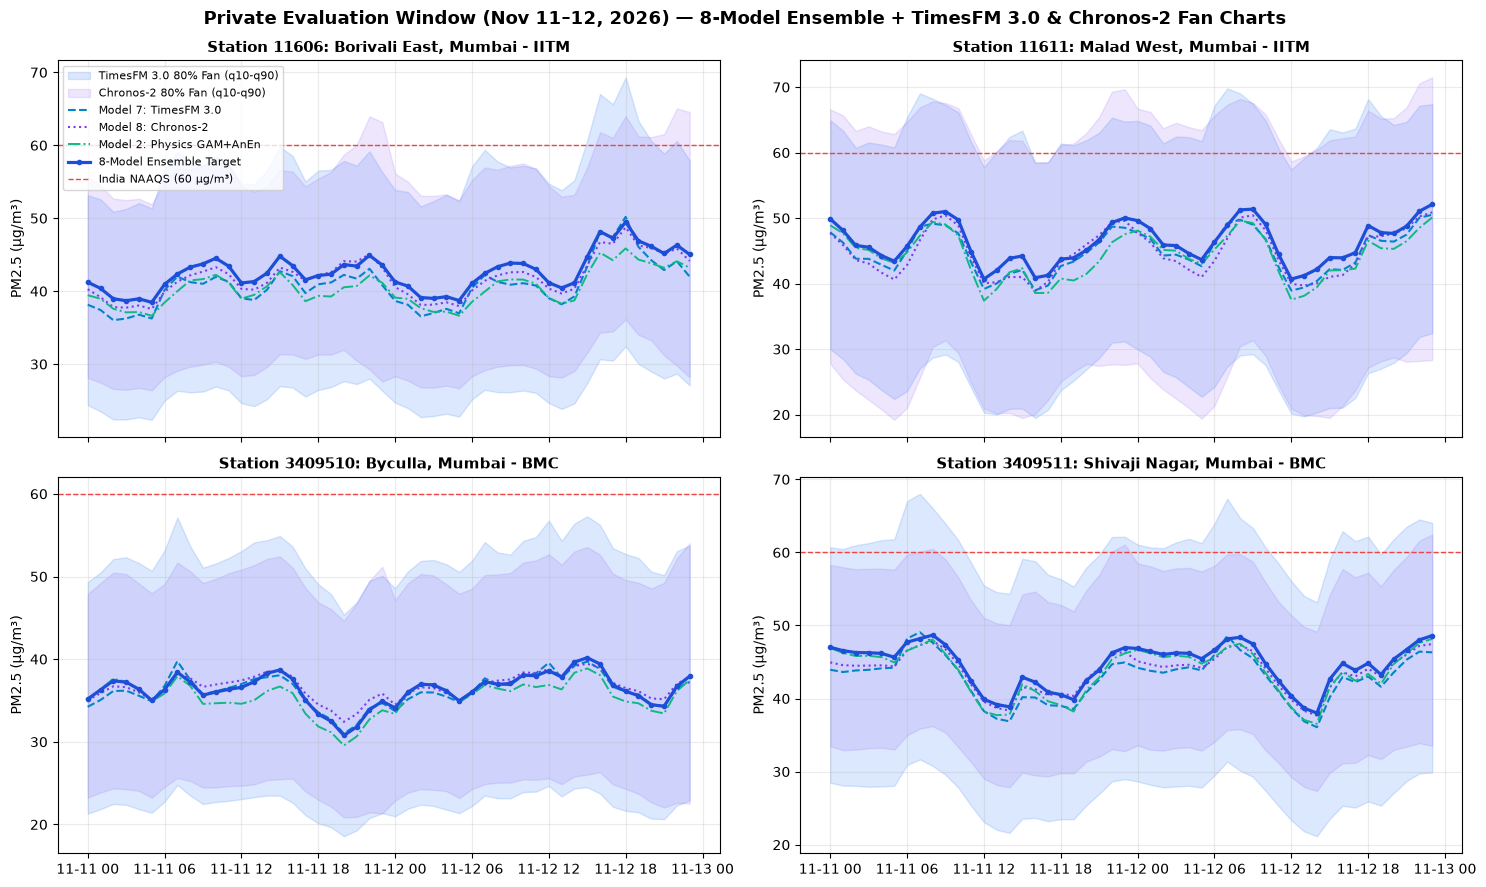

In [5]:
from src.submit import generate_submissions, verify_submission_dataframe

det_path = PROJECT_ROOT / "submissions" / "test_predictions_detailed.parquet"
sub_latest_path = PROJECT_ROOT / "submissions" / "submission_latest.csv"

if det_path.exists() and sub_latest_path.exists():
    sub_df = pd.read_csv(sub_latest_path, dtype={"ID": str})
    detailed_df = pd.read_parquet(det_path)
    if "m7_timesfm3_compact" not in detailed_df.columns:
        sub_df, detailed_df = generate_submissions(n_train_cutoffs=32, step_hours=24)
else:
    sub_df, detailed_df = generate_submissions(n_train_cutoffs=32, step_hours=24)

verify_submission_dataframe(sub_df, sample_sub)
sub_df.to_csv(PROJECT_ROOT / "submission.csv", index=False)
print(f"Verified submission.csv: {len(sub_df):,} rows | Mean Target={sub_df['Target'].mean():.2f} µg/m³")

# Plot Private Evaluation Window (Nov 11-12, 2026) with TimesFM 3.0 & Chronos-2 Quantile Fan Charts
priv_df = detailed_df[detailed_df["scoring_block"] == "private"].copy()
priv_df["hour_start"] = pd.to_datetime(priv_df["hour_start"])

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes = axes.flatten()
for idx, (loc_id, grp) in enumerate(priv_df.groupby("location_id")):
    ax = axes[idx]
    grp = grp.sort_values("hour_start")
    st_title = grp["station_name"].iloc[0]
    if "tfm3_q10" in grp.columns and "tfm3_q90" in grp.columns:
        ax.fill_between(grp["hour_start"], grp["tfm3_q10"], grp["tfm3_q90"], color="#3b82f6", alpha=0.18, label="TimesFM 3.0 80% Fan (q10-q90)")
    if "chronos2_q10" in grp.columns and "chronos2_q90" in grp.columns:
        ax.fill_between(grp["hour_start"], grp["chronos2_q10"], grp["chronos2_q90"], color="#8b5cf6", alpha=0.15, label="Chronos-2 80% Fan (q10-q90)")
    if "m7_timesfm3_compact" in grp.columns:
        ax.plot(grp["hour_start"], grp["m7_timesfm3_compact"], "--", color="#0284c7", lw=1.5, label="Model 7: TimesFM 3.0")
    if "m8_chronos2_covariate" in grp.columns:
        ax.plot(grp["hour_start"], grp["m8_chronos2_covariate"], ":", color="#7c3aed", lw=1.5, label="Model 8: Chronos-2")
    ax.plot(grp["hour_start"], grp["m2_huber_ridge_gam"], "-.", color="#10b981", lw=1.4, label="Model 2: Physics GAM+AnEn")
    ax.plot(grp["hour_start"], grp["Target"], "-o", color="#1d4ed8", lw=2.3, ms=3, label="8-Model Ensemble Target")
    ax.axhline(60.0, color="#ef4444", ls="--", lw=1.0, label="India NAAQS (60 µg/m³)")
    ax.set_title(f"Station {loc_id}: {st_title}", fontsize=11, fontweight="bold")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(fontsize=8, loc="upper left")

plt.suptitle("Private Evaluation Window (Nov 11–12, 2026) — 8-Model Ensemble + TimesFM 3.0 & Chronos-2 Fan Charts", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()